## Introduction

This is a long notebook. The lab questions are at the very end: there are 6 questions, plus 8 optional challenge questions.

Sections marked in <span style="color:red"><b>bold red</b></span> are optional. They give more detail for those who are interested, and you can skip them.

---

# Part 1

### Recap: Bayes' theorem

Bayes' theorem tells us how to combine prior probabilities and likelihoods into the probability of a hypothesis given evidence -- 'has disease' given 'positive test', for example, or 'phoneme /k/ was spoken' given some speech input. Bayesian inference is optimal *relative to its assumptions*: if the priors or likelihoods are wrong, the answer will be wrong too.

The theorem is usually stated as follows:

$$
P(Hypothesis | Evidence) = \frac{P(Evidence | Hypothesis) \times P(Hypothesis)}{P(Evidence)}
$$

where:

- $P(Hypothesis | Evidence)$ is the **posterior probability**: the probability of the hypothesis, given the observed evidence.
- $P(Evidence | Hypothesis)$ is the **likelihood**: the probability of observing the evidence, if the hypothesis is true.
- $P(Hypothesis)$ is the **prior probability**: the probability of the hypothesis before observing any evidence. In the statistical reasoning studies we discussed in class, this was the *base rate* (e.g., how common a disease is in the population). *Prior probability* is the more general term.
- $P(Evidence)$ is the **marginal likelihood**: the total probability of observing the evidence, under all possible hypotheses.

The *hypothesis* is the outcome under consideration (has the disease, the phoneme that was said, the word that was said). The *evidence* is the data or input (the result of a medical test, the speech input).

---

## Hypotheses

What are **hypotheses** in the context of Bayes' Theorem? We talked about them as *outcomes* when we talked about statistical reasoning in class. For statistical reasoning questions, we might ask a seemingly simple question like 'what is the probability of having a disease given a positive test for the disease?' This is a case where we have only 2 possible hypotheses: has the disease or does not have the disease, which we might denote as $D$ vs. $\neg{D}$ (D or not D). We also only consider 2 possible evidence states: positive test or negative test. This is a case we can depict with a simple diagram. 

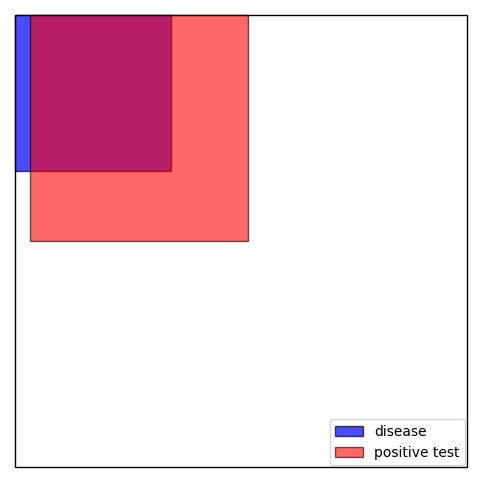

base rate (blue area):                         0.120
hit rate (share of blue that is red):          0.900
false alarm rate (share of white that is red): 0.150
P(disease | positive) (share of red in blue):  0.450


In [1]:
# Draw the population (a 1 x 1 square), the people with the disease (blue), and the people who
# test positive (red), TO SCALE: each area is a proportion of the population.
# Rectangles are (left, top, width, height).
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

side = 0.12 ** 0.5                            # a square with area .12: the base rate
disease = (0, 0, side, side)
positive = (0.1 * side, 0, 0.48, 0.5)          # covers 90% of blue (hit rate) and 15% of white (false alarm rate)

fig, ax = plt.subplots(figsize=(6, 6))
ax.add_patch(Rectangle((0, 0), 1, 1, facecolor='white', edgecolor='black'))
ax.add_patch(Rectangle(disease[:2], disease[2], disease[3], facecolor='blue', alpha=0.7, edgecolor='black', label='disease'))
ax.add_patch(Rectangle(positive[:2], positive[2], positive[3], facecolor='red', alpha=0.6, edgecolor='black', label='positive test'))
ax.set_xlim(-0.01, 1.01)
ax.set_ylim(1.01, -0.01)       # y runs downward, so the blue square sits in the top-left corner
ax.set_aspect('equal')
ax.axis('off')
ax.legend(loc='lower right')
plt.show()

# Read the rates back off the areas (the population has area 1)
blue_area = disease[2] * disease[3]
red_area = positive[2] * positive[3]
overlap = (disease[2] - positive[0]) * disease[3]      # red inside blue: the true positives
print(f'base rate (blue area):                         {blue_area:.3f}')
print(f'hit rate (share of blue that is red):          {overlap / blue_area:.3f}')
print(f'false alarm rate (share of white that is red): {(red_area - overlap) / (1 - blue_area):.3f}')
print(f'P(disease | positive) (share of red in blue):  {overlap / red_area:.3f}')

In this diagram, the white rectangle is the whole population, the blue rectangle is the people who have the disease, and the red rectangle is the people who test positive. Where red overlaps blue, we have *true positives*: people who have the disease **and** test positive. The rest of the red rectangle is *false positives*. The probability of having the disease given a positive test is the share of the red rectangle that overlaps the blue one. The diagram is drawn to scale: each area is a proportion of the population, using the numbers we work with below. The blue square is 12% of the whole square, and red covers 90% of the blue square and 15% of the white area. (The numbers printed under the diagram read these rates back off the areas.)

To calculate this with Bayes' theorem, we need the *base rate* (the prior probability of having the disease), the *hit rate* (the probability of a positive test if you have the disease), and the *false alarm rate* (the probability of a positive test if you do not). Suppose the base rate is 0.12, the hit rate is 0.9, and the false alarm rate is 0.15.

- The **numerator**, $P(Evidence | Hypothesis) \times P(Hypothesis)$, is the hit rate times the base rate: $0.9 \times 0.12 = 0.108$. This is the overlap of red and blue: the probability of having the disease **and** testing positive.
- The **denominator**, $P(Evidence)$, is the probability of a positive test: the whole red rectangle. We already have the part inside the blue rectangle. The part outside it is the false alarm rate times the healthy share of the population, $0.15 \times (1 - 0.12) = 0.132$: the probability of *not* having the disease (1 - the base rate of 0.12) **and** testing positive (based on the 0.15 false alarm rate). Adding the two parts:

$$P(Evidence) = [P(Evidence|Hypothesis) \times P(Hypothesis)] + [P(Evidence|\neg{Hypothesis}) \times P(\neg{Hypothesis})]$$

where $\neg$ means 'not'. Notice the pattern: for each possible hypothesis (has the disease, does not), we multiply the probability of the evidence given that hypothesis by the probability of the hypothesis, and then add up the results.

So $P(Evidence) = 0.108 + 0.132 = 0.240$, and

$$P(Hypothesis \mid Evidence) = \frac{0.108}{0.240} = 0.45$$

That is worth pondering. The test catches 90% of the people who have the disease, and still, fewer than half of the people who test positive actually have it. The reason is that the false alarm rate applies to the 88% of the population who are healthy, and that large group produces more positive tests than the small sick group does.

>Let's review quickly how we would do this using Gigerenzer's frequency format (Gigerenzer & Hoffrage, 1995) from earlier in the semester: 
>  - Suppose we have 1000 people
>  - 120 (estimated) have the disease
>  - 880 do not have the disease
>  - Hit rate tells us to expect 108 with the disease to test positive (90% of 120)
>  - False alarm rate tells us to expect 132 without the disease to test positive (15% of 880)
>  - So 108+132=240 people testing positive, and 108/240 have the disease, so 45% of people testing positive have the disease


Now suppose that coughing is also associated with the disease. We can add another rectangle to the diagram. The next diagram is also drawn to scale, but with different numbers -- the ones we will use in Part 2 -- so the blue square is much smaller:

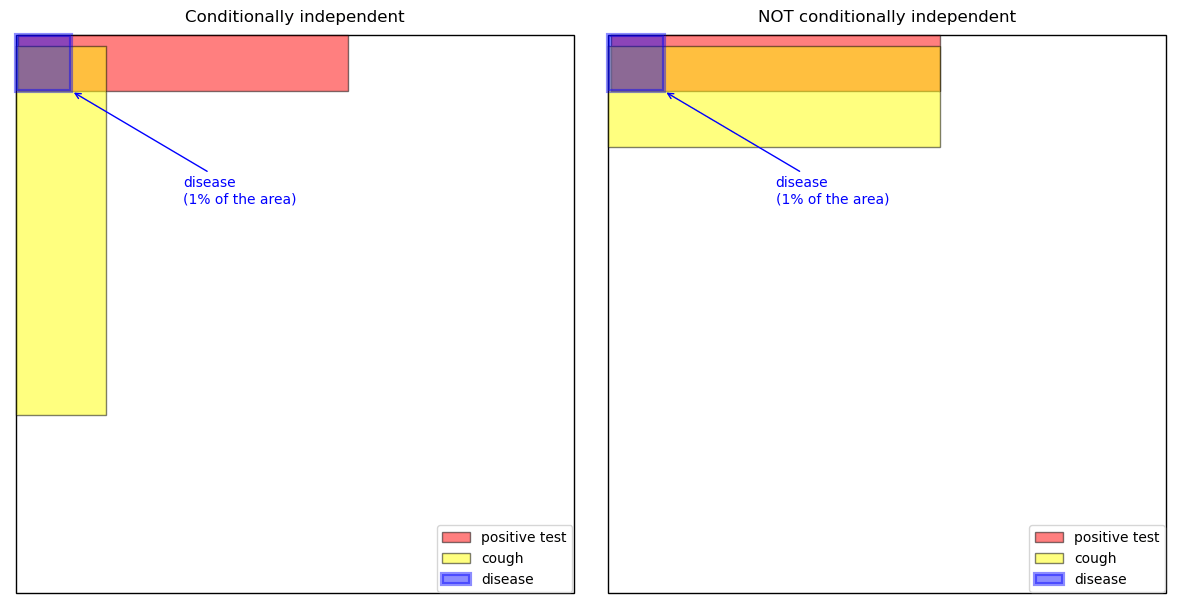

,conditionally independent,not conditionally independent
P(disease),0.010,0.010
P(positive | disease),0.950,0.950
P(positive | no disease),0.050,0.050
P(cough | disease),0.800,0.800
P(cough | no disease),0.100,0.100
P(positive and cough | no disease),0.005,0.040
P(disease | positive and cough),0.605,0.161


In [2]:
# Draw the population (a 1 x 1 square), the people with the disease (blue), the people who test
# positive (red), and the people who cough (yellow), TO SCALE: each area is a proportion of the
# population. Rectangles are (left, top, width, height).
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.patches import Rectangle

disease = (0, 0, 0.1, 0.1)                 # 1% of the area: P(disease) = .01
positive = (0.005, 0, 0.59, 0.1)           # covers 95% of blue and 5% of the white area
cough_independent = (0, 0.02, 0.162, 0.66) # covers 80% of blue and 10% of white ...
cough_dependent = (0, 0.02, 0.594, 0.18)   # ... and so does this one, placed differently


def area(*rects):
    # Area of the overlap of one or more rectangles (0 if they do not all overlap)
    left = max(r[0] for r in rects)
    right = min(r[0] + r[2] for r in rects)
    top = max(r[1] for r in rects)
    bottom = min(r[1] + r[3] for r in rects)
    return max(0, right - left) * max(0, bottom - top)


def rates(cough):
    # Read the probabilities off the areas (the population has area 1)
    p_d = area(disease)
    p_not_d = 1 - p_d
    both_d = area(disease, positive, cough)                            # disease, positive, cough
    both_not_d = area(positive, cough) - both_d                        # no disease, positive, cough
    return {'P(disease)': p_d,
            'P(positive | disease)': area(disease, positive) / p_d,
            'P(positive | no disease)': (area(positive) - area(disease, positive)) / p_not_d,
            'P(cough | disease)': area(disease, cough) / p_d,
            'P(cough | no disease)': (area(cough) - area(disease, cough)) / p_not_d,
            'P(positive and cough | no disease)': both_not_d / p_not_d,
            'P(disease | positive and cough)': both_d / (both_d + both_not_d)}


fig, axes = plt.subplots(1, 2, figsize=(12, 6))
panels = [('Conditionally independent', cough_independent), ('NOT conditionally independent', cough_dependent)]
for ax, (title, cough) in zip(axes, panels):
    ax.add_patch(Rectangle((0, 0), 1, 1, facecolor='white', edgecolor='black'))
    for (left, top, width, height), color, alpha, label in [(positive, 'red', 0.5, 'positive test'),
                                                            (cough, 'yellow', 0.5, 'cough')]:
        ax.add_patch(Rectangle((left, top), width, height, facecolor=color, alpha=alpha, edgecolor='black', label=label))
    # The disease square is tiny (1%), so we draw it last, on top, with a thick outline, and point to it
    left, top, width, height = disease
    ax.add_patch(Rectangle((left, top), width, height, facecolor='blue', alpha=0.45, edgecolor='blue',
                           linewidth=3, label='disease'))
    ax.annotate('disease\n(1% of the area)', xy=(0.1, 0.1), xytext=(0.3, 0.3), color='blue',
                arrowprops=dict(arrowstyle='->', color='blue'))
    ax.set_xlim(-0.01, 1.01)
    ax.set_ylim(1.01, -0.01)       # y runs downward, so the blue square sits in the top-left corner
    ax.set_aspect('equal')
    ax.axis('off')
    ax.set_title(title)
    ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

# The same five rates in both panels -- but not the same joint probabilities
display(pd.DataFrame({'conditionally independent': rates(cough_independent),
                      'not conditionally independent': rates(cough_dependent)}).round(3))

The yellow rectangle represents having a cough. Now we can ask how likely it is that a patient has the disease if they are coughing, or if they are coughing **and** have a positive test.

We will do this formally in the next section, but first think about how you could use the rectangles. With three yes-or-no variables (disease, test, cough), there are 8 possible states (2 x 2 x 2):

1. Have disease, negative test, no cough (only blue)
1. Have disease, positive test, no cough (the portion of the red square that only overlaps with blue)
1. Have disease, negative test, have cough (only blue and yellow overlap)
1. Have disease, positive test, have cough (blue, red, and yellow overlap)
1. No disease, negative test, no cough (white only)
1. No disease, positive test, no cough (red only)
1. No disease, negative test, have cough (yellow only)
1. No disease, positive test, cough (red and yellow)

What ratios of areas would give you the probability of the disease given (a) a cough but a negative test, (b) no cough but a positive test, (c) a positive test and a cough?

As it is drawn, the diagram is **to scale**, using the numbers we will use in Part 2. The base rate is .01: the blue square is 1% of the whole area (it is small!). The test's hit rate is .95 and its false alarm rate .05: red covers 95% of the blue square and 5% of the white area. And 80% of people with the disease cough, but only 10% of people without it: yellow covers 80% of the blue square and 10% of the white area. The table under the diagram reads these rates back off the areas, so you can check them.

The two panels have exactly the same five rates. They differ only in *where* the yellow rectangle sits, and that turns out to matter a lot -- we will come back to this in Part 2.

We can extend Bayes' theorem to many sources of evidence, as we discuss next. 

-------

# Part 2

## Extending Bayes' theorem to multiple sources of evidence

Let's apply Bayes' theorem to a case with two hypotheses and two sources of evidence. We will also move to a more general notation: $n$ hypotheses $H_1$, $H_2$, $\ldots H_n$, and $m$ sources of evidence $E_1$, $E_2$, $\ldots E_m$. 

*Note that even though $H_2$ and $E_2$ have the same number, they are not related; we are just enumerating the hypotheses and evidence sources, incrementing the count as we go.*

### Scenario

1. **Hypotheses**:
    - $ H_1 $: The person has the disease.
    - $ H_2 $: The person does not have the disease.

2. **Evidence**:
    - $ E_1 $: The test result is positive.
    - $ E_2 $: The person is coughing.

#### Prior Probabilities:

- $ P(H_1) $: The prior probability that the person has the disease.
- $ P(H_2) = 1 - P(H_1) $: The prior probability that the person does not have the disease. (With only two hypotheses, their probabilities must sum to 1.) We need $P(H_2)$ even if we only care about $H_1$, because it appears in the denominator of Bayes' theorem. $H_1$ and $H_2$ are just $Hypothesis$ and $\neg{Hypothesis}$ from before; the subscripts let us go beyond two hypotheses later.

#### Likelihoods (probability of evidence given the hypotheses):
- $ P(E_1 \mid H_1) $: Probability of a positive test if the person has the disease (true positives -- for the test).
- $ P(E_1 \mid H_2) $: Probability of a positive test if the person does not have the disease (false positives -- for the test).
- $ P(E_2 \mid H_1) $: Probability of coughing if the person has the disease (true positives -- for coughing).
- $ P(E_2 \mid H_2) $: Probability of coughing if the person does not have the disease (false positives -- for coughing).

### Generalizing Bayes' Theorem

To compute the probability that a person has the disease given a positive test result and coughing, we again use Bayes' theorem, extended to 2 sources of evidence. Let's introduce a new convention, where we will write "$E_1, E_2$" to mean the *joint event* that $E_1$ **and** $E_2$ both occurred. So $P(E_1, E_2)$ is the *joint probability*, the probability that both are true:

$$
P(H_1 \mid E_1, E_2) = \frac{P(E_1, E_2 \mid H_1) P(H_1)}{P(E_1, E_2)}
$$

So we read this as "the probability of $H_1$ *given* that both $E_1$ and $E_2$ occurred is equal to the probability of observing both $E_1$ and $E_2$ *given* $H_1$, multiplied by the probability of $H_1$ -- divided by the probability of observing both $E_1$ *and* $E_2$." 

How do we get the values we need for this? First, the numerator, $ P(E_1, E_2 \mid H_1)$,  is the product of the probabilities of each piece of evidence given the hypothesis:

$$
P(E_1, E_2 \mid H_1) = P(E_1 \mid H_1) P(E_2 \mid H_1)
$$

*There is an assumption hiding in that last line.* We are allowed to multiply the two likelihoods together only if the two sources of evidence are **conditionally independent** given the hypothesis -- that is, once we know whether the person has the disease, learning the test result tells us nothing more about whether they are coughing. That is a strong assumption, and often it *may not be valid*. 

>Look back at the two panels of the second rectangle diagram. They have exactly the same five rates; only the position of the yellow rectangle (cough) differs.
>
>**How to test for conditional independence.** Look at one group at a time.
>
>1. Take only the people *with* the disease. What share of the coughers test positive? What share of the non-coughers test positive?
>2. If the two shares are the same, coughing tells you nothing about the test result in this group. If they differ, it does.
>3. Do the same for the people *without* the disease.
>
>If the shares match in both groups, the two pieces of evidence are conditionally independent. If they differ in either group, they are not. In the diagram, 'the share of coughers who test positive' is how much of the yellow is red, and 'the share of non-coughers who test positive' is how much of the rest is red. Check both inside the blue square and in the white area:
>
>- **Left: conditionally independent.** Inside the blue square (people with the disease), red covers 95% of the yellow part and 95% of the rest. Outside the blue square, red covers 5% of the yellow part and 5% of the rest. So once you know whether someone has the disease, knowing whether they cough tells you nothing more about their test result.
>- **Right: not conditionally independent.** Outside the blue square, the yellow rectangle runs along the red strip, so red covers about 40% of the yellow there, but only about 1% of the rest of the white area. Among people without the disease, coughers are much more likely to test positive than non-coughers (think of a cold that causes both a cough and a false positive). Knowing whether someone coughs tells you something about their test result, even when you already know they do not have the disease.
>
>Multiplying the likelihoods gives the right answer only for the left panel: below, we will get about .61. For the right panel, the correct answer, which we can read off the areas (the last row of the table under the diagram), is only about .16, because most of the people who test positive *and* cough are healthy people with colds.
>
>**What if the evidence is not conditionally independent?** Then we cannot multiply the separate likelihoods. Bayes' theorem itself never needed independence: we just need the *joint* likelihood, $P(E_1, E_2 \mid H)$, for each hypothesis. There are two standard ways to get it.
>
>- *The chain rule:* $P(E_1, E_2 \mid H) = P(E_1 \mid H)\,P(E_2 \mid E_1, H)$. Instead of 'how often do people with the disease cough?', we need 'how often do people with the disease *who test positive* cough?' -- which we can estimate by counting all four combinations of test result and cough within each group. In the right panel, the joint probability for healthy people, read off the areas, is .040, not .05 × .10 = .005, and using it gives the correct posterior of .16.
>- *Modeling the hidden cause:* evidence is usually correlated because something we have not represented affects both pieces of it (in our story, a cold makes healthy people cough *and* test positive). We can add that cause to the model as another variable. The clues are often independent given both the hypothesis *and* the cause, so we can multiply within each case and then average over the possible causes. This is the idea behind *Bayesian networks*.
>
>The cost is always the same: the model needs more probabilities, estimated from more data. That is why the independence shortcut is so tempting. In speech, too, the evidence at neighboring positions is not really independent -- each sound is shaped by its neighbors (*coarticulation*) -- and speech recognition systems handle this the first way, by making each sound's probabilities depend on its context.
>
>We will make the same kind of independence assumption again later, for the speech input at each position within a word, where it is just as convenient and just as questionable.

We need the same assumption for $H_2$, to compute the denominator. 
The denominator is the total probability of the evidence, calculated as:

$$
P(E_1, E_2) = P(E_1, E_2 \mid H_1) P(H_1) + P(E_1, E_2 \mid H_2) P(H_2)
$$

### Extension to many sources of evidence

We can extend this to arbitrarily many sources of evidence ($E_1 \ldots E_m$, where $m$ is the number of evidence sources) with a little rewriting: 


$$
P(H_1 \mid E_1, \ldots E_m) = \frac{P(E_1, \ldots E_m \mid H_1) P(H_1)}{P(E_1, \ldots E_m)}
$$

If the evidence sources are conditionally independent given each hypothesis, the likelihood is a product, $P(E_1, \ldots E_m \mid H_1) = \prod_{k=1}^{m} P(E_k \mid H_1)$. And with $n$ hypotheses rather than 2, the denominator sums over all of them:

$$
P(E_1, \ldots E_m) = \sum_{k=1}^{n} P(E_1, \ldots E_m \mid H_k) P(H_k)
$$

## Example

Let’s consider an example with some specific values:

- $ P(H_1) = 0.01 $ (1% of people have the disease)
- $ P(E_1 \mid H_1) = 0.95 $ (95% hit rate)
- $ P(E_1 \mid H_2) = 0.05 $ (5% false-positive rate)
- $ P(E_2 \mid H_1) = 0.8 $ (80% of people with the disease cough)
- $ P(E_2 \mid H_2) = 0.1 $ (10% of people without the disease cough)

To find the posterior probability that the person has the disease given that they tested positive and are coughing:

**1. **Numerator** for $ P(H_1 \mid E_1, E_2) $:**

$$
P(E_1, E_2 \mid H_1) P(H_1) = (0.95 \times 0.8) \times 0.01 = 0.0076
$$

**2. **Denominator**:**

- For $ H_1 $: $ P(E_1, E_2 \mid H_1) P(H_1) = 0.0076 $
- For $ H_2 $: $ P(E_1, E_2 \mid H_2) P(H_2) = (0.05 \times 0.1) \times 0.99 = 0.00495 $

So:

$$
P(E_1, E_2) = 0.0076 + 0.00495 = 0.01255
$$

**3. Posterior Probability:**

$$
P(H_1 \mid E_1, E_2) = \frac{0.0076}{0.01255} \approx 0.605
$$

Thus, there is about a 60.5% chance that the person has the disease given both the positive test result and that they are coughing.

Calculating this by hand gets tedious quickly. The code later in this notebook does the same computation for thousands of hypotheses (words) at once.

-------

# Part 3

### Extending to many sources of non-discrete evidence

So far our evidence has been binary: the test is positive or negative, the person coughs or does not. Speech sounds are richer. Linguists describe phonemes with sets of features. (Formal distinctive-feature systems use features like [±continuant] and [±coronal]; to keep things readable, we will treat familiar phonetic labels like 'stop' and 'bilabial' as if they were binary features.) The phoneme /p/, for example, is +stop, +bilabial, -alveolar, -voiced, -sonorant, -continuant. The phoneme /b/ is the same *except* that it is +voiced. If we code + as 1 and - as 0, /p/ is 110**0**00 and /b/ is 110**1**00. The two vectors are similar, especially compared with /s/ (-stop, -bilabial, +alveolar, -voiced, -sonorant, +continuant), or 001001. (Notice that 'stop' and 'continuant' are redundant here: for these phonemes, +stop always goes with -continuant and vice versa, so the two features count the same difference twice. Redundant features like this push similarity up or down in ways worth noticing.)

How should we compare vectors like these? One option is **Euclidean distance**: the length of the straight line from one vector's 'address' in $n$-dimensional space to the other's. Another is **cosine similarity**. We will look at cosine similarity first, and then come back to Euclidean distance, which is what our model will use from Part 5 on. In trigonometry, the cosine of an angle in a right triangle is the ratio of the adjacent side to the hypotenuse. Because the hypotenuse is always the longest side, the cosine is never more than 1, and it is exactly 1 only when the angle is 0. The same idea extends to vectors. Time for a tangent (no pun intended)...

#### Vector cosine (cosine similarity)

First, let's be precise about what a **vector** is. We can think of it just as a series of numbers, but we can do more interesting things when we think of each element in a vector as a *dimension*. Then we can think of a vector as having both **direction** and **magnitude** (or length). Imagine an arrow pointing somewhere. The length of the arrow is the magnitude, and the direction it points (relative to its originating point) is, well, the direction.

For example, in 2D space, a vector might look like this: $ \mathbf{v} = (x_1, y_1) $, where $x_1$ and $y_1$ are the coordinates. So if $x_1$ is 3 and $y_1$ is 4, we move out 3 units on the x axis from 0 and then up 4 units on the y axis from 0, and then we consider the vector to describe the straight line that would go from 0,0 to 3,4. It has an angle relative to the x and y axes (which specifies the direction it points) and a length (which is how far it extends along that angle).

Now, **cosine similarity** is a way to measure how similar two vectors are in terms of their direction (*not in terms of length at all*). The more two vectors point in the same direction, the closer their cosine similarity is to 1. If they point in exactly opposite directions, the cosine similarity will be -1. If they are at a 90-degree angle (perpendicular), the cosine similarity will be 0.

#### Math behind vector cosine

<span style="color:red"><b>OPTIONAL: you can skip ahead to *Interpreting cosine similarity*. It is here for those who are interested.</b></span>


The cosine of the angle between two vectors, $ \mathbf{v} $ and $ \mathbf{w} $, is calculated using this formula:

$$
\cos(\theta) = \frac{\mathbf{v} \cdot \mathbf{w}}{\|\mathbf{v}\| \|\mathbf{w}\|}
$$

Here’s what this means:
- $ \mathbf{v} \cdot \mathbf{w} $ is the **dot product** of the two vectors. This is a special way to multiply vectors, where you multiply their corresponding parts and add them up. If $ \mathbf{v} = (x_1, y_1) $ and $ \mathbf{w} = (x_2, y_2) $, the dot product is:

  $$
  \mathbf{v} \cdot \mathbf{w} = x_1 \cdot x_2 + y_1 \cdot y_2
  $$

- $ \|\mathbf{v}\| $ and $ \|\mathbf{w}\| $ are the **magnitudes** (or lengths) of the vectors. To find the magnitude of a vector $ \mathbf{v} = (x_1, y_1) $, we use:

  $$
  \|\mathbf{v}\| = \sqrt{x_1^2 + y_1^2}
  $$

So, the formula for cosine similarity gives you a value between -1 and 1 that tells you how much the two vectors are pointing in the same direction.

#### Example with 3 vectors

Let’s say you have 3 vectors:

$$
\mathbf{v} = (1, 2), \quad \mathbf{w} = (2, 4), \quad \mathbf{u} = (3, 1)
$$

**1. Cosine Similarity Between $ \mathbf{v} $ and $ \mathbf{w} $**

First, we find the dot product of $ \mathbf{v} $ and $ \mathbf{w} $:

$$
\mathbf{v} \cdot \mathbf{w} = 1 \cdot 2 + 2 \cdot 4 = 2 + 8 = 10
$$

Next, we find the magnitudes of each vector:

$$
\|\mathbf{v}\| = \sqrt{1^2 + 2^2} = \sqrt{1 + 4} = \sqrt{5}
$$
$$
\|\mathbf{w}\| = \sqrt{2^2 + 4^2} = \sqrt{4 + 16} = \sqrt{20}
$$

Now we can calculate the cosine similarity:

$$
\cos(\theta_{\mathbf{v}, \mathbf{w}}) = \frac{10}{\sqrt{5} \times \sqrt{20}} = \frac{10}{\sqrt{100}} = \frac{10}{10} = 1
$$

Since the cosine is 1, these two vectors are pointing in exactly the same direction (we'll plot them below).

**2. Cosine Similarity Between $ \mathbf{v} $ and $ \mathbf{u} $**

Now, let’s calculate the cosine similarity between $ \mathbf{v} $ and $ \mathbf{u} $.

First, we compute the dot product:

$$
\mathbf{v} \cdot \mathbf{u} = 1 \cdot 3 + 2 \cdot 1 = 3 + 2 = 5
$$

Next, we find the magnitude of $ \mathbf{u} $:

$$
\|\mathbf{u}\| = \sqrt{3^2 + 1^2} = \sqrt{9 + 1} = \sqrt{10}
$$

Now, we calculate the cosine similarity, using the magnitude of $\mathbf{v}$ from before:

$$
\cos(\theta_{\mathbf{v}, \mathbf{u}}) = \frac{5}{\sqrt{5} \times \sqrt{10}} = \frac{5}{\sqrt{50}} = \frac{5}{7.07} \approx 0.707
$$

Since the cosine is less than 1, the vectors $ \mathbf{v} $ and $ \mathbf{u} $ are not pointing in the same direction but are not extremely different. 

**3. Cosine Similarity Between $ \mathbf{w} $ and $ \mathbf{u} $**

Last, let’s calculate the cosine similarity between $ \mathbf{w} $ and $ \mathbf{u} $. Can you predict what the outcome will be?

First, we compute the dot product:

$$
\mathbf{w} \cdot \mathbf{u} = 2 \cdot 3 + 4 \cdot 1 = 6 + 4 = 10
$$

Now, we calculate the cosine similarity:

$$
\cos(\theta_{\mathbf{w}, \mathbf{u}}) = \frac{10}{\sqrt{20} \times \sqrt{10}} = \frac{10}{\sqrt{200}} = \frac{10}{14.14} \approx 0.707
$$

This is the same result as between $ \mathbf{v} $ and $ \mathbf{u} $, indicating that $ \mathbf{w} $ and $ \mathbf{u} $ also form about a 45-degree angle between them. We could have predicted this since we already knew that the cosine for $ \mathbf{v} $ and $ \mathbf{w} $ was 1.0.

### Interpreting cosine similarity

- A value of 1.0 indicates perfect alignment: the two vectors point in the same direction.
- A value of -1.0 indicates that the two vectors point in exactly opposite directions.
- A value of 0.0 indicates the vectors are **orthogonal**. In the 2d case, the two vectors would be perpendicular. If we had a vector of 1s and 0s, like [0 1 0], we can create an orthogonal vector by replacing 1s with 0s and vice versa: [1 0 1]. If you calculate the dot product, you can see why... 
- Values between 1.0 and 0 or -1.0 and 0 indicate how similar the vectors are in a graded fashion.

So higher positive cosines mean more similar directions, and negative cosines mean that the vectors point in opposing directions. Remember that cosine ignores length: just as (1, 2) and (2, 4) have a cosine of 1.0, so does any pair of positive 2-element vectors on the line $y = 2x$, such as (0.01, 0.02) and (1005, 2010).

### Visualizing

Let's plot our 3 example vectors, along with a new vector, $\mathbf{d}$, which points away from the others (its cosine similarity to $\mathbf{v}$ is approximately -0.89). The code cell below just defines the vectors 'by hand' (they are 'hard coded') and makes a plot. The plot may look a little 3-dimensional, but it's just 2 dimensions. 

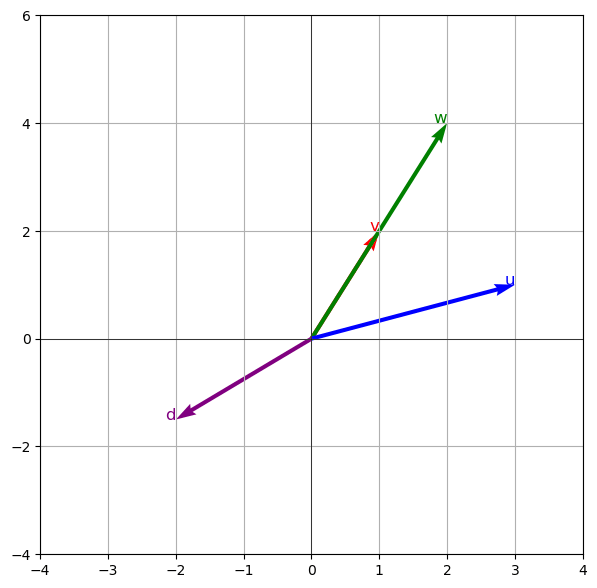

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Define the vectors
v = np.array([1, 2])
w = np.array([2, 4])       # same direction as v, twice as long
u = np.array([3, 1])
d = np.array([-2, -1.5])   # points mostly away from v (cosine with v is about -0.89)

plt.figure(figsize=(7, 7))

# Draw each vector as an arrow from the origin (0, 0) to its point, and label it.
# quiver(x_start, y_start, x_change, y_change) draws an arrow; the three scale settings
# make the arrow end exactly at the vector's point on the plot's axes.
for name, vector, color in [('v', v, 'r'), ('w', w, 'g'), ('u', u, 'b'), ('d', d, 'purple')]:
    plt.quiver(0, 0, vector[0], vector[1], angles='xy', scale_units='xy', scale=1, color=color)
    plt.text(vector[0], vector[1], name, fontsize=12, color=color, ha='right')

# Set limits, axes, and grid
plt.xlim(-4, 4)
plt.ylim(-4, 6)
plt.axhline(0, color='black', linewidth=0.5)
plt.axvline(0, color='black', linewidth=0.5)
plt.grid(True)
plt.show()

## Applying vector cosine for phonemes

Okay, let's go back to our vectors for phonemes. Recall that we had the features stop, bilabial, alveolar, voiced, sonorant, and continuant for our example, and that the vectors for /p/, /b/, and /s/ would be 110000, 110100 and 001001, respectively. Let's add one more vector, for the phoneme /z/, which only differs from /s/ in that it is +voiced: 001101. Let's make a function that calculates vector cosine and calculate the cosines for these 4 vectors. 


In [4]:
import numpy as np
import pandas as pd

# Function to compute cosine similarity between two vectors
def cosine_similarity(v, w):
    # Error checking: Ensure vectors have the same length
    if len(v) != len(w):
        raise ValueError("Vectors must have the same length")
    
    # Convert to numpy arrays for easy computation
    v = np.array(v)
    w = np.array(w)
    
    # Compute the dot product
    dot_product = np.dot(v, w)
    
    # Compute the magnitudes (norms) of the vectors
    v_magnitude = np.linalg.norm(v)
    w_magnitude = np.linalg.norm(w)
    
    # Error checking: Ensure we do not divide by zero
    if v_magnitude == 0 or w_magnitude == 0:
        raise ValueError("One or both vectors have zero magnitude, cannot compute cosine similarity")
    
    # Compute cosine similarity
    cosine_sim = dot_product / (v_magnitude * w_magnitude)
    return cosine_sim

# Function to create a cosine similarity table
def create_cosine_table(vectors):
    cosine_table = {}
    for name1, vec1 in vectors.items():
        cosine_table[name1] = {}
        for name2, vec2 in vectors.items():
            cosine_table[name1][name2] = cosine_similarity(vec1, vec2)
    
    # Convert the cosine similarity table to a DataFrame
    cosine_df = pd.DataFrame(cosine_table)
    return cosine_df

# Define the vectors p, b, s, and z
p = [1, 1, 0, 0, 0, 0]
b = [1, 1, 0, 1, 0, 0]
s = [0, 0, 1, 0, 0, 1]
z = [0, 0, 1, 1, 0, 1]

# Create a list of vector names and vectors for pairwise comparison
vectors = {'p': p, 'b': b, 's': s, 'z': z}

# Create and print the cosine similarity table
cosine_df = create_cosine_table(vectors)
print(cosine_df)


          p         b         s         z
p  1.000000  0.816497  0.000000  0.000000
b  0.816497  1.000000  0.000000  0.333333
s  0.000000  0.000000  1.000000  0.816497
z  0.000000  0.333333  0.816497  1.000000


First, of course the cosines comparing a vector to itself are always 1.0; we see those values on the diagonal -- these are the *identity* comparisons. Note also that the matrix is symmetrical: the top row from left to right is identical to the first column from top to bottom, etc. So we can just look at the 'upper' or 'lower' triangles of values, or whichever one is more convenient when we are examining the table (do you see why the upper and lower triangle values have to be the same?).

We see a high cosine between /p/ and /b/, and an identical cosine between /z/ and /s/. Can you explain why they have the same value? 

Also, we see that the cosine between /s/ and /p/ is 0, as is the cosine between /s/ and /b/. This is because /s/ has its '1' values only in positions that contain 0 for /p/ and /b/. The cosine for /z/ and /p/ is 0 for the same reason. But the cosine between /z/ and /b/ is greater than 0 because they share the +voiced feature. 

Notice what this coding implies, though: /p/ and /s/ are both -voiced and -sonorant, yet those shared values contribute nothing, because $0 \times 0 = 0$. With 0/1 coding, cosine only counts shared *presence* of features. An alternative is to code '-' as -1 instead of 0, so that shared minus values add to similarity. (Try it: what is the /p/-/s/ cosine with $\pm 1$ coding?) Now we could extend this approach to a much larger feature set -- and we will later. 

### Euclidean distance

Cosine similarity asks whether two vectors point in the same *direction*. **Euclidean distance** asks a different question: how far apart are the *points* that the two vectors lead to? Picture each vector as an address in space -- the tip of its arrow -- and measure the straight line from one tip to the other with a ruler. That length is the Euclidean distance. (It is the ordinary, 'as the crow flies' distance, named after the Greek mathematician Euclid.)

Two differences from cosine are worth noticing right away. First, it is a *distance*, not a similarity: 0 means identical, and *bigger* numbers mean *less* similar. Second, it depends on length as well as direction: two arrows that point the same way but have different lengths end at different points, so they are some distance apart.

#### Math behind Euclidean distance

<span style="color:red"><b>OPTIONAL: you can skip ahead to *Interpreting Euclidean distance*. It is here for those who are interested.</b></span>

For two 2-D vectors $\mathbf{v} = (x_1, y_1)$ and $\mathbf{w} = (x_2, y_2)$, the Euclidean distance is the Pythagorean theorem: the line from one tip to the other is the hypotenuse of a right triangle whose sides are the differences in $x$ and in $y$:

$$
d(\mathbf{v}, \mathbf{w}) = \sqrt{(x_1 - x_2)^2 + (y_1 - y_2)^2}
$$

With $n$ dimensions, we just add up more terms:

$$
d(\mathbf{v}, \mathbf{w}) = \sqrt{\sum_{i=1}^{n} (v_i - w_i)^2}
$$

In words: for each dimension, take the difference, square it (so that negative differences count as much as positive ones), add up the squares, and take the square root. Sometimes we skip the last step and use the **squared Euclidean distance**, $\sum_{i} (v_i - w_i)^2$. Squaring changes the numbers but not their order (whatever is farther stays farther), and it is the version our model will use in Part 5.

#### Example with the same 3 vectors

$$
\mathbf{v} = (1, 2), \quad \mathbf{w} = (2, 4), \quad \mathbf{u} = (3, 1)
$$

**1. Distance between $\mathbf{v}$ and $\mathbf{w}$**

$$
d(\mathbf{v}, \mathbf{w}) = \sqrt{(1 - 2)^2 + (2 - 4)^2} = \sqrt{1 + 4} = \sqrt{5} \approx 2.24
$$

**2. Distance between $\mathbf{v}$ and $\mathbf{u}$**

$$
d(\mathbf{v}, \mathbf{u}) = \sqrt{(1 - 3)^2 + (2 - 1)^2} = \sqrt{4 + 1} = \sqrt{5} \approx 2.24
$$

**3. Distance between $\mathbf{w}$ and $\mathbf{u}$**

$$
d(\mathbf{w}, \mathbf{u}) = \sqrt{(2 - 3)^2 + (4 - 1)^2} = \sqrt{1 + 9} = \sqrt{10} \approx 3.16
$$

Compare these with the cosines. Cosine said that $\mathbf{v}$ and $\mathbf{w}$ are identical (1.0) and that $\mathbf{v}$ and $\mathbf{u}$ are less similar (0.707). Euclidean distance says that $\mathbf{v}$ is exactly as far from $\mathbf{w}$ as from $\mathbf{u}$! Both are right; they measure different things. $\mathbf{v}$ and $\mathbf{w}$ point in the same direction, but their tips are in different places.

### Interpreting Euclidean distance

- A value of 0 means the two vectors are identical: they lead to the same point. That is the only way to get 0.
- Bigger values mean less similar. There is no upper limit; how big distances get depends on the scale of the dimensions.
- Distances are never negative, and there is no special value for 'opposite', as there is for cosine (-1.0). Vectors that point in opposite directions are simply far apart.
- Length matters. (1, 2) and (2, 4) are 2.24 apart, and (0.01, 0.02) and (1005, 2010) are about 2,247 apart -- even though every one of these pairs has a cosine of 1.0.

### Visualizing

Here are the same four vectors again, with the Euclidean distance from the tip of $\mathbf{v}$ to the tips of $\mathbf{w}$, $\mathbf{u}$, and $\mathbf{d}$ drawn as dashed lines. (The line from $\mathbf{v}$ to $\mathbf{w}$ runs right along $\mathbf{w}$'s own arrow, because the two point the same way: same direction, but the tips are still 2.24 apart.)

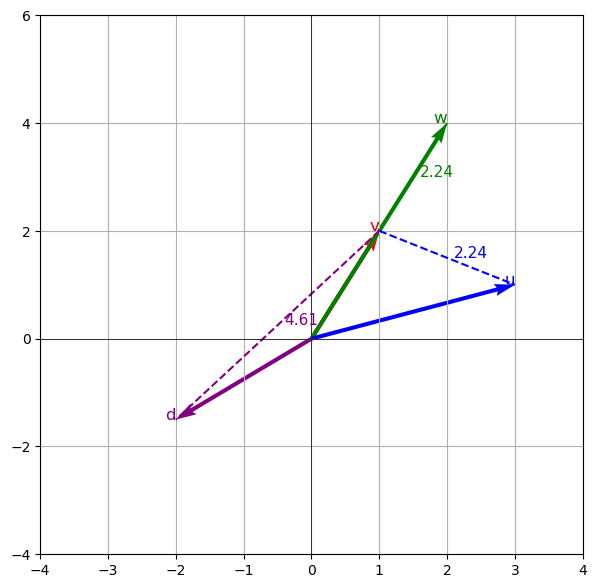

In [5]:
# The same four vectors as before (v, w, u, d were defined in the earlier plotting cell),
# with the Euclidean distance from the tip of v to the other tips drawn as dashed lines
plt.figure(figsize=(7, 7))
for name, vector, color in [('v', v, 'r'), ('w', w, 'g'), ('u', u, 'b'), ('d', d, 'purple')]:
    plt.quiver(0, 0, vector[0], vector[1], angles='xy', scale_units='xy', scale=1, color=color)
    plt.text(vector[0], vector[1], name, fontsize=12, color=color, ha='right')

for other, color in [(w, 'g'), (u, 'b'), (d, 'purple')]:
    # a dashed line from the tip of v to the tip of the other vector
    plt.plot([v[0], other[0]], [v[1], other[1]], linestyle='--', color=color)
    # the length of that line, written next to its middle
    distance = np.sqrt(np.sum((v - other) ** 2))
    middle = (v + other) / 2
    plt.text(middle[0] + 0.1, middle[1], f'{distance:.2f}', fontsize=11, color=color)

plt.xlim(-4, 4)
plt.ylim(-4, 6)
plt.axhline(0, color='black', linewidth=0.5)
plt.axvline(0, color='black', linewidth=0.5)
plt.grid(True)
plt.show()

## Applying Euclidean distance to phonemes

Now let's compute Euclidean distances for our four phoneme vectors, /p/, /b/, /s/, and /z/ (defined in the cosine code above), in the same kind of table.

In [6]:
# Function to compute the Euclidean distance between two vectors
def euclidean_distance(v, w):
    # Error checking: Ensure vectors have the same length
    if len(v) != len(w):
        raise ValueError("Vectors must have the same length")

    # Convert to numpy arrays for easy computation
    v = np.array(v)
    w = np.array(w)

    # For each dimension, the difference; square the differences, add them up, take the square root
    differences = v - w
    return np.sqrt(np.sum(differences ** 2))

# Function to create a distance table
def create_distance_table(vectors):
    distance_table = {}
    for name1, vec1 in vectors.items():
        distance_table[name1] = {}
        for name2, vec2 in vectors.items():
            distance_table[name1][name2] = euclidean_distance(vec1, vec2)
    return pd.DataFrame(distance_table)

# The same vectors p, b, s, and z as in the cosine table
vectors = {'p': p, 'b': b, 's': s, 'z': z}
distance_df = create_distance_table(vectors)
print('Euclidean distance:')
print(distance_df.round(2))
print('\nCosine similarity (from before), for comparison:')
print(create_cosine_table(vectors).round(2))

Euclidean distance:
      p     b     s     z
p  0.00  1.00  2.00  2.24
b  1.00  0.00  2.24  2.00
s  2.00  2.24  0.00  1.00
z  2.24  2.00  1.00  0.00

Cosine similarity (from before), for comparison:
      p     b     s     z
p  1.00  0.82  0.00  0.00
b  0.82  1.00  0.00  0.33
s  0.00  0.00  1.00  0.82
z  0.00  0.33  0.82  1.00


The diagonal is now 0 instead of 1: every phoneme is at distance 0 from itself. /p/ and /b/, and /s/ and /z/, are 1 apart: they differ in one feature (voicing), so one squared difference of 1. /p/ and /s/ are 2 apart: they differ in four features, and $\sqrt{4} = 2$. In fact, with 0/1 features, the *squared* Euclidean distance is simply the number of features on which two phonemes differ.

### Comparing cosine similarity and Euclidean distance

Look at the two tables side by side.

- **Cosine lumps together pairs that Euclidean distance tells apart.** Cosine gives /p/-/s/, /p/-/z/, and /b/-/s/ all the same value, 0. Euclidean distance puts /p/-/s/ at 2.00 but /p/-/z/ and /b/-/s/ farther apart, at 2.24, because those pairs also differ in voicing.
- **The two treat shared *absences* differently.** Cosine says /b/-/z/ (0.33) is more similar than /p/-/s/ (0): /b/ and /z/ share +voiced, while /p/ and /s/ share only -voiced and -sonorant, which, as we saw, contribute nothing to a cosine with 0/1 coding. Euclidean distance puts the two pairs at the same distance (2.00), because both differ in four features: a shared 0 counts as a match just as much as a shared 1.

| | Cosine similarity | Euclidean distance |
|---|---|---|
| What it measures | whether two vectors point the same way (the angle between them) | how far apart their tips are |
| Identical vectors | 1 | 0 |
| More similar means | bigger | smaller |
| Range | -1 to 1 | 0 to no upper limit |
| Does length matter? | no | yes |
| Shared 0s (with 0/1 coding) | count for nothing | count as matches |

**How are they related?** If all the vectors have the same length $L$, the two measures always agree about which pairs are more similar, because then the squared distance is just a rescaled cosine: $d^2 = 2L^2(1 - \cos)$. They can disagree only when vectors differ in length -- as $\mathbf{v}$ and $\mathbf{w}$ do, and as our phoneme vectors do (/p/ has two 1s, /b/ has three).

**Which should we use?** It depends on what the numbers mean. If only the *pattern* matters and overall size is a nuisance (counts of words in long vs. short documents, say), cosine is a good choice. If each value is an amount that matters, and especially if we think of an input as a point that *noise* moves around in space, distance is the natural choice. In Part 4 we will start with cosine, because it is simple. From Part 5 on, our model treats each input as a feature vector plus noise, and uses squared Euclidean distance.

-------

## Part 4

### A Bayesian approach to evaluating phoneme inputs

We are finally ready to return to thinking about how we would extend Bayes' theorem to these kinds of cases. Our feature vectors for each phoneme represent the canonical hypothesis for the features that should be present when the input corresponds to that phoneme. So we want to say that the set of hypotheses is the phoneme inventory: we will assume we are only getting speech input, and the only possible sounds correspond to the ~40 phonemes of English. 

For now, let's do an example where we assume that we only have the phonemes /p/, /b/, /s/, and /z/, and suppose we get an input that does not perfectly match any of these, maybe a pattern like this: 

$$[0.8, 0.7, 0.4, 0.5, 0.2, 0.3]$$

What could this vector mean? It might mean that we have evidence that is 80% consistent with the feature stop, 70% consistent with the feature bilabial, 40% consistent with alveolar, 50% consistent with voiced, 20% consistent with sonorant, and 30% with continuant. Now how do we evaluate how consistent this evidence vector is with our 4 hypotheses (phonemes)? While there are other alternatives, the most straightforward thing we can do is calculate similarity between that input vector and each of our phonemes. Let's do that in the code block below, by adding a vector called `input`.



In [ ]:
# everything else we need was done in previous code blocks;
# we will add the input vector and then calculate all the 
# pairwise cosines and print the table

# (named input_vector, not input -- `input` is a Python builtin, and
# shadowing it breaks any later call to input() in this kernel)
input_vector = [0.8, 0.7, 0.4, 0.5, 0.2, 0.3]

# Create a list of vector names and vectors for pairwise comparison
vectors = {'p': p, 'b': b, 's': s, 'z': z, 'input': input_vector}

# Create and print the cosine similarity table
cosine_df = create_cosine_table(vectors)
print(cosine_df)

All we care about is the final column (or bottom row, since they have identical values). We see that the input is somewhat similar to all our categories. But these similarities are not the probabilities of the phonemes: they do not sum to 1 across our four phonemes, and nothing forces them to. What we want is, for each phoneme (i.e., each hypothesis), the probability of that phoneme given the input -- a set of numbers that *does* sum to 1. Bayes' theorem will get us there. 

Let's look again at the formula for Bayes' theorem for $m$ evidence elements: 

$$
P(H_1 \mid E_1,\ldots E_m) = \frac{P(E_1,\ldots E_m \mid H_1) P(H_1)}{P(E_1,\ldots E_m)}
$$

But guess what? Instead of considering each $E$ separately, we can instead replace the likelihood $P(E_1,\ldots E_m \mid H_j)$ with the **similarity** between each phoneme's defined pattern and the input pattern. Let's walk through the logic of this.


**Likelihoods**: Instead of calculating conventional likelihood values ($P(E|H)$), we will use **cosine similarity** as a measure of how similar the input is to each phoneme’s canonical vector. That is, we use a single similarity score in place of the probability of the whole input vector given the phoneme. 

**Prior**: However, we still need *prior probability* values ($P(H)$) for each phoneme. We will get these from a real language corpus later, but for our example, let's just make up some values. If we are describing the probability of each phoneme over all occurrences of any phoneme, then when we add together the priors for all our phonemes, the result must be 1.0. So let's say that the priors for /p/, /b/, /s/, and /z/, respectively are 0.2, 0.4, 0.1, and 0.3. 


**Posterior**: Now we are ready to calculate the posterior probabilities of each phoneme using Bayes' theorem.

#### Bayesian Update Using Cosine Similarity

- Let $ H_j $ represent the $j^{th}$ phoneme.
- Let $ \mathbf{v_j} $ be the canonical vector for phoneme $ H_j $.
- Let $ \mathbf{i} $ be the input vector.
- $ P(H_j) $ is the prior probability of phoneme $ H_j $.

Now we substitute the cosine similarity between the input vector and each phoneme’s vector as approximating the likelihood:

$$
P(\mathbf{i} \mid H_j) \approx \cos({\mathbf{v_j}, \mathbf{i}})
$$

Let's simplify this and allow for the possibility that we might use another similarity metric, and instead say the following, where $sim$ is whatever similarity metric we choose:

$$
P(\mathbf{i} \mid H_j) \approx {sim}({\mathbf{v_j}, \mathbf{i}})
$$

Now, applying Bayes' theorem:

$$
P(H_j \mid \mathbf{i}) = \frac{P(\mathbf{i} \mid H_j) P(H_j)}{P(\mathbf{i})} = \frac{sim(\mathbf{i}, \mathbf{v_j}) P(H_j)}{\sum\limits_{k=1}^{n}sim(\mathbf{i}, \mathbf{v_k}) P(H_k)}
$$

Where:
- $ P(H_j \mid \mathbf{i}) $ is the **posterior probability** that the input corresponds to phoneme $ H_j $ (that is, the conditional probability of $H_j$ given input $\mathbf{i}$).
- $ P(\mathbf{i} \mid H_j) $ (the **likelihood** for phoneme $j$) is substituted with the (cosine) similarity between the input vector $ \mathbf{i} $ and the phoneme's defined vector $ \mathbf{v_j} $.
- $ P(H_j) $ is the **prior probability** of the phoneme $ H_j $.
- $ P(\mathbf{i}) $ is the **total evidence**. This corresponds to the sum of the weighted likelihoods, so we write it using $\sum$ notation. The sum notation indicates that there are $n$ phonemes, and we are summing the similarities for each phoneme $k$ (starting with $k=1$, continuing through $k=n$). Note that the sum includes all phonemes, including phoneme $j$.


The way to think about this ratio is how much of the total similarity 'mass' does phoneme $j$ provide? This is directly analogous to thinking about the ratio of true positives over all positives. 

**A caveat.** Cosine is not really a likelihood. A true likelihood $P(\mathbf{i} \mid H_j)$ is a probability distribution over possible *inputs* for a fixed phoneme; cosine is just a score, and it ignores the magnitude of the input (a faint [0.08, 0.07, ...] and a strong [0.8, 0.7, ...] get exactly the same cosines). Note also that likelihoods do not need to sum to 1 across hypotheses -- only the posteriors do, and the denominator takes care of that. So this is a Bayesian-*looking* heuristic rather than full Bayesian inference. It has a distinguished history, though: dividing each option's bias-weighted similarity by the sum over all options is Luce's (1959) choice rule, and the same idea is at the core of the Neighborhood Activation Model of spoken word recognition (Luce & Pisoni, 1998).

Let's expand on our python code to calculate the posterior probability of each phoneme given the input pattern [0.8, 0.7, 0.4, 0.5, 0.2, 0.3] and prior probabilities for the 4 phonemes listed above (0.2, 0.4, 0.1, 0.3). 


In [8]:
# Function to compute posterior probabilities using cosine similarity and prior probabilities
def compute_posterior(input_vector, vectors, priors):
    posteriors = {}
    total_weighted_similarity = 0

    # Step 1: Calculate the cosine similarity between the input vector and each phoneme vector
    for phoneme, phoneme_vector in vectors.items():
        cosine_sim = cosine_similarity(input_vector, phoneme_vector)
        
        # Step 2: Multiply the cosine similarity by the prior probability for each phoneme
        weighted_similarity = cosine_sim * priors[phoneme]
        posteriors[phoneme] = weighted_similarity
        
        # Increment the sum with each new weighted similarity
        total_weighted_similarity += weighted_similarity

    # Step 3: Normalize by dividing each prior-weighted similarity by the total weighted similarity
    for phoneme in posteriors:
        posteriors[phoneme] /= total_weighted_similarity

    return posteriors

# Define the prior probabilities for each phoneme
priors = {
    'p': 0.2,
    'b': 0.4,
    's': 0.1,
    'z': 0.3
}

# The input vector to be classified
input_vector = [0.8, 0.7, 0.4, 0.5, 0.2, 0.3]

# Create a list of vector names and vectors for pairwise comparison
vectors = {'p': p, 'b': b, 's': s, 'z': z}

# Compute and print the posterior probabilities for each phoneme
posteriors = compute_posterior(input_vector, vectors, priors)
print("Posterior probabilities for each phoneme:")
for phoneme, probability in posteriors.items():
    print(f"{phoneme}: {probability:.4f}")

Posterior probabilities for each phoneme:
p: 0.2278
b: 0.4959
s: 0.0531
z: 0.2232


Now we have the posteriors. We see that /b/ is substantially more likely given the input than the other phonemes. What should a phoneme-recognition system do at this point? One possibility would be to pick the phoneme with the highest posterior (the *maximum a posteriori*, or MAP, choice) and 'recognize' /b/. Alternatively, these values could be the input to a subsequent module for mapping sequences of phoneme probabilities to words. We will explore a few possibilities below. 

-------

# Part 5

### A Bayesian approach to spoken word recognition

Now we will build a model of spoken word recognition that follows the logic of the Shortlist B model (Norris & McQueen, 2008). The input arrives one phoneme at a time, and after each phoneme we update the probability of every word in the lexicon.

Our model is simpler than theirs in one major way. Shortlist B considers words that could start at *any* position in the input. If the input is *catalog*, it considers words beginning with /k/ at position 1 (*cat*, *kit*, *color*...); when the next phoneme arrives, it also starts considering words that begin with /æ/ at position 2. This lets it parse sequences of several words. (It keeps only the 50 best candidates at each position -- 'best' given the evidence so far, not simply the most frequent. Norris & McQueen note that this limit is 'quite generous', and that the model performs almost identically with smaller or larger limits.) We will do *isolated* word recognition, so we only consider words that begin at position 1. Otherwise, we will make our model as much like theirs as we can.

> *Note*: æ is the phonetic symbol for the vowel sound in *cat*.

## Phoneme inputs

#### Bottom-up phoneme probabilities

Like Shortlist B, we evaluate the evidence for phonemes purely *bottom-up*: the probability of the phoneme at each position depends only on the input at that position, not on the phonemes before it or on which words are in the lexicon.

What is the input? In our simulations, it will simply be a phoneme at each position. We could say that if the input is /k/, /k/ is 100% likely and every other phoneme is 0% likely. But listeners do not recognize phonemes perfectly, in large part because speech itself is variable. When the word is *bet*, listeners will most likely hear the first sound as /b/, sometimes as /p/ (*pet*) or /g/ (*get*), and very rarely as /s/ (*set*). So we need *graded* confusability: for each input phoneme, the probability that a listener perceives each of the phonemes. (There is evidence that listeners are sensitive to this whole distribution. It is not that we sometimes hear just /b/ and sometimes just /p/; we are attuned to the probabilities of /p/, /b/, /t/, /d/, and so on, given the input.)

Where can these probabilities come from? Norris and McQueen used Dutch listeners' responses to *gated* diphones (Smits et al., 2003): recordings of phoneme pairs, cut off at successive points. We will try two sources. First, we will derive phoneme probabilities from *phonetic features*, extending the approach of Parts 3 and 4 to a set of 43 features. Then we will derive them from English listeners' confusions of phonemes in noise (Luce, 1986), and compare the two.

<span style="color:red"><b>OPTIONAL: you can skip to *Words*, below. It is here for those who are interested.</b></span>

**A caveat about phoneme priors.** In principle, as in Part 4, we would also weight each phoneme by its prior probability (how often it occurs). The code can do this, but it is switched **off** by default (`use_phoneme_prior=False`). To score a word, we will multiply the probabilities of its phonemes across positions (Equation 4, below), and that product is supposed to be a *likelihood*: how probable the input is, given the word. If the phoneme probabilities include phoneme priors, every word's score also picks up the product of its phonemes' priors, so words made of common phonemes get an extra boost on top of the word's own prior. (Norris & McQueen face the same issue: in theory their Equation 3 includes phoneme priors, but in practice they estimated phoneme probabilities directly from listeners' responses.) Pass `use_phoneme_prior=True` to `run_simulations` to see what happens.

For comparison, here is how Norris and McQueen (2008) calculate the probability of each phoneme given the current input (their Equation 3), with $n$ phonemes in the set:

$$
P(Phoneme_{j}|Evidence)=\frac{P(Evidence|Phoneme_{j}) \times P(Phoneme_{j})}{\sum\limits_{k=1}^{n}P(Evidence|Phoneme_{k}) \times P(Phoneme_{k})}
$$

This has the same form as our equation in Part 4. The difference is that where they have a likelihood, $P(Evidence|Phoneme_{j})$, we have a similarity, $sim(\mathbf{i}, \mathbf{v_j})$.

## Words

Now let's consider words. 

#### Prior Probability (Word Frequency)

Before any phonemes are observed, our belief about which word is likely to be spoken would be based on the frequency with which each word occurs in the language. This is our *prior distribution*,  $ P(\mathbf{W}) $, where $ \mathbf{W} $ is a vector with the frequencies of known words (typically expressed as occurrences per 1 million words). In the simplest case, we convert frequencies to probabilities by normalizing them -- we divide each word's frequency by the sum of all words' frequencies. That is what Norris & McQueen do, and it is what we will do too. (Later we will add a knob, `freq_exponent`, for compressing the advantage of very frequent words.)

#### Likelihood (words)

As each new phoneme is observed, we want to update our estimate of how likely each word is to be the current word (that is coming in phoneme-by-phoneme). So we take the $PhonemeString$ that has emerged so far as the Evidence (think of this as a matrix with 1 column for every time step and 1 row for every phoneme, with each cell containing the probability of the phoneme at that position), Our goal is $P(Word_{j}|Evidence)$ for each word $j$ (the probability of word $j$ given the input thus far), but first we need the *likelihood*, $P(Evidence|Word_{j})$: how well does the input so far match word $j$? Norris & McQueen compute this with their Equation 4. 

$$
Likelihood(Word_{j}) = P(Evidence|Word_{j})=P(PhonemeString_{j})=\prod\limits_{t=1}^{T}P(Phoneme_{j,t} \mid Evidence_{t})
$$

where $T$ is the number of positions heard so far, $Phoneme_{j,t}$ is the phoneme at position $t$ of word $j$, and $Evidence_{t}$ is the input at position $t$.

So this says that we will proceed in phoneme-size steps. At each step we get the probability of each phoneme given the bottom-up input. Multiplying across positions requires an assumption, and it is worth being precise about what it is. It is **not** that phonemes are independent of each other in the language. They clearly are not: /k/ is far more often followed by /æ/ than by /s/ (though /ks/ does occur, as in *taxes*, /tæksəz/). But the model does not need to ignore that, because those sequential dependencies are already captured by the lexicon: the set of words, weighted by their priors, *is* a statement about which phoneme sequences occur. 

The assumption is about the **evidence**: once we know which phoneme was spoken at each position, the input at one position tells us nothing extra about the phoneme at any other position. In other words, the evidence at each position is *conditionally independent* given the phonemes -- the same kind of assumption we made for the test and the cough in Part 2. Norris & McQueen make this assumption too. It is a convenient simplification, and it is false for real speech: because of *coarticulation*, each phoneme's sound is shaped by its neighbors (the /k/ in *key* and the /k/ in *coo* are acoustically different), so the signal at one position carries information about the next, and listeners use that information. 

Given conditional independence, the probability of the whole input given a word is the product of the probabilities at each position -- like multiplying 0.5 x 0.5 x 0.5 for three heads in a row, except that each factor is the probability of the word's phoneme at that position given the input there.  

So if we consider whether the input sequence is a good match to the word 'cat', which has phonemes /k/, /æ/, and /t/, we would calculate $P(k|i_1) \times P(æ|i_2) \times P(t|i_3)$ (where $i_1, i_2,$ and $i_3$ are the inputs at positions 1-3). To evaluate the likelihood that the word is 'fat' /fæt/, we would calculate $P(f|i_1) \times P(æ|i_2) \times P(t|i_3)$. In fact, we do this for every word in the lexicon. 

#### Posterior Probability (words)

Then to get the posterior probability for each word at the current position, we use Equation 5 from Norris & McQueen.

$$
P(Word_{i}|Evidence)=\frac{P(Evidence|Word_{i}) \times P(Word_{i})}
{\sum\limits_{j=1}^{j=n}P(Evidence|Word_{j}) \times P(Word_{j})}
$$

which we can calculate by using $PhonemeString$ values:

$$
Posterior = P(Word_{i}|Evidence)=\frac{P(PhonemeString_{i}) \times P(Word_{i})}
{\sum\limits_{j=1}^{j=n}P(PhonemeString_{j}) \times P(Word_{j})}
$$

We will do this at each phoneme position in 'left-to-right' fashion (first to last phonemes) in order to generate an ongoing estimate of probabilities. We will try to relate this to some fine-grained measures of human spoken word recognition later. 

---

Let's try to implement this model! 

### Step 1: Import the lexicon

The first thing we need is a lexicon that will have the list of words we want to consider, and their *prior probabilities*. Prior probability for words is usually expressed as frequency [occurrences] per million words. To calculate this, we take a big *corpus* of text or speech. For example, we could take 10 years worth of the text of the *New York Times*, everything that has ever been posted on Twitter, or we could use ever-growing databases that compile subtitles from speech transcribed for movies, shows, etc. 

We are going to use a lexicon called *lemmalex* that uses a variety of sources, but mainly subtitle databases. This is from a tool for the R statistical programming language that my lab released called *LexFindR* (Li, Crinnion, & Magnuson, 2022). 

One thing to keep in mind: as the name suggests, *lemmalex* lists *lemmas* (base forms like *cat* and *walk*), not every word form, so inflected forms like *cats* and *walked* are not in it -- and so they cannot act as competitors in our simulations.

Let's read it into a dataframe called `lexicon_df`. We will also create a log frequency column. Then we can look at the first 5 rows by calling `lexicon_df.head()`:

In [9]:
from collections import defaultdict
import pandas as pd
import numpy as np

# Function to read in the lexicon file
def read_lexicon_file(filepath):
    # By default pandas turns strings like 'null', 'NA', and 'nan' into missing
    # values -- which would silently lose the word 'null'. So we tell it to
    # treat only empty cells as missing.
    lexicon_df = pd.read_csv(filepath, keep_default_na=False, na_values=[''])
    return lexicon_df

# Read the lexicon file
lexicon_df = read_lexicon_file('./data/lemmalex.csv')

# Drop any rows with NaN [not a number, here indicating no value] available
# values in the 'Pronunciation' column
lexicon_df = lexicon_df.dropna(subset=['Pronunciation'])

# add log frequency column
lexicon_df['lfrq'] = np.log(lexicon_df['Frequency'] + 1)
lexicon_df.head()


,Item,Frequency,Pronunciation,lfrq
0,a,20415.27,AH,9.924087
1,abandon,8.10,AH B AE N D IH N,2.208274
2,abandonment,0.96,AH B AE N D AH N M AH N T,0.672944
3,abate,0.10,AH B EY T,0.095310
4,abbey,3.18,AE B IY,1.430311


---

Here are simple ways to get the length (number of rows) in the dataframe and also to summarize its numerical columns. Note that frequencies are occurrences per million words. 

In [ ]:
# this will show that there are 17,750 words in the lexicon (before we remove a few, below)
print(f'{len(lexicon_df)} words')
lexicon_df.describe()

---

### Look at frequency using histograms

Wow, those frequency ranges are huge -- from 0.02 occurrence per million words to 41,857!

Let's make a function that will plot histograms and then a 'cumulative sort plot'. The histogram plots the frequency of different values. The sort plot just sorts the values and plots them in sequence. We will see that there are a very small number of very high frequency items (like the words 'the' or 'a'). This helps illustrate why it's useful to move the raw frequency counts to log values. Let's look at plots for raw values and for log values. (We will use log values for *looking* at frequencies. For the model's word priors we will go back to raw frequencies, because a prior has to be a probability: the share of all word tokens that are this word.)

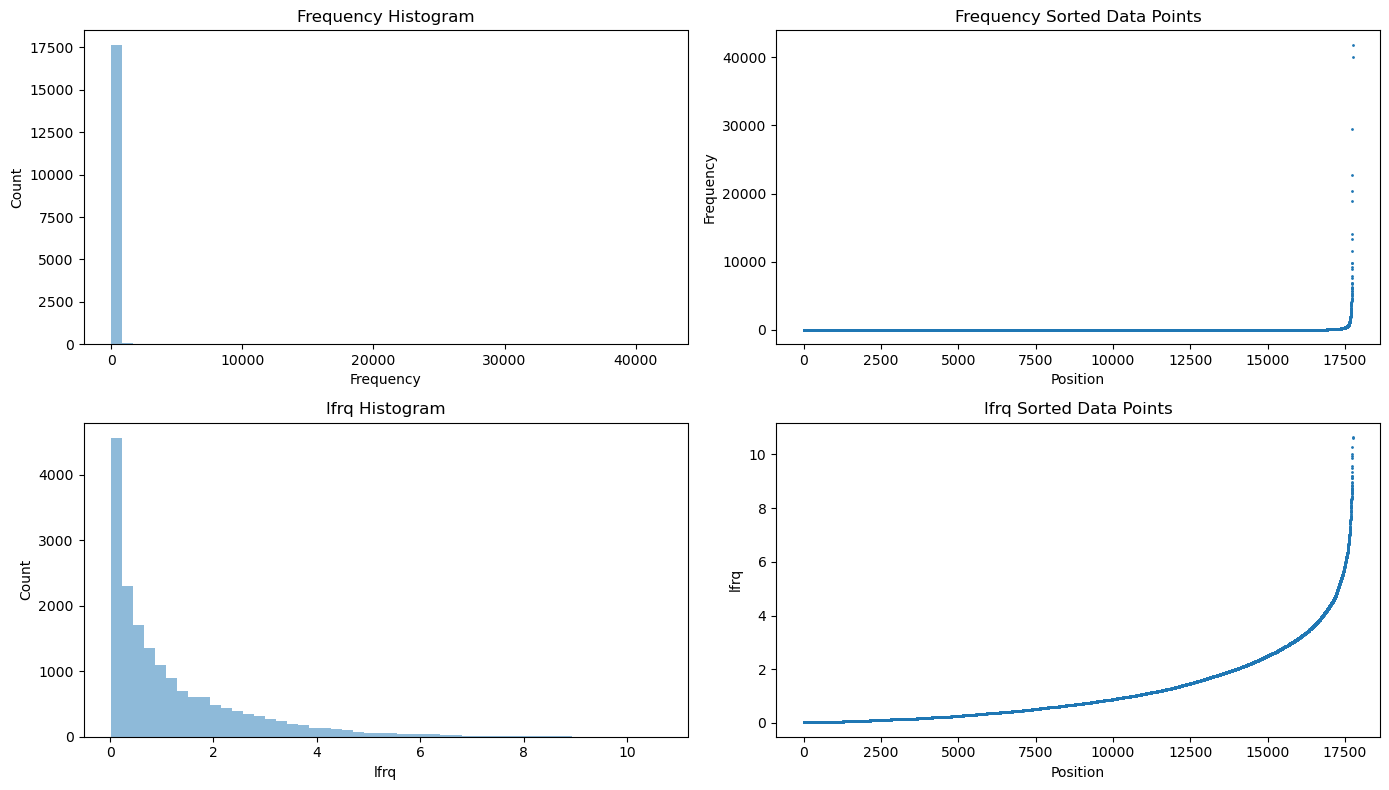

In [11]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def plot_histograms(df, columns, pointsize=1, alphaval=0.5, bins=50, log_axes=False):
    """
    Plots histograms for the specified columns of the given DataFrame.
    Next to each histogram, plots every value, sorted from smallest to largest.

    Parameters:
        df (DataFrame): The DataFrame containing the specified columns.
        columns (list): List of column names to plot.
        log_axes (bool): Use log-spaced bins on a log x-axis for the histograms,
            and a log y-axis for the sorted plots. Default is False.
    """
    # One row of two plots per column. squeeze=False keeps axs a 2-D grid, so that
    # axs[row, 0] and axs[row, 1] work even when there is only one row.
    fig, axs = plt.subplots(len(columns), 2, figsize=(14, 4 * len(columns)), squeeze=False)

    for row, col in enumerate(columns):
        values = df[col].values
        hist_ax = axs[row, 0]     # left: histogram
        sorted_ax = axs[row, 1]   # right: sorted values

        # Histogram. On log axes, use bins that are evenly spaced on a log scale
        # (np.logspace), so that each bin looks the same width on the plot.
        if log_axes:
            hist_bins = np.logspace(np.log10(values.min()), np.log10(values.max()), bins)
        else:
            hist_bins = bins
        hist_ax.hist(values, bins=hist_bins, alpha=alphaval)
        hist_ax.set_title(f'{col} Histogram')
        hist_ax.set_xlabel(col)
        hist_ax.set_ylabel('Count')
        if log_axes:
            hist_ax.set_xscale('log')

        # Every value, sorted from smallest to largest
        sorted_ax.plot(np.sort(values), marker='o', linestyle='', markersize=pointsize)
        sorted_ax.set_title(f'{col} Sorted Data Points')
        sorted_ax.set_xlabel('Position')
        sorted_ax.set_ylabel(col)
        if log_axes:
            sorted_ax.set_yscale('log')

    plt.tight_layout()
    plt.show()

# Example usage:
plot_histograms(lexicon_df, ['Frequency', 'lfrq'])

### Addressing challenging details of corpora

Sometimes researchers do things like remove extreme values so that they can visualize a distribution better. For example, we might trim every word whose log frequency is more than 3 standard deviations from the mean. That is not a great idea here: it would remove the 353 most frequent words in the lexicon -- *you, I, the, a, it, so, go, no, be*... Those are not outliers in any meaningful sense. Word frequencies follow Zipf's law (a few extremely frequent words and a very long tail of rare ones), so the very frequent words are an essential part of the distribution, not noise. They are also real competitors during word recognition: *eye* is a perfectly good candidate when you hear the beginning of *ice*.

There are, however, a few entries that are artifacts of how the corpus was processed. Contractions were apparently split apart, so *I'm*, *you're*, *don't*, and *haven't* left behind the fragments *m*, *re*, *don*, and *haven*, with very high frequencies and with pronunciations as if they were words (*m* is EH M, *re* is R IY). A few single letters (*b*, *o*, *y*) are pronounced as letter names. We remove these by name. (This also removes the name *Don* and the word *haven*, but their frequencies here come almost entirely from the contractions.)

To *see* the whole frequency range without throwing anything away, we can simply put the plots on log axes.

        Item  Frequency Pronunciation      lfrq
1091       b      84.10          B IY  4.443827
4657     don    6295.78        D AA N  8.747794
7136   haven     369.49  HH EY V AH N  5.914826
9265       m    6730.29          EH M  8.814522
10493      o     188.20            OW  5.242805
12577     re    6099.45          R IY  8.716118
17679      y      85.20          W AY  4.456670


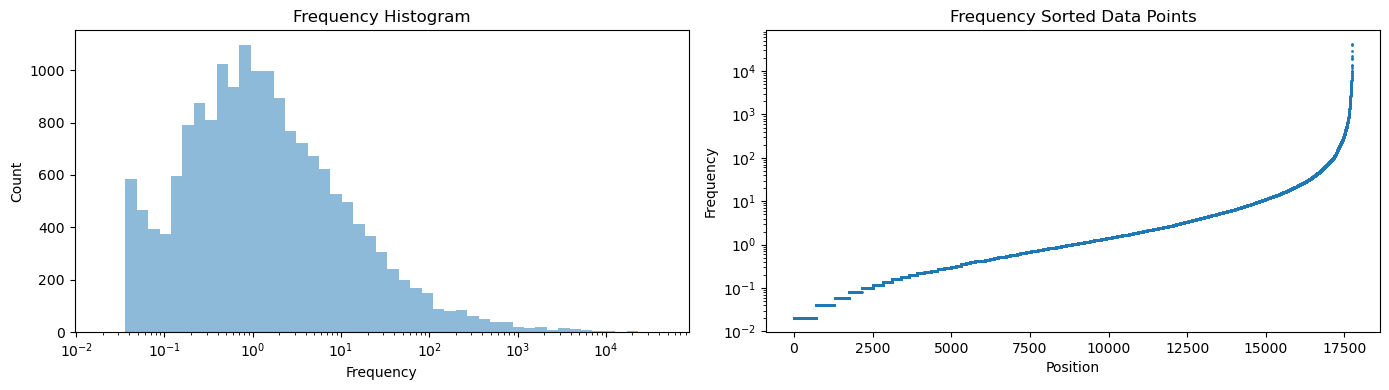

In [12]:
# Entries that are artifacts of corpus processing: fragments of contractions
# (I'm, you're, don't, haven't) and single letters pronounced as letter names
artifacts = ['m', 're', 'don', 'haven', 'b', 'o', 'y']
print(lexicon_df[lexicon_df['Item'].isin(artifacts)])

trimmed_lexicon_df = lexicon_df[~lexicon_df['Item'].isin(artifacts)]

# replot raw frequency, this time on log axes
plot_histograms(trimmed_lexicon_df, ['Frequency'], log_axes=True)

On log axes we can see the whole range, from the rarest words to the most frequent, and we have not thrown anything away. The next code cell compares the sizes of the original and trimmed lexicons, makes the trimmed one our default, and describes it.

In [13]:
# Compare sizes, then make the trimmed lexicon our default and describe it
print(f"{len(lexicon_df)} entries before removing the artifacts, {len(trimmed_lexicon_df)} after")
lexicon_df = trimmed_lexicon_df
lexicon_df.describe()

17750 entries before removing the artifacts, 17743 after


,Frequency,lfrq
count,17743.000000,17743.000000
mean,42.160376,1.220484
std,646.091699,1.394029
min,0.020000,0.019803
25%,0.250000,0.223144
50%,1.020000,0.703098
75%,4.760000,1.750937
max,41857.120000,10.642041


---

### An aside: phonemes

<span style="color:red"><b>OPTIONAL: you can skip this reference table if you know Arpabet; come back to it when you need it. It is here for those who are interested.</b></span>

Again, phonemes are roughly the consonants and vowels of a language. Note that there is not a 1-to-1 mapping between phonemes and letters in English. We can get a /k/ sound from the letters C, K, QU, for example. The letter A can link to sounds like *ay*, *eh*, *uh*, *ah*, *ae* [as in cat], etc. In North American English dialects, we typically have 39-40 phonemes that we have to represent using 26 letters. 

Linguists use the International Phonetic Alphabet to transcribe sounds across languages. The lexicon file we are using uses a symbol system often used in natural language processing computing called *Arpabet*. Here's how to map phonemes to IPA and to actual sounds using examples. The data for this table comes from the website of a speech recognition company called Soapbox.

| Arpabet (SoapBox) | IPA | Example   |
|-------------------|-----|-----------|
| AA                | ɑ   | balm, bot |
| AE                | æ   | bat       |
| AH                | ʌ, ə | butt; also the unstressed vowel at the end of *sofa* |
| AO                | ɔ   | caught, bought |
| AW                | aʊ  | bout      |
| AY                | aɪ  | bite      |
| EH                | ɛ   | bet       |
| ER                | ɝ   | bird      |
| EY                | eɪ  | bait      |
| IH                | ɪ   | bit       |
| IY                | i   | beat      |
| OW                | oʊ  | boat      |
| OY                | ɔɪ  | boy       |
| UH                | ʊ   | book      |
| UW                | u   | boot      |
| B                 | b   | buy       |
| CH                | tʃ  | china     |
| D                 | d   | die       |
| DH                | ð   | thy, bathe|
| F                 | f   | fight     |
| G                 | g   | guy       |
| HH                | h   | high      |
| JH                | dʒ  | jump      |
| K                 | k   | kite      |
| L                 | l   | lie       |
| M                 | m   | my        |
| N                 | n   | night     |
| NG                | ŋ   | sing      |
| P                 | p   | pie       |
| R                 | ɹ   | rye       |
| S                 | s   | sigh      |
| SH                | ʃ   | shy       |
| T                 | t   | tie       |
| TH                | θ   | think     |
| V                 | v   | vie       |
| W                 | w   | wise      |
| Y                 | j   | yacht, yet|
| Z                 | z   | zoo       |
| ZH                | ʒ   | pleasure  |

*Note: the lexicon we load below uses 38 of these 39 symbols -- ER never appears in it. Two quirks of how the lexicon uses these symbols: AH stands for both the stressed vowel in *butt* (ʌ) and the unstressed 'schwa' (ə), as in *sofa* (S OW F AH) -- which is why AH turns out to be the most frequent phoneme -- and the r-colored vowel in *bird* is written as two symbols, AH R (bird = B AH R D), which is why ER never appears and why R is so frequent.*

---

### Phoneme similarity

We could present phonemes as 'localist' or 'one-hot' inputs: when the input is /k/, the evidence for /k/ is 100% and the evidence for everything else is 0%. But a century of research shows that listeners perceive some phonemes (e.g., /b/ and /p/) as more similar than others (/p/ and /a/). So if the word is *bat*, the input /b/ should give us high evidence for /b/, moderate evidence for /p/, and very low evidence for /o/.

One way to estimate similarity is to present phonemes in noise and ask listeners what they heard: the more often listeners report /p/ when the input was /b/, the more confusable the two are. But it is not obvious how to use such *confusion* data. Luce (1986), for example, argued that his confusion data applied only to the noise level and other conditions under which they were collected.

We will build our model's input from phonetic features: each phoneme is a vector of feature values, and what the listener receives is a noisy version of that vector. Then we will check the features against Luce's confusion data, using a technique called *representational similarity analysis*, to see how well they agree with what listeners actually do.

### Phonetic similarity

We will use featural definitions of phonemes, like the ones we built by hand in Part 3, but with a much richer feature set: 43 features, from the file `data/jstrace-features-no-silence.csv` (the feature set used with jsTRACE, an implementation of the TRACE model). The features fall into a few groups:

- **Voicing and sonority**: UNVOICE, VOICE, SONORANT, NONSON.
- **Manner of articulation**: LIQUID, SEMI-GLID, VOCALIC, STOP, NASAL, FRICATIVE, AFFRICATE, APPROXIMANT, LATERAL.
- **Place of articulation**, from the lips back to the throat: BILABIAL, LABIODENTAL, DENTAL, ALVEOLAR, POSTALVEOLAR, PALATAL, VELAR, GLOTTAL.
- **Vowel quality**: FB1-FB5 (front to back) and HL1-HL6 (high to low), given twice -- once for the first half of the vowel (the A columns) and once for the second half (the B columns). That lets diphthongs move: /aɪ/ (AY, as in *bite*) starts low and central and ends high and front.

Many values are *graded* rather than 0 or 1. For example, /p/ is 0.7 BILABIAL, 0.2 LABIODENTAL, and 0.1 DENTAL: mostly bilabial, with a little overlap with the neighboring places. That builds in the idea that sounds made at nearby places in the mouth are more similar. This is why we use so many features: about 18 binary features are enough to *distinguish* the phonemes of English, but we want graded *similarity*, and that takes graded place and vowel dimensions.

Notice also that consonants and vowels share almost no features, so many consonant-vowel *cosines* will be exactly 0. That is one reason we will use *distances* in feature space, rather than cosines, when we turn features into probabilities.

In the next code cell, we load the features for the 38 phonemes in our lexicon. We also calculate the prior probability of each phoneme: how often it occurs, counting each word as many times as it occurs (its frequency).

In [ ]:
# Load the phonetic feature definitions (one row per phoneme, indexed by its Arpabet symbol)
features_df = pd.read_csv('./data/jstrace-features-no-silence.csv').dropna(how='all')
features_df = features_df[features_df['CMU'] != 'MISS']   # drop the 'missing' placeholder row
features_df = features_df.set_index('CMU')
feature_columns = features_df.loc[:, 'UNVOICE':'HL6B'].columns

# The phonemes used in the lexicon, in alphabetical order: join all the pronunciations into one
# long string, split it into single phonemes, and keep each phoneme once (a set)
all_phonemes = ' '.join(lexicon_df['Pronunciation']).split()
sorted_unique_phonemes = sorted(set(all_phonemes))
missing = set(sorted_unique_phonemes) - set(features_df.index)
if missing:
    raise ValueError(f"No feature definitions for: {missing}")

# One row of 43 feature values per phoneme (blank cells mean 0)
feature_matrix_df = features_df.loc[sorted_unique_phonemes, feature_columns].fillna(0).astype(float)

# Prior probability of each phoneme: count every phoneme in every word, counting each word as
# many times as it occurs (its frequency), then divide by the total so the values sum to 1
phoneme_count_dict = defaultdict(float)
for pronunciation, freq in zip(lexicon_df['Pronunciation'], lexicon_df['Frequency']):
    for phoneme in pronunciation.split():
        phoneme_count_dict[phoneme] += freq
phoneme_counts = pd.Series(phoneme_count_dict).sort_values(ascending=False)   # most frequent first
phoneme_prob_dict = (phoneme_counts / phoneme_counts.sum()).to_dict()

# Display the features for a few phonemes, and the phoneme priors
display(feature_matrix_df.loc[['P', 'B', 'T', 'D', 'IY', 'AY']])
pd.Series(phoneme_prob_dict).round(4)   # the phoneme priors, most frequent first

---

### Converting features to similarities

Each phoneme is now a vector of 43 feature values, so we can compare phonemes with cosine similarity, exactly as in Part 3. We wrote our own cosine function earlier, but we can also get a whole matrix of cosines at once from the `scikit-learn` package, as in the code block below.

In [15]:
# Imported under an alias on purpose: a plain
#     from sklearn.metrics.pairwise import cosine_similarity
# would overwrite the two-vector cosine_similarity() we wrote earlier in
# this notebook, and sklearn's version takes a matrix rather than a pair
# of vectors -- so the earlier teaching examples would start erroring.
from sklearn.metrics.pairwise import cosine_similarity as sk_cosine_similarity

# Compute the cosine similarity between each pair of phoneme feature vectors
cosine_sim_matrix = sk_cosine_similarity(feature_matrix_df.values)

# Convert the similarity matrix to a DataFrame for better readability
cosine_sim_df = pd.DataFrame(cosine_sim_matrix, index=sorted_unique_phonemes, columns=sorted_unique_phonemes)

# Display a portion of the cosine similarity matrix
cosine_sim_df.iloc[:10, :10]

,AA,AE,AH,AO,AW,AY,B,CH,D,DH
AA,1.000000,0.832867,0.797758,0.919628,0.794013,0.770817,0.000000,0.000000,0.000000,0.000000
AE,0.832867,1.000000,0.837866,0.832554,0.834118,0.897005,0.000000,0.000000,0.000000,0.000000
AH,0.797758,0.837866,1.000000,0.878050,0.843985,0.830047,0.000000,0.000000,0.000000,0.000000
AO,0.919628,0.832554,0.878050,1.000000,0.834898,0.811622,0.000000,0.000000,0.000000,0.000000
AW,0.794013,0.834118,0.843985,0.834898,1.000000,0.937090,0.000000,0.000000,0.000000,0.000000
AY,0.770817,0.897005,0.830047,0.811622,0.937090,1.000000,0.000000,0.000000,0.000000,0.000000
B,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.298833,0.856136,0.631861
CH,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.298833,1.000000,0.343162,0.438185
D,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.856136,0.343162,1.000000,0.641565
DH,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.631861,0.438185,0.641565,1.000000


### From features to probability: a noise model

Self-similarity is 1.0 for every phoneme, and similar phonemes have high cosines. Now we need to turn the features into probabilities: when the input is /b/, how probable is it that a listener perceives /b/, /p/, /d/, and so on?

The simplest idea would be to divide each row of cosines by its sum, as we did in Part 4. That does not work well here, for two reasons. First, the probabilities come out much too flat: with 38 phonemes, many of which have fairly high cosines with the input, the correct phoneme gets only a small share of the total, as if we were always listening in heavy noise. Second, many consonant-vowel cosines are exactly 0. A probability of 0 is dangerous in our model: we multiply phoneme probabilities across positions, so a single 0 would rule a word out for good, no matter how well everything else matched.

A better idea is to model what the listener actually receives. Suppose the speaker produces the feature vector of /b/, but by the time it reaches the listener, every feature value has been disturbed a little by *noise*: a random amount drawn from a normal (Gaussian) distribution with mean 0 and standard deviation $\sigma$ (sigma), independently for each feature. Then the probability of receiving an input $x$ if the phoneme was $Y$ falls off with the distance between $x$ and $Y$'s feature vector $f_Y$:

$$
P(x \mid Y) \propto e^{-\,\|x - f_Y\|^2 / 2\sigma^2}
$$

where $\|x - f_Y\|^2$ is the *squared Euclidean distance*: the sum, over the 43 features, of the squared differences. For a clean input ($x = f_X$, the feature vector of phoneme $X$ itself), normalizing over all the candidate phonemes gives

$$
P(\text{perceive } Y \mid \text{input } X) = \frac{e^{-c\, d^2(X, Y)}}{\sum\limits_{k=1}^{n} e^{-c\, d^2(X, Y_k)}}, \qquad c = \frac{1}{2\sigma^2}
$$

This is closely related to Shepard's (1987) 'universal law of generalization', which says that generalization (and confusion) between two things falls off *exponentially* with the distance between them in psychological space. Ours falls off exponentially with the *squared* distance, which makes it a *Gaussian* (bell-shaped) function of distance: the shape that Gaussian noise produces. Either way, the exponential is never exactly 0, so no phoneme is ever completely ruled out (though very different phonemes get extremely small values). The parameter $c$ sets how sharply probability falls off with distance. You can think of it as the *clarity* of the input: with a large $c$ (small $\sigma$, clear speech), the input phoneme gets almost all the probability; with a small $c$ (large $\sigma$, noisy speech), probability spreads to similar phonemes. (If you have met the *softmax* function in machine learning, this is it, with $c$ as an inverse temperature.)

Why distances rather than cosines? Because noise disturbs each feature value separately, what matters is how far apart two phonemes are in feature space. Cosine compares only the *directions* of two vectors. (In practice, as we will see, the two put phoneme pairs in nearly the same order.)

How should we set $c$, and so $\sigma$? Rather than picking a number out of thin air, we choose a target: when a clear token of a phoneme (exactly its feature vector) is heard on its own, the correct phoneme should get a probability of about .95, on average -- fairly clear listening conditions. (Be careful about what this means. It is the probability the model gives the correct phoneme for a *perfect* token. If every token really were disturbed by noise with the $\sigma$ this implies, picking the most probable phoneme would be right only about 83% of the time. We will see truly noisy tokens in Part 7.) This choice matters more than it might seem. As Norris and McQueen (2008) point out, the clearer the perceptual evidence, the less word frequency matters. With noisier input, a very common word can beat a rare word that sounds similar, even when the rare word is what was said. The code below searches for the value of $c$ that meets the target, and reports the $\sigma$ it implies; we will use $\sigma$ again in Part 8, when we blend phonemes together. Notice that the functions take a matrix of *distances*. That way we can reuse them later with distances from a different source.

In [ ]:
def distance_to_confusion(distance_matrix, c):
    # P(perceive column phoneme | input row phoneme): exponential of
    # -c * distance, normalized so each row sums to 1
    weights = np.exp(-c * distance_matrix)
    return weights / weights.sum(axis=1, keepdims=True)

def calibrate_clarity(distance_matrix, target_accuracy=0.95):
    # Find the c at which a clean input phoneme gets a probability of
    # target_accuracy, on average. Accuracy rises with c, so we
    # can find it by bisection: halve the search range until it is tiny.
    low, high = 0.0, 1000.0
    for _ in range(100):
        c = (low + high) / 2
        accuracy = np.diag(distance_to_confusion(distance_matrix, c)).mean()
        if accuracy < target_accuracy:
            low = c
        else:
            high = c
    return c

def squared_distances(vectors):
    # Squared Euclidean distance between every pair of rows of `vectors` (one row per phoneme):
    # for each pair, the sum over the features of the squared difference in feature values
    n = len(vectors)
    distances = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            difference = vectors[i] - vectors[j]
            distances[i, j] = np.sum(difference ** 2)
    return distances

feature_distance_matrix = squared_distances(feature_matrix_df.values)
feature_distance_df = pd.DataFrame(feature_distance_matrix, index=sorted_unique_phonemes, columns=sorted_unique_phonemes)

clarity = calibrate_clarity(feature_distance_matrix, target_accuracy=0.95)
sigma = np.sqrt(1 / (2 * clarity))   # the noise standard deviation that this clarity implies
feature_confusion_matrix = distance_to_confusion(feature_distance_matrix, clarity)
feature_confusion_df = pd.DataFrame(feature_confusion_matrix, index=sorted_unique_phonemes,
                                    columns=sorted_unique_phonemes)

p_correct = pd.Series(np.diag(feature_confusion_matrix), index=sorted_unique_phonemes).sort_values()
print(f"clarity c = {clarity:.2f}, so the noise standard deviation is sigma = {sigma:.3f}")
print(f"P(correct) for a clean input: mean {p_correct.mean():.3f}, "
      f"lowest {p_correct.iloc[0]:.3f} ({p_correct.index[0]}), highest {p_correct.iloc[-1]:.3f} ({p_correct.index[-1]})")

# The five most likely percepts when the input is /B/
with pd.option_context('display.float_format', '{:.7f}'.format):
    print(feature_confusion_df.loc['B'].sort_values(ascending=False).head(5))

Two things are worth noticing in that output.

First, the /B/ row: when the input is /b/, the most likely errors are /d/ and /g/ (same voicing and manner, different place), and /p/ is far less likely. In this feature set, place errors are much more likely than voicing errors. Miller and Nicely (1955) found the same pattern for listeners hearing consonants in noise: voicing survives noise much better than place of articulation does.

Second, the range of P(correct). The next cell prints the whole /B/ row (the last line of the cell above, without `head`), and then `p_correct` for every phoneme. Every consonant gets at least .98 of the probability, but some vowels get much less -- as little as .75. Why? Look at how vowels are coded in the feature table: they all share SONORANT and VOCALIC, and differ only in small graded values (0.4 and 0.1) on the front/back and height dimensions. So the vowels sit close together in feature space. Is that realistic? Which would you expect to be easier to hear in noise, vowels or consonants?

In [ ]:
# All percepts ranked by probability when the input is /B/
with pd.option_context('display.float_format', '{:.14f}'.format):
    print(feature_confusion_df.loc['B'].sort_values(ascending=False))

# P(correct) for a clear token of every phoneme, from lowest to highest
print(p_correct.round(3).to_string())

### Visualizing similarity

A simple and effective way to visualize similarity when we have a matrix is to use a *heatmap*, where color indicates value. Let's plot the matrix we just computed. Each row is an input phoneme and each column a candidate phoneme, and each cell is the *feature-based similarity* of the two, $e^{-c\,d^2}$, normalized so that each row sums to 1. The normalized values are exactly what the model uses as bottom-up evidence: how strongly an input of the row phoneme supports each candidate. Note that these are **not** confusion data -- nobody measured them. They are predictions from our feature set. Below, we will compare them with confusions measured from real listeners (Luce, 1986).

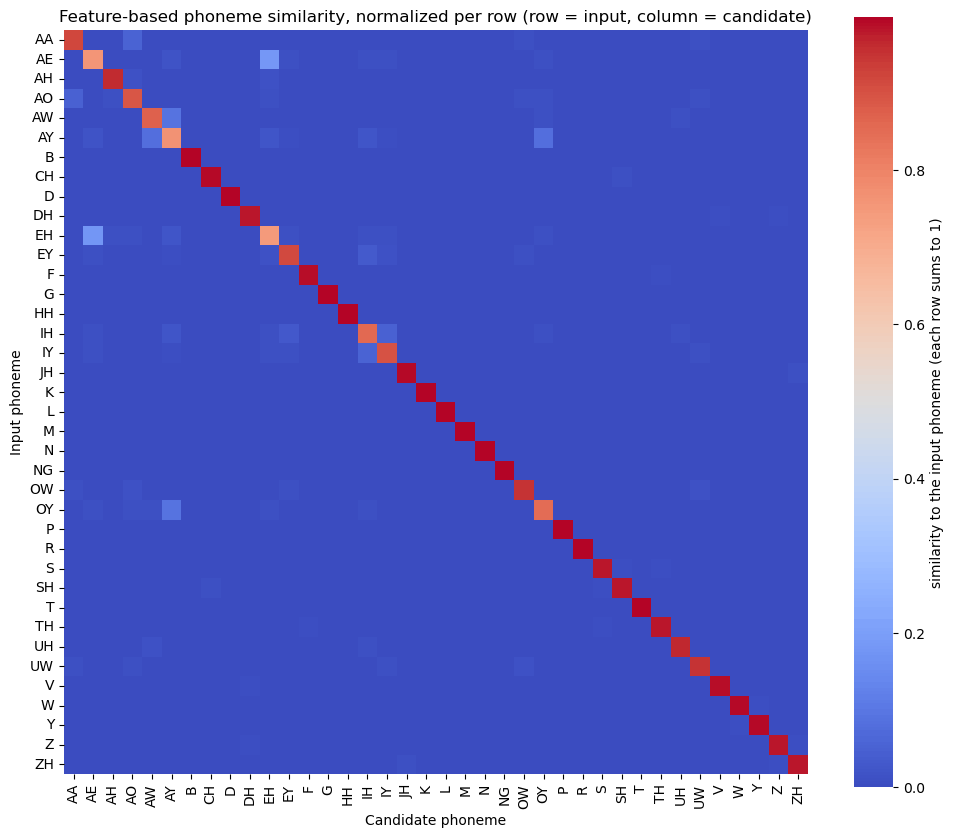

In [18]:
# let's visualize it

import seaborn as sns

plt.figure(figsize=(12, 10))
# xticklabels/yticklabels=True: label every phoneme (by default seaborn skips some)
sns.heatmap(feature_confusion_df, cmap='coolwarm', square=True, xticklabels=True, yticklabels=True,
            cbar_kws={'label': 'similarity to the input phoneme (each row sums to 1)'})
plt.title("Feature-based phoneme similarity, normalized per row (row = input, column = candidate)")
plt.xlabel("Candidate phoneme")
plt.ylabel("Input phoneme")
plt.show()

That is not very informative: the diagonal stands out, but almost everything else is the same color. The problem is the color scale. These values range from nearly 1 down to about $10^{-21}$, and a *linear* color scale spends almost all of its colors on the top of that range: 0.001 and 0.000000001 get the same color, even though one is a million times larger than the other.

The fix is a *logarithmic* color scale, where each step in color means '10 times more likely' rather than '0.1 more probability'. Log scales are the standard choice when values span many orders of magnitude (earthquake magnitudes, sound levels in decibels). They also suit our model: when we get to words, the model adds up the *logs* of these values across positions, so a log scale shows us the quantities that actually drive word recognition.

We also switch from the `coolwarm` colormap to `viridis`. `coolwarm` is a *diverging* colormap, meant for values with a meaningful midpoint (like correlations, which run from -1 through 0 to +1). Probabilities have no such midpoint, so a *sequential* colormap, running from dark to light, suits them better. (`viridis` is also readable by people with the most common forms of color blindness.)

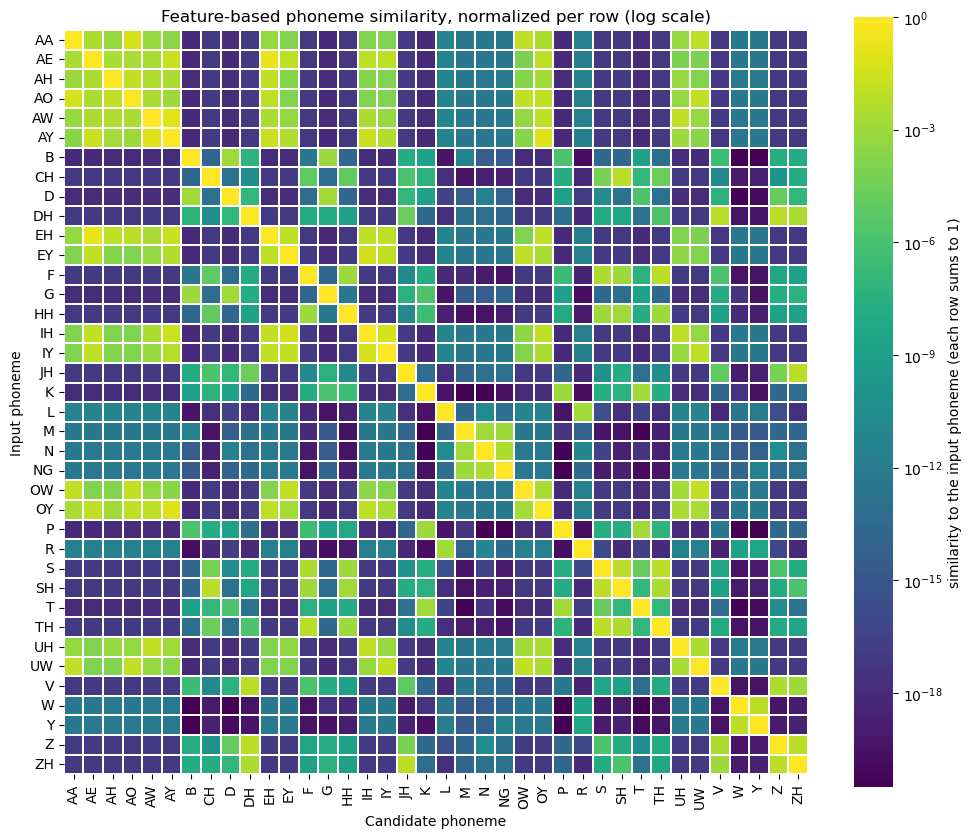

In [19]:
from matplotlib.colors import LogNorm

# A logarithmic color scale, from the smallest value in the matrix up to 1
log_colors = LogNorm(vmin=feature_confusion_df.values.min(), vmax=1)

plt.figure(figsize=(12, 10))
# linewidths/linecolor: a thin white border around each cell makes the rows and columns easier to follow
sns.heatmap(feature_confusion_df, cmap='viridis', norm=log_colors, square=True, xticklabels=True, yticklabels=True,
            linewidths=0.3, linecolor='white', cbar_kws={'label': 'similarity to the input phoneme (each row sums to 1)'})
plt.title("Feature-based phoneme similarity, normalized per row (log scale)")
plt.xlabel("Candidate phoneme")
plt.ylabel("Input phoneme")
plt.show()

Much better! Now the diagonal no longer swamps everything else, and we can see structure: the consonant-vowel pairs, which share few or no features, form a dark floor, and there are bright patches among the consonants and among the vowels. But the phonemes are sorted alphabetically, which scatters similar sounds across the plot. Could we re-sort them to put similar things near similar things? Let's use a standard *clustering* technique called *hierarchical clustering* (which will reorder the rows and columns so that similar items are near each other) and then recreate the heatmap.

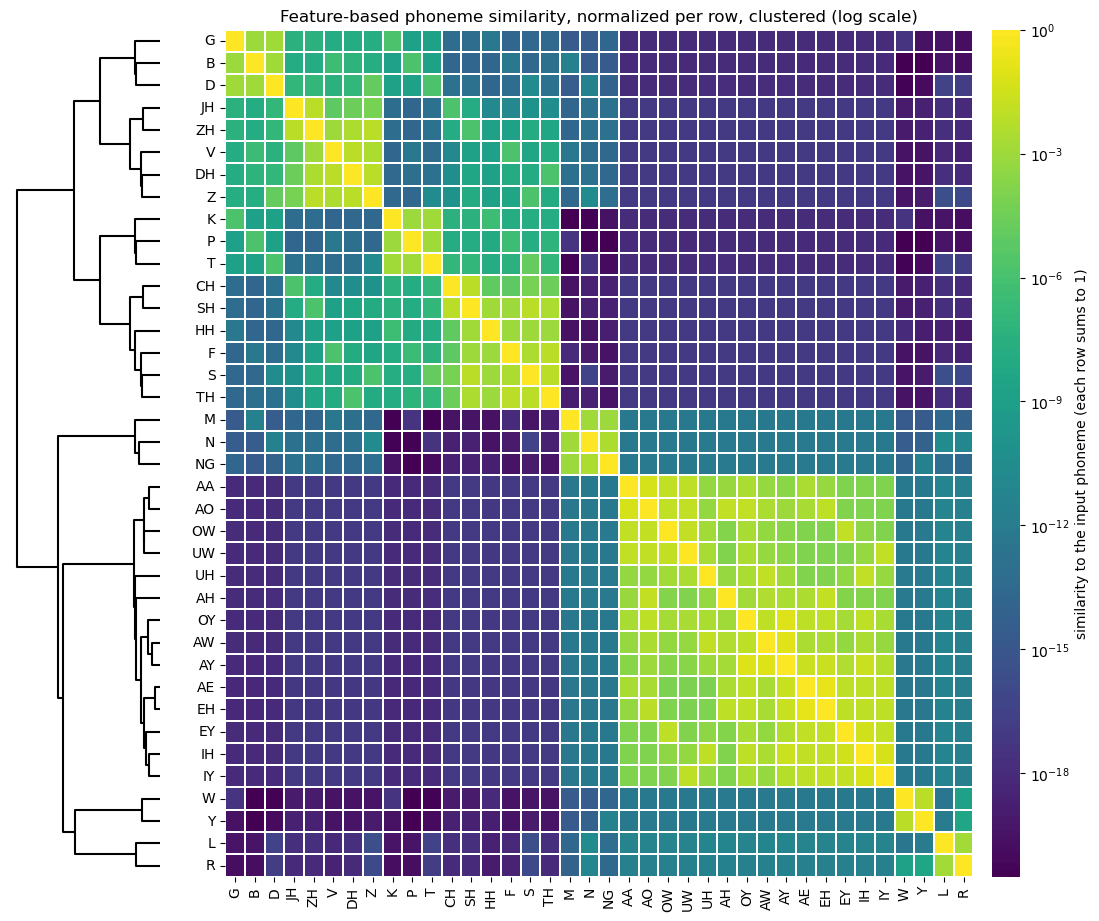

In [20]:
# Let's cluster first

from scipy.cluster.hierarchy import linkage, leaves_list, dendrogram
from scipy.spatial.distance import squareform

# Perform hierarchical clustering on the phonemes' feature vectors, using the same
# squared Euclidean distances as the model
link = linkage(squareform(feature_distance_matrix, checks=False), method='average')

# Get the order of rows according to the hierarchy
row_order = leaves_list(link)

# Put the new order in NEW variables. (Overwriting sorted_unique_phonemes
# would silently mislabel the matrices if an earlier cell were re-run.)
clustered_phonemes = [sorted_unique_phonemes[i] for i in row_order]
reordered_df = feature_confusion_df.loc[clustered_phonemes, clustered_phonemes]


def heatmaps_with_tree(panels, link, figsize):
    """
    Draw one or more heatmaps side by side, with the clustering tree (dendrogram) to the left
    of the first one, lined up with its rows. Each panel is (title, DataFrame, options), where
    the DataFrame's rows and columns are already in the clustered order, and options is a
    dictionary of extra arguments for sns.heatmap (colors, color scale, color bar label).
    """
    # The figure is a row of columns with these relative widths: the tree, then for each panel a
    # gap for the phoneme labels, the heatmap, a small gap, its color bar, and a gap for the color bar's label
    widths = [1.6]
    for _ in panels:
        widths += [0.7, 8, 0.2, 0.3, 0.8]
    fig = plt.figure(figsize=figsize)
    grid = fig.add_gridspec(1, len(widths), width_ratios=widths, wspace=0)

    # The tree. Each bracket joins two groups of phonemes; the farther LEFT a bracket is, the more
    # different the groups it joins. The tree places its leaves 10 units apart from the bottom up,
    # so we flip its y-axis to put the first leaf at the top, next to the heatmap's first row.
    tree_ax = fig.add_subplot(grid[0, 0])
    dendrogram(link, orientation='left', ax=tree_ax, no_labels=True, link_color_func=lambda k: 'black')
    tree_ax.set_ylim(10 * len(link) + 10, 0)
    tree_ax.axis('off')

    for p, (title, df, options) in enumerate(panels):
        ax = fig.add_subplot(grid[0, 2 + 5 * p])          # this panel's heatmap column
        cbar_ax = fig.add_subplot(grid[0, 4 + 5 * p])     # and its color bar
        sns.heatmap(df, ax=ax, cbar_ax=cbar_ax, xticklabels=True, yticklabels=True,
                    linewidths=0.3, linecolor='white', **options)
        ax.set_title(title)
        ax.set_xlabel('')
        ax.set_ylabel('')
    return fig


heatmaps_with_tree([("Feature-based phoneme similarity, normalized per row, clustered (log scale)", reordered_df,
                     {'cmap': 'viridis', 'norm': log_colors,
                      'cbar_kws': {'label': 'similarity to the input phoneme (each row sums to 1)'}})],
                   link, figsize=(14, 11))
plt.show()

Now similar phonemes sit next to each other, and the vowels form their own block. The tree on the left, called a *dendrogram*, shows how the clustering grouped them. Each bracket joins two groups of phonemes, and the farther to the left a bracket is, the more different the groups it joins. So brackets right next to the heatmap join very similar phonemes, and the bracket at the far left makes the biggest split of all: here, between the *obstruents* (the stops, fricatives, and affricates, from /g/ down to /θ/) and the *sonorants* (the nasals, vowels, glides, and liquids). Take a few minutes with this plot. Which phonemes form groups? Do the groups match your intuitions about which sounds are easy to confuse? Where does the feature set seem to get things wrong?

---

### Checking the features against listeners: representational similarity analysis

The features provide a *hypothesis* about phoneme similarity: they say how confusable phonemes should be, given how we coded them. Are they right? We can check with *representational similarity analysis* (RSA; Kriegeskorte, Mur, & Bandettini, 2008), a technique from cognitive neuroscience for comparing two systems that represent the same things in very different formats -- a model and a brain area, say, or two brain areas. Instead of comparing the representations directly, RSA compares their *similarity structure*: for every pair of items, how similar are they in system A, and how similar in system B? If the two systems put the pairs in the same order, they agree, whatever their format. Here system A is our feature vectors, and system B is listeners, as measured by how often they confuse phonemes in noise. Luce (1986) presented spoken syllables in noise and asked listeners to identify the consonant or vowel they heard. He tested initial consonants (as in *pa*), vowels, and final consonants (as in *ap*), each at three noise levels. We use the clearest level of each, where listeners were 70-76% correct overall.

A confusion matrix mixes two things: how *similar* two phonemes are, and the listeners' *biases* toward some responses (some listeners might answer /θ/ whenever they are unsure, for example). Shepard (1957) showed how to separate the two. Suppose listeners follow Luce's (1959) choice rule, so that the probability of responding $j$ to stimulus $i$ is proportional to $bias_j \times similarity_{ij}$. Then the biases cancel out of this quantity:

$$
s_{ij} = \sqrt{\frac{n_{ij}}{n_{ii}} \times \frac{n_{ji}}{n_{jj}}}
$$

where $n_{ij}$ is the number of times stimulus $i$ was reported as $j$. (Try it: write each count as $bias \times similarity$ and see what is left after canceling.) For example, in Luce's initial-consonant data, /b/ was reported as /ð/ (as in *then*) 21 times in 144 trials, but /ð/ was reported as /b/ only 6 times in 175. The formula combines both directions into a single, symmetric similarity.

We then define the distance between two phonemes as $d_{ij} = -\ln s_{ij}$, so that $s_{ij} = e^{-d_{ij}}$. That is the same exponential form we used for the features, with $d_{ij}$ in the place of the squared feature distance. In fact, under this model, Luce's listeners were behaving as if $c = 1$: his noise level corresponds to a clarity of 1, and clearer speech corresponds to larger values of $c$.

The file `data/phoneme_confusion_distances.csv` holds these distances for our 38 phonemes. From here on, we call them the *confusion-based* distances, and the probabilities we compute from them the *confusion-based* probabilities, to distinguish them from the feature-based ones.

#### How the file was built

<span style="color:red"><b>OPTIONAL: you can skip ahead to the two cautions below. It is here for those who are interested.</b></span>

- Consonants tested in both initial and final position get the average of the two distances, since our model treats a phoneme the same way in every position.
- Before computing the ratios, 0.5 was added to every count. Without this, a pair that was never confused would get an infinite distance. With it, such pairs get a large but finite distance.
- Consonants and vowels were tested in separate experiments, so there are no data on consonant-vowel confusions. Those pairs, and the few consonant pairs never tested together (e.g., /h/ only appears initially and /ŋ/ only finally), are set to the largest distance measured.
- One pair was adjusted by hand: /p/ and /h/. In Luce's initial-consonant data, /h/ was reported as /p/ more often than as /h/ (49 vs. 30 times in 113 trials), which made /p/ and /h/ by far the closest pair of phonemes. In our word simulations, that one pair caused many errors (*pit* recognized as *hit*, *hay* as *pay*). The confusion is real in noise: Cutler et al. (2004) also found /p/ and /h/ among the most confusable consonants. But in their clearest condition, /h/ was identified correctly 84% of the time, compared with 27% in Luce's. Since we are using these data to stand in for fairly clear speech, we set the /p/-/h/ distance to the median distance among the consonant pairs, treating it as an ordinary pair of consonants.

Two cautions. First, these are confusions in noise. When we compare Luce's three noise levels, the *pattern* of confusions changes with the noise level, not just the number of errors, because different cues are masked at different rates. (That is the point behind Luce's caution, mentioned above, that confusion data do not generalize beyond the conditions in which they were collected.) So turning $c$ up to simulate clear speech is an approximation. Second, for vowels we can check the data against Peterson and Barney's (1952) vowel identification data, collected in quiet: the two agree reasonably well (a rank correlation of .70 over the 45 vowel pairs the two studies share; not computed in this notebook).

In [21]:
# Load the distances derived from Luce's (1986) confusion data. We use them to EVALUATE the
# features (RSA, below), not as the model's input.
confusion_based_distance_df = pd.read_csv('./data/phoneme_confusion_distances.csv', index_col='phoneme')
confusion_based_distance_df = confusion_based_distance_df.loc[sorted_unique_phonemes, sorted_unique_phonemes]

# With c = 1 we should get roughly the accuracy of Luce's listeners
print(f"with c = 1: mean P(correct) = "
      f"{np.diag(distance_to_confusion(confusion_based_distance_df.values, 1.0)).mean():.3f}")

# For our simulations, calibrate c to the same 95% target we used for the features
confusion_based_clarity = calibrate_clarity(confusion_based_distance_df.values, target_accuracy=0.95)
confusion_based_probability_df = pd.DataFrame(distance_to_confusion(confusion_based_distance_df.values, confusion_based_clarity),
                                  index=sorted_unique_phonemes, columns=sorted_unique_phonemes)

confusion_based_p_correct = pd.Series(np.diag(confusion_based_probability_df), index=sorted_unique_phonemes).sort_values()
print(f"clarity c = {confusion_based_clarity:.2f}")
print(f"P(correct) for a clean input: mean {confusion_based_p_correct.mean():.3f}, "
      f"lowest {confusion_based_p_correct.iloc[0]:.3f} ({confusion_based_p_correct.index[0]}), "
      f"highest {confusion_based_p_correct.iloc[-1]:.3f} ({confusion_based_p_correct.index[-1]})")

# The five most likely percepts when the input is /B/
print(confusion_based_probability_df.loc['B'].sort_values(ascending=False).head(5))

with c = 1: mean P(correct) = 0.710
clarity c = 2.14
P(correct) for a clean input: mean 0.950, lowest 0.713 (DH), highest 1.000 (IY)
B     0.988185
DH    0.003374
V     0.003221
TH    0.002162
G     0.000854
Name: B, dtype: float64


In [ ]:
from scipy.stats import spearmanr

# RSA: do the features and the listeners put phoneme pairs in the same order of similarity?
# Luce tested consonants and vowels separately, so there are no data for consonant-vowel pairs,
# and we compare consonant pairs and vowel pairs separately.
vowels = ['AA', 'AE', 'AH', 'AO', 'AW', 'AY', 'EH', 'EY', 'IH', 'IY', 'OW', 'OY', 'UH', 'UW']
consonants = [p for p in sorted_unique_phonemes if p not in vowels]
cosine_distance_df = pd.DataFrame(1 - cosine_sim_matrix, index=sorted_unique_phonemes, columns=sorted_unique_phonemes)

rsa_rows = []
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (name, group) in zip(axes, [('consonants', consonants), ('vowels', vowels)]):
    upper = np.triu_indices(len(group), k=1)          # each pair once, no diagonal
    listeners = confusion_based_distance_df.loc[group, group].values[upper]
    features = feature_distance_df.loc[group, group].values[upper]
    cosines = cosine_distance_df.loc[group, group].values[upper]
    # Spearman's rank correlation asks whether the two put the pairs in the same ORDER
    rho = spearmanr(features, listeners).correlation
    rsa_rows.append({'phonemes': name, 'pairs': len(listeners),
                     'features (Euclidean) vs. listeners': round(rho, 2),
                     'features (cosine) vs. listeners': round(spearmanr(cosines, listeners).correlation, 2)})
    ax.scatter(features, listeners, s=8, alpha=0.5)
    ax.set_xlabel('feature distance (squared Euclidean)')
    ax.set_ylabel("listener distance (Luce's confusions)")
    ax.set_title(f'{name}: {len(listeners)} pairs, rank correlation = {rho:.2f}')
plt.tight_layout()
plt.show()
display(pd.DataFrame(rsa_rows))

# The similarity structures side by side, in the same (feature-clustered) order: the features as the
# model uses them (squared Euclidean distance), the features as cosine distance (Parts 3-4), and listeners.
# Consonant-vowel pairs have no listener data, so we leave them blank (white).
no_data = np.zeros((len(clustered_phonemes), len(clustered_phonemes)), dtype=bool)
for i, first in enumerate(clustered_phonemes):
    for j, second in enumerate(clustered_phonemes):
        no_data[i, j] = (first in vowels) != (second in vowels)   # True if one is a vowel and the other is not
panels = []
for title, distance_df in [('features: squared Euclidean distance (the model)', feature_distance_df),
                           ('features: cosine distance (Parts 3-4)', cosine_distance_df),
                           ("listeners: distance from Luce's confusions", confusion_based_distance_df)]:
    ordered = distance_df.loc[clustered_phonemes, clustered_phonemes].copy()
    if 'listeners' in title:
        ordered = ordered.mask(no_data)   # mask() blanks out (sets to NaN) the cells where no_data is True
    # viridis_r: SMALL distances (similar pairs) are bright
    panels.append((title, ordered, {'cmap': 'viridis_r', 'cbar_kws': {'label': 'distance'}}))

# The tree on the left is the feature clustering from above, which sets the order for all three
heatmaps_with_tree(panels, link, figsize=(33, 9))
plt.show()

What does the RSA tell us?

- **Real but modest agreement.** The rank correlation between the feature distances and the listeners' distances is .41 for consonant pairs and .31 for vowel pairs. (Cosine distances give nearly the same values, .39 and .31.) So the features put phoneme pairs in a rather different order from listeners. Part of the difference may come from the listening conditions: Luce's listeners heard the phonemes in noise, which masks some cues more than others (see the cautions above), while the features describe clear speech. 
- **Where they disagree.** Look at the /B/ rows. For Luce's listeners, the most likely errors for /b/ are /ð/ (as in *then*), /v/, and /θ/ (as in *thin*): sounds with weak, brief acoustic cues that are easy to mix up in noise. The features put /b/ next to /d/ and /g/ (same voicing and manner, different place), and /ð/ and /v/ much further away. For vowels, the features make the vowels the hardest phonemes of all, because they code vowel quality as small steps on front-back and high-low scales; for Luce's listeners, the hardest phonemes are the weak fricatives, and /ɑ/ and /ɔ/ (AA and AO, as in *cot* and *caught*), which many American English speakers do not distinguish at all.
- **What RSA cannot tell us.** It compares only the *order* of the pairs, not the size of the distances. And it cannot reach 1.0 even for a perfect feature set, because Luce's data are themselves noisy and come from one listening condition. Nor can it say anything about consonant-vowel pairs, which Luce did not test (the white cells in the right-hand heatmap), which is also why above we have separate RSA values for consonants and vowels.

Compare the three heatmaps. All three use the order from the feature clustering (the tree on the left). The two feature versions -- squared Euclidean distance, which the model uses, and the cosine distance from Parts 3 and 4 -- show nearly the same structure, as their nearly equal RSA values suggest. (Cosine compares only the *directions* of two feature vectors, Euclidean distance also their lengths; for a noise model, which moves the input around in feature space, distance is the right measure.) Which groups of phonemes appear in both the features and the listeners? Which appear only in one? Where would you change the features to make them more like listeners?

### Which probabilities should the model use?

From here on, the simulations use whatever is in `phoneme_confusion_df`, and we will use the **feature-based** version. Luce's data tell us how listeners confused phonemes in one noise condition, but they are not a model of the *input*: we cannot add noise to them, blend two phonemes together, or ask what a slightly different token would do. With features we can do all three, and we will need them in Parts 7 and 8. The price, as the RSA shows, is that the features capture only part of what listeners do, so we should expect the model to make some errors that listeners would not (we will see which in Part 6). Norris and McQueen take the other route: Shortlist B's phoneme probabilities come from listeners, not from a theory of features. (Challenge question 9 lets you try Luce's version.)

We also add *silence* to the matrix, as one more 'phoneme'. We will see why when we get to the simulations.

---

In [23]:
SILENCE = 'SIL'

def add_silence(distance_df, clarity, silence_distance=None):
    # Confusion probabilities, P(perceive column | input row), for the phonemes in distance_df
    # plus silence (an extra row and column). Used for Luce's distances, which say nothing about
    # silence, so by default silence is as distant as the least confusable pair.
    if silence_distance is None:
        silence_distance = distance_df.values.max()
    labels = list(distance_df.index) + [SILENCE]
    distances = np.full((len(labels), len(labels)), float(silence_distance))
    distances[:-1, :-1] = distance_df.values
    distances[-1, -1] = 0.0
    return pd.DataFrame(distance_to_confusion(distances, clarity), index=labels, columns=labels)

# For the features, silence gets a feature of its own: a 44th feature, SILENCE, which is 1 for
# silence and 0 for every phoneme. Silence is then far from every phoneme, by a distance that
# follows from the features, like every other distance.
feature_vectors_df = feature_matrix_df.copy()
feature_vectors_df['SILENCE'] = 0.0                 # a new column: 0 for every phoneme
feature_vectors_df.loc[SILENCE] = 0.0               # a new row for silence: all features 0 ...
feature_vectors_df.loc[SILENCE, 'SILENCE'] = 1.0    # ... except its own
distances_with_silence = squared_distances(feature_vectors_df.values)

# The normalized feature similarities used as bottom-up evidence by all the simulations below
# (phonemes + silence). The name says 'confusion' for historical reasons: these are not confusion data.
phoneme_confusion_df = pd.DataFrame(distance_to_confusion(distances_with_silence, clarity),
                                    index=feature_vectors_df.index, columns=feature_vectors_df.index)

# To use Luce's confusion-based probabilities instead (challenge question 9), run:
#     phoneme_confusion_df = add_silence(confusion_based_distance_df, confusion_based_clarity)

### Bayesian word recognition simulation

We are now ready to simulate word recognition using Bayesian principles. At each position $t$ of the input, the function below:

1. gets the bottom-up probability of every phoneme, given the input phoneme (a row of `phoneme_confusion_df`);
2. for every word in the lexicon, multiplies in the probability of *that word's* phoneme at position $t$, so that each word's running product is its likelihood, $P(Evidence|Word)$, for the input so far (Equation 4);
3. multiplies each word's likelihood by its prior and normalizes over the whole lexicon to get its posterior (Equation 5).

**Knowing when the word is over.** Suppose the input is *cat*. After /k æ t/, the evidence fits *cat* perfectly -- but it fits the beginnings of *cattle*, *catalog*, and *category* just as well. Nothing in the phonemes themselves says that the word is over. What tells a listener is what comes next: here, silence. So by default (`end_silence=True`), the input has one more position after the last phoneme: silence (`SIL`, which we added to the similarity matrix above), and every word in the lexicon is padded with silence after its last phoneme. When the silence arrives, *cattle* has to explain it with its next phoneme, /ə/, which is very unlikely, while *cat* explains it with silence. It works in the other direction too: while hearing *cattle*, the word *cat* is not thrown out when the input goes past its end, but from then on it has to explain real phonemes with silence. The plots show the extra position, labeled `SIL`. Set `end_silence=False` to see what happens without it. (Norris and McQueen's input can include a silence marker, too. Finding word boundaries *within* continuous speech, where there is usually no silence between words, is a much harder problem -- see challenge question 8.)

**Is the word recognized?** The function also checks whether the target was recognized: whether, at the end of the input, it is more probable than any other word. (Homophones like *tail* and *tale* pool their probability, since the input cannot tell them apart.) The plots mark words that were not recognized with a red *ERROR* in the title.

#### Implementation notes

<span style="color:red"><b>OPTIONAL: you can skip to the code. It is here for those who are interested.</b></span>

**We always start from the word priors.** It is tempting to use the posterior from position $t-1$ as the prior at position $t$, and that is legitimate *if* you then multiply in only the new evidence from position $t$. What you must not do is both: carry the old posterior forward *and* multiply in the whole product from position 1, because then the evidence from early positions gets counted again at every step. (An earlier version of this notebook did exactly that.) Norris & McQueen recompute from the priors at each step, and so do we.

**We consider the whole lexicon -- no shortlist.** Norris & McQueen limit the number of candidates to 50 per position, but they note that the model performs almost identically with smaller or larger limits. Our code scores all ~17,000 words at each position in a fraction of a second, so we don't need a shortlist at all. The trick is to work with *log* probabilities. Multiplying many small probabilities produces numbers too small for the computer to represent, but adding their logs does not cause that problem. (Remember that $\log(a \times b) = \log a + \log b$.)

**The word prior has a knob.** The prior is $P(Word) \propto frequency^{\,freq\_exponent}$. The default, `freq_exponent=1`, uses raw frequency, as Norris & McQueen do. Values below 1 compress the high end, weakening the advantage of very frequent words; `freq_exponent=0` makes all words equally likely a priori.

**What we plot.** We keep the `n_plot` words with the highest peak probability, plus the target word, which we always want to see even if it never gets near the top.

In [ ]:
import time
import pandas as pd
import numpy as np

def get_phoneme_prob_at_position(phoneme, phoneme_confusion_df, phoneme_prob_dict,
                                 use_phoneme_prior=False):

    """
    Calculate the bottom-up probability of each phoneme, given the input at one position.

    This is the step written out in Part 4:

        P(H_j | i) = sim(i, v_j) P(H_j) / SUM_k sim(i, v_k) P(H_k)

    with the exponential similarity from 'From features to probability: a noise model'
    playing the role of sim.

    Parameters:
        phoneme (str): The current input phoneme.
        phoneme_confusion_df (DataFrame): P(perceive column phoneme | input row phoneme).
        phoneme_prob_dict (dict): The dictionary containing the probabilities of each phoneme.
        use_phoneme_prior (bool): weight each candidate phoneme's probability by that
            phoneme's prior probability, i.e. the P(H_k) terms above.

            DEFAULTS TO FALSE. sim_bayes_new multiplies these per-position
            probabilities to get each word's likelihood, P(input | word).
            Including phoneme priors here would add the product of each
            word's phoneme priors to every word's score -- an extra bias toward
            words made of common phonemes, on top of the word prior. With the
            prior off, each value is the similarity divided by a normalizer
            that is the same for every word, so it cancels in the word
            posterior. Set it to True to see the effect.

    Returns:
        pd.Series: The probabilities of each phoneme at the current position.
    """
    evidence_distribution = phoneme_confusion_df.loc[phoneme]

    if use_phoneme_prior:
        # The priors are keyed by phoneme NAME, and the names live in the Series
        # INDEX, not in its values.
        #
        # An earlier version of this line read
        #     evidence_distribution.map(lambda x: x * phoneme_prob_dict.get(x, 1))
        # but .map() hands the lambda the Series VALUES (floats like 0.07), so
        # every dictionary lookup missed, the default of 1 came back every time,
        # and the prior was silently never applied at all.
        #
        # Silence is not a phoneme of any word, so it has no prior of its own;
        # we give it the average phoneme prior, 1 / (number of phonemes).
        priors = pd.Series(phoneme_prob_dict).reindex(evidence_distribution.index)
        priors = priors.fillna(1.0 / len(phoneme_prob_dict))
        evidence_distribution = evidence_distribution * priors

    # normalize (back to probabilities) and return
    return evidence_distribution / evidence_distribution.sum()

def sim_bayes_new(target_word, lexicon_df, phoneme_confusion_df, phoneme_prob_dict,
                  freq_exponent=1.0, use_phoneme_prior=False, n_plot=50, end_silence=True):
    """
    Simulate recognition of one word, phoneme by phoneme, using Bayes' theorem
    over the WHOLE lexicon (no shortlist).

    Parameters:
        target_word (str): The word to present.
        lexicon_df (DataFrame): The lexicon (Item, Frequency, Pronunciation).
        phoneme_confusion_df (DataFrame): P(perceive column phoneme | input row phoneme).
        phoneme_prob_dict (dict): The prior probability of each phoneme.
        freq_exponent (float): the word prior is proportional to Frequency ** freq_exponent.
            1 = raw frequency (as in Norris & McQueen); below 1 compresses the high
            end; 0 makes all words equally likely a priori.
        use_phoneme_prior (bool): weight phoneme probabilities by phoneme prior
            probability (see get_phoneme_prob_at_position).
        n_plot (int): how many words (those with the highest peak probability) to
            return for plotting. The target word is always returned as well.
        end_silence (bool): follow the word with silence, so the model can tell when
            the word is over. Default True. Needs a silence row and column in
            phoneme_confusion_df (see add_silence).

    Returns:
        posterior_word_df, posterior_phon_df: 2 dataframes with word and phoneme probabilities by position.
        posterior_word_df also has a column 'Recognized' (True or False; see below).
    """
    # Initialize
    start_time = time.time()
    print(f'--- Starting simulation of word {target_word}', end = "")
    # this just pulls the Pronunciation for the target word
    target_pronunciation = lexicon_df.loc[lexicon_df['Item'] == target_word, 'Pronunciation'].values[0]
    target_phonemes = target_pronunciation.split()
    # The input: the word's phonemes, followed (by default) by silence
    input_symbols = target_phonemes + ([SILENCE] if end_silence else [])
    n_positions = len(input_symbols)
    words = lexicon_df['Item'].values

    # Code every word as a row of phoneme numbers (column positions in
    # phoneme_confusion_df). We only need as many positions as the input has.
    # A word that ends sooner is padded with silence -- or, if end_silence is
    # False, with -1, meaning 'no phoneme here'.
    phoneme_index = {ph: i for i, ph in enumerate(phoneme_confusion_df.columns)}
    if end_silence and SILENCE not in phoneme_index:
        raise ValueError("end_silence=True needs a silence row and column in "
                         "phoneme_confusion_df -- build it with add_silence()")
    padding = phoneme_index[SILENCE] if end_silence else -1
    word_codes = np.full((len(words), n_positions), padding)
    for row, pronunciation in enumerate(lexicon_df['Pronunciation']):
        codes = [phoneme_index[ph] for ph in pronunciation.split()[:n_positions]]
        word_codes[row, :len(codes)] = codes

    # Word priors, as logs: P(Word) is proportional to Frequency ** freq_exponent
    prior = lexicon_df['Frequency'].values ** freq_exponent
    log_prior = np.log(prior / prior.sum())

    # Each word's running log-likelihood, log P(Evidence so far | Word).
    # Adding logs is the same as multiplying probabilities (Equation 4).
    log_likelihood = np.zeros(len(words))

    posteriors = np.zeros((n_positions, len(words)))   # one row per position
    phoneme_prob_list = []

    # Loop through each position of the input
    for pos, phoneme in enumerate(input_symbols):

        # Step 1: Get the bottom-up probability of every phoneme, given the input
        phoneme_prob_at_pos = get_phoneme_prob_at_position(phoneme, phoneme_confusion_df,
                                                           phoneme_prob_dict, use_phoneme_prior)
        for p, prob in phoneme_prob_at_pos.items():
            phoneme_prob_list.append({'Phoneme Position': pos + 1, 'Phoneme': p, 'Probability': prob})
        log_phoneme_prob = np.log(phoneme_prob_at_pos.reindex(phoneme_confusion_df.columns).values)

        # Step 2: multiply each word's likelihood by the probability of ITS
        # phoneme at this position (with logs, we add). Only the new position is
        # added; earlier positions are already in the running sum.
        codes = word_codes[:, pos]
        has_phoneme = codes >= 0
        log_likelihood[has_phoneme] += log_phoneme_prob[codes[has_phoneme]]
        # Without silence, words that have already ended are dropped. (With
        # silence, every word has a code at every position, so none are.)
        log_likelihood[~has_phoneme] = -np.inf

        # Step 3: posterior = likelihood x prior, normalized over the whole
        # lexicon (Equation 5). Subtracting the maximum before exp() keeps the
        # numbers in a range the computer can represent; it cancels out when
        # we normalize.
        log_score = log_prior + log_likelihood
        score = np.exp(log_score - log_score.max())
        posteriors[pos] = score / score.sum()

    # Was the word recognized? At the last input position, add up the
    # probabilities of words with the same pronunciation (homophones like
    # tail/tale cannot be told apart from the input), and check that the
    # target's pronunciation is more probable than every other pronunciation.
    by_pronunciation = pd.Series(posteriors[-1]).groupby(lexicon_df['Pronunciation'].values).sum()
    p_target = by_pronunciation[target_pronunciation]
    recognized = bool((by_pronunciation.drop(target_pronunciation) < p_target).all())

    # New DataFrame for phoneme probabilities
    posterior_phon_df = pd.DataFrame(phoneme_prob_list)

    # Keep the n_plot words with the highest peak probability, plus the target
    peak = posteriors.max(axis=0)
    top_rows = list(np.argsort(-peak)[:n_plot])
    target_row = int(np.flatnonzero(words == target_word)[0])
    if target_row not in top_rows:
        top_rows.append(target_row)

    posterior_word_df = pd.concat(
        [pd.DataFrame({'Item': words[top_rows],
                       'Probability': posteriors[pos, top_rows],
                       'Phoneme Position': pos + 1})
         for pos in range(n_positions)],
        ignore_index=True)

    # Order the words for the legend: target first, then by peak probability. The plotting
    # function groups the words by label and sorts the labels alphabetically, so we put each
    # word's rank in front of it, zero-padded to the same width ('01-cat', '02-cattle', ...).
    # Without the zeros, '10-...' would sort before '2-...'.
    sorted_words_by_peak = [target_word] + [words[r] for r in top_rows if words[r] != target_word]
    width = len(str(len(sorted_words_by_peak)))
    sort_order = {word: f"{index:0{width}d}" for index, word in enumerate(sorted_words_by_peak, start=1)}
    posterior_word_df['ItemWithOrder'] = posterior_word_df['Item'].apply(lambda x: f"{sort_order[x]}-{x}")

    # Add a target_word column to the final result DataFrames; could help with subsequent analysis
    posterior_word_df['Target Word'] = target_word
    posterior_phon_df['Target Word'] = target_word
    posterior_word_df['Recognized'] = recognized

    # Print the total elapsed time
    total_elapsed_time = time.time() - start_time
    print(f"\t... Time for simulation: {total_elapsed_time:.6f} seconds")

    return posterior_word_df, posterior_phon_df  # Return both DataFrames

# Try it on one word
word_result, phon_result = sim_bayes_new('cat', lexicon_df, phoneme_confusion_df, phoneme_prob_dict)

Okay, we have simulated processing of one word! How can we visualize the results? Let's make a function that will generate a plot from the kind of result we get from our simulation function. 

In [ ]:
import itertools
import os   # used by the saveplots branch below

def plot_simulation_result(word_result, phon_result, log_scale=False, full_scale=False,
                           saveplots=False, phonplot=12, wordplot=20):
    """
    Plots a line graph based on the simulation result DataFrame and phoneme probabilities.
    
    Parameters:
        word_result (DataFrame): The DataFrame containing simulation results.
        phon_result (DataFrame): The DataFrame containing phoneme probabilities.
        log_scale (bool): Whether to use a log scale for the Y-axis. Default is False.
        full_scale (bool): Fix the Y-axis range to 0-1. Default is False.
        saveplots (bool): Write each figure to plots/<word>.png. Default is False.
        phonplot (int): How many phonemes to name in the legend. Default is 12.
        wordplot (int): How many words to name in the legend. Default is 20.

    Words that were not recognized (see 'Recognized' in sim_bayes_new) get
    '-- ERROR' in red after the title of the word plot.

    Note: this function reads the globals `lexicon_df` (to look up pronunciations)
    and `SILENCE`.
    """
    
    unique_words = word_result['Target Word'].unique()
    
    for word in unique_words:
        # Filter data for the current word
        word_data = word_result[word_result['Target Word'] == word]
        phon_data = phon_result[phon_result['Target Word'] == word]
        
        # Get the phonemes corresponding to the positions in the target word
        target_pronunciation = lexicon_df.loc[lexicon_df['Item'] == word, 'Pronunciation'].values[0]
        target_phonemes = target_pronunciation.split()
        # If the input ended with silence, label that position too
        n_positions = int(word_data['Phoneme Position'].max())
        position_labels = target_phonemes + [SILENCE] * (n_positions - len(target_phonemes))
        
        marker_list = [".","o","v","^","<",">","1","2","3","4","8",
                       "s","p","P","*","h","H","+","x","X","D","d","|","_",
                       0,1,2,3,4,5,6,7,8,9,10,11]
        
        marker_iter = itertools.cycle(marker_list)
        
        fig, axs = plt.subplots(1, 2, figsize=(18, 8))
        
        # Initialize empty lists for legend labels and handles
        word_legend_labels = []
        word_legend_handles = []
        
        # First subplot for word probabilities
        for name, group in word_data.groupby('ItemWithOrder'):
            marker = next(marker_iter)
            line, = axs[0].plot(group['Phoneme Position'], group['Probability'], marker=marker, markersize=6)
            
            # Get the pronunciation (phoneme string) for the word
            word_spelling = name.split('-', 1)[1]   # split once: words may contain '-'
            word_pronunciation = lexicon_df.loc[lexicon_df['Item'] == word_spelling, 'Pronunciation'].values[0]
            
            # Update legend label to include phoneme string
            label_with_phonemes = f"{name}-{word_pronunciation}"
            word_legend_labels.append(label_with_phonemes)
            word_legend_handles.append(line)

        
        # the wordplot arguments limit the lists to that many items in the legend, even if more lines plot
        axs[0].legend(word_legend_handles[:wordplot], word_legend_labels[:wordplot])
        axs[0].set_xlabel('Phoneme Position')
        axs[0].set_ylabel('Probability')
        title = axs[0].set_title(f'Word probabilities for {word}')
        if not word_data['Recognized'].iloc[0]:
            # Attach red text just to the right of the title: xy=(1, 0) is the
            # bottom-right corner of the title, because xycoords=title
            axs[0].annotate(' -- ERROR', xy=(1, 0), xycoords=title, va='bottom',
                            color='red', fontsize=title.get_fontsize())
        axs[0].set_xticks(np.arange(1, n_positions + 1))
        axs[0].set_xticklabels(position_labels)  # Update x-axis labels to show phonemes
        
        # Calculate peak activations for each phoneme
        peak_phoneme_activations = phon_data.groupby('Phoneme')['Probability'].max().sort_values(ascending=False).reset_index()
        
        # Select the top phonemes by peak activation
        top_phonemes = peak_phoneme_activations.head(phonplot)['Phoneme'].tolist()
        
        # Initialize empty lists for legend labels and handles
        phoneme_legend_labels = []
        phoneme_legend_handles = []
        
        # Second subplot for phoneme probabilities
        for name, group in phon_data.groupby('Phoneme'):
            marker = next(marker_iter)
            line, = axs[1].plot(group['Phoneme Position'], group['Probability'], marker=marker, markersize=6)
            # Only add to the legend if the phoneme is among the top phonemes
            if name in top_phonemes:
                phoneme_legend_labels.append(name)
                phoneme_legend_handles.append(line)        
                
        axs[1].legend(phoneme_legend_handles[:phonplot], phoneme_legend_labels[:phonplot], title='Phonemes')
        axs[1].set_xlabel('Phoneme Position')
        axs[1].set_ylabel('Probability')
        axs[1].set_title(f'Phoneme Probabilities for {word}')
        axs[1].set_xticks(np.arange(1, n_positions + 1))
        axs[1].set_xticklabels(position_labels)  # Update x-axis labels to show phonemes
        
        if log_scale:
            axs[0].set_yscale('log')
            axs[1].set_yscale('log')
        
        plt.tight_layout()

        # If full_scale is True, set the y-axis to range from 0 to 1
        if full_scale:
            axs[0].set_ylim([0, 1])
            axs[1].set_ylim([0, 1])
        
        if saveplots:
            # Ensure the directory exists
            if not os.path.exists('plots'):
                os.makedirs('plots')
            plt.savefig(f'plots/{word}.png')
        
        plt.show()

Now let's make a function that will let us simulate many words. 

In [26]:
import pandas as pd

def run_simulations(word_list, lexicon_df, phoneme_confusion_df, phoneme_prob_dict,
                    freq_exponent=1.0, use_phoneme_prior=False, n_plot=50, end_silence=True):
    """
    Runs simulations for a list of words and returns aggregated results.

    Parameters:
        word_list (list): List of words to simulate.
        lexicon_df (DataFrame): The DataFrame containing the lexicon.
        phoneme_confusion_df (DataFrame): P(perceive column phoneme | input row phoneme).
        phoneme_prob_dict (dict): Dictionary containing the probabilities of each phoneme.
        freq_exponent (float): word prior is proportional to Frequency ** freq_exponent.
            Default is 1 (raw frequency).
        use_phoneme_prior (bool): weight phoneme probabilities by phoneme prior
            probability. Default is False -- see the note in
            get_phoneme_prob_at_position for why.
        n_plot (int): how many words to keep for plotting (plus the target). Default is 50.
        end_silence (bool): follow each word with silence. Default is True.

    Returns:
        DataFrame, DataFrame: Aggregated word and phoneme results.
    """

    # Initialize empty DataFrames to store aggregated results
    aggregated_word_results = pd.DataFrame()
    aggregated_phoneme_results = pd.DataFrame()

    for word in word_list:
        # Check if the word exists in the lexicon
        if word not in lexicon_df['Item'].values:
            print(f"Warning: '{word}' is not in the lexicon. Skipping this word.")
            continue

        word_result, phon_result = sim_bayes_new(word, lexicon_df, phoneme_confusion_df,
                                                 phoneme_prob_dict, freq_exponent,
                                                 use_phoneme_prior, n_plot, end_silence)

        # Append the results to the aggregated DataFrames
        aggregated_word_results = pd.concat([aggregated_word_results, word_result], ignore_index=True)
        aggregated_phoneme_results = pd.concat([aggregated_phoneme_results, phon_result], ignore_index=True)

    return aggregated_word_results, aggregated_phoneme_results

--- Starting simulation of word boo	... Time for simulation: 0.041568 seconds
--- Starting simulation of word boot	... Time for simulation: 0.035077 seconds
--- Starting simulation of word go	... Time for simulation: 0.033006 seconds
--- Starting simulation of word dog	... Time for simulation: 0.038173 seconds
--- Starting simulation of word abrupt	... Time for simulation: 0.041586 seconds
--- Starting simulation of word territory	... Time for simulation: 0.043623 seconds
--- Starting simulation of word abandon	... Time for simulation: 0.044199 seconds
--- Starting simulation of word clamp	... Time for simulation: 0.040031 seconds
--- Starting simulation of word intolerable	... Time for simulation: 0.044693 seconds
--- Starting simulation of word sew	... Time for simulation: 0.034234 seconds


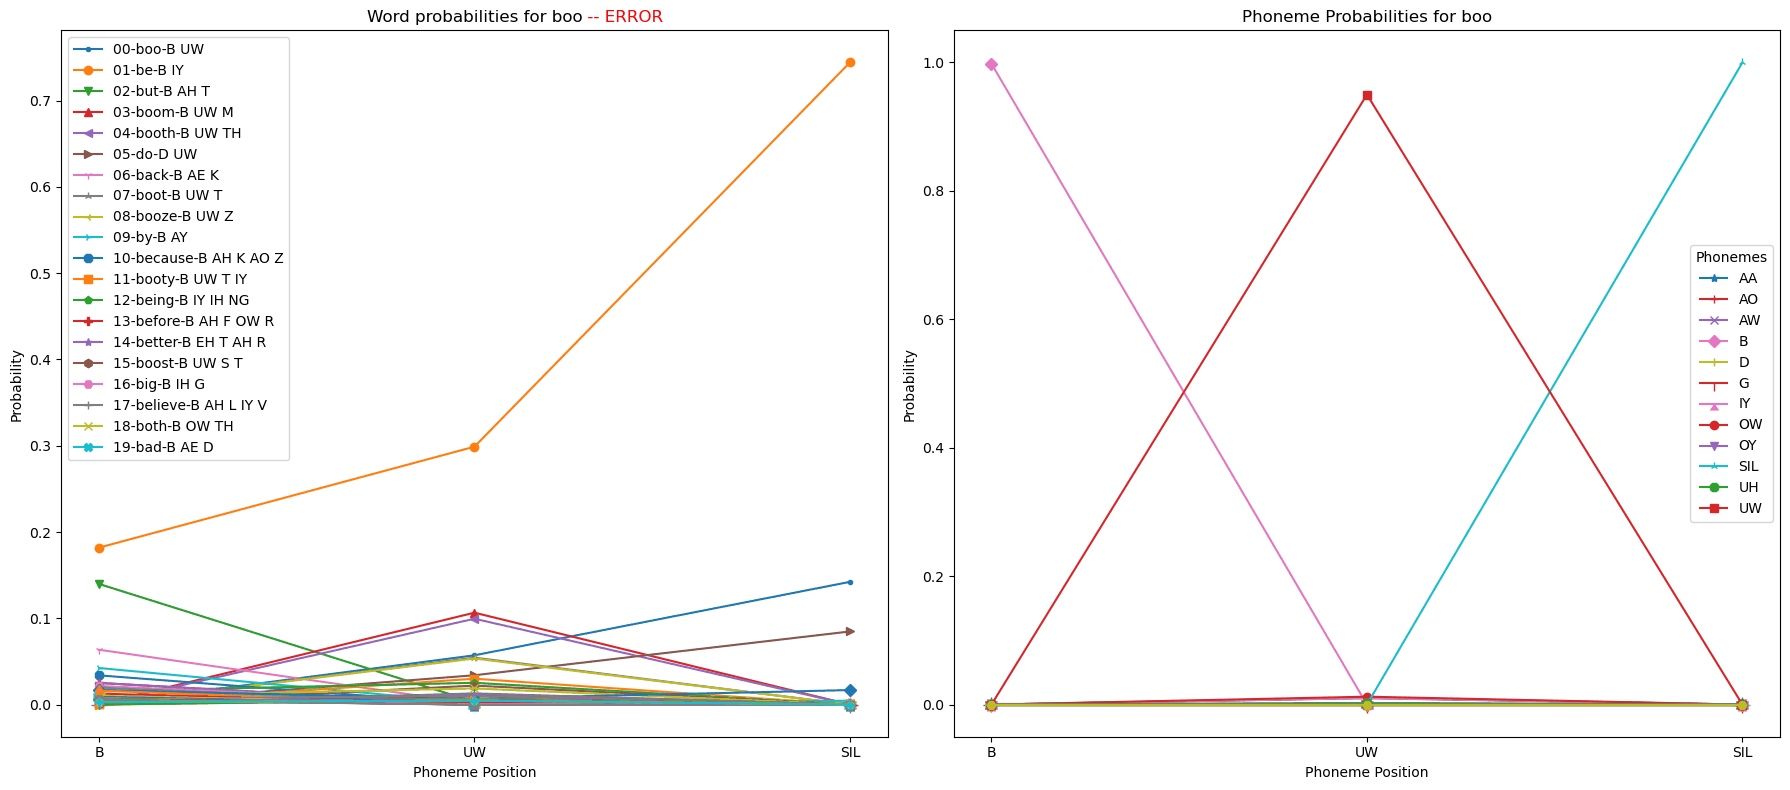

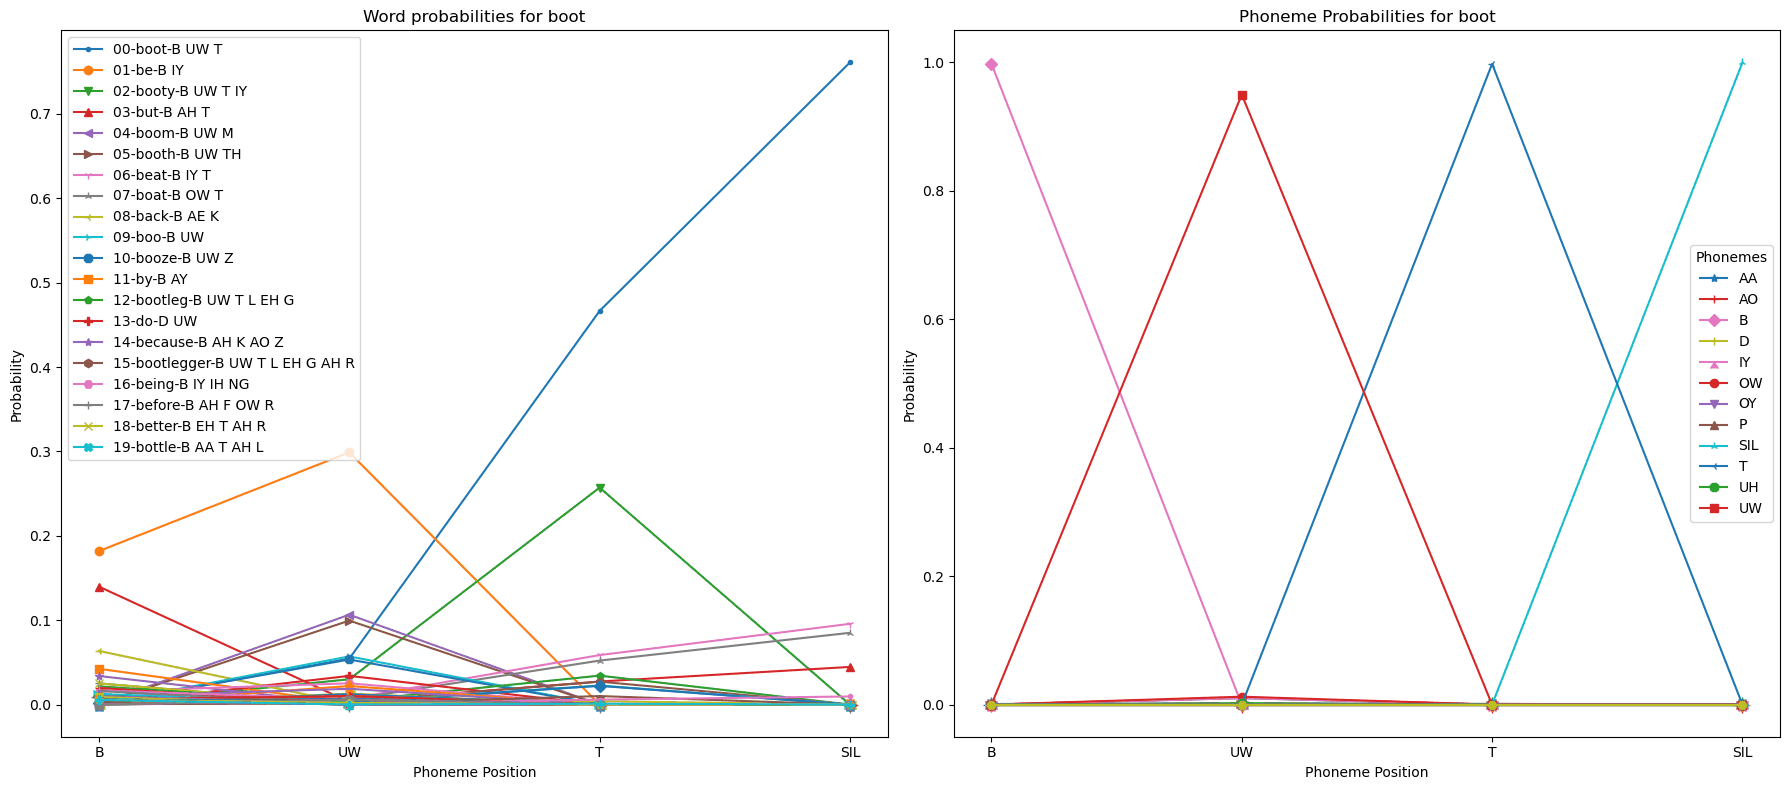

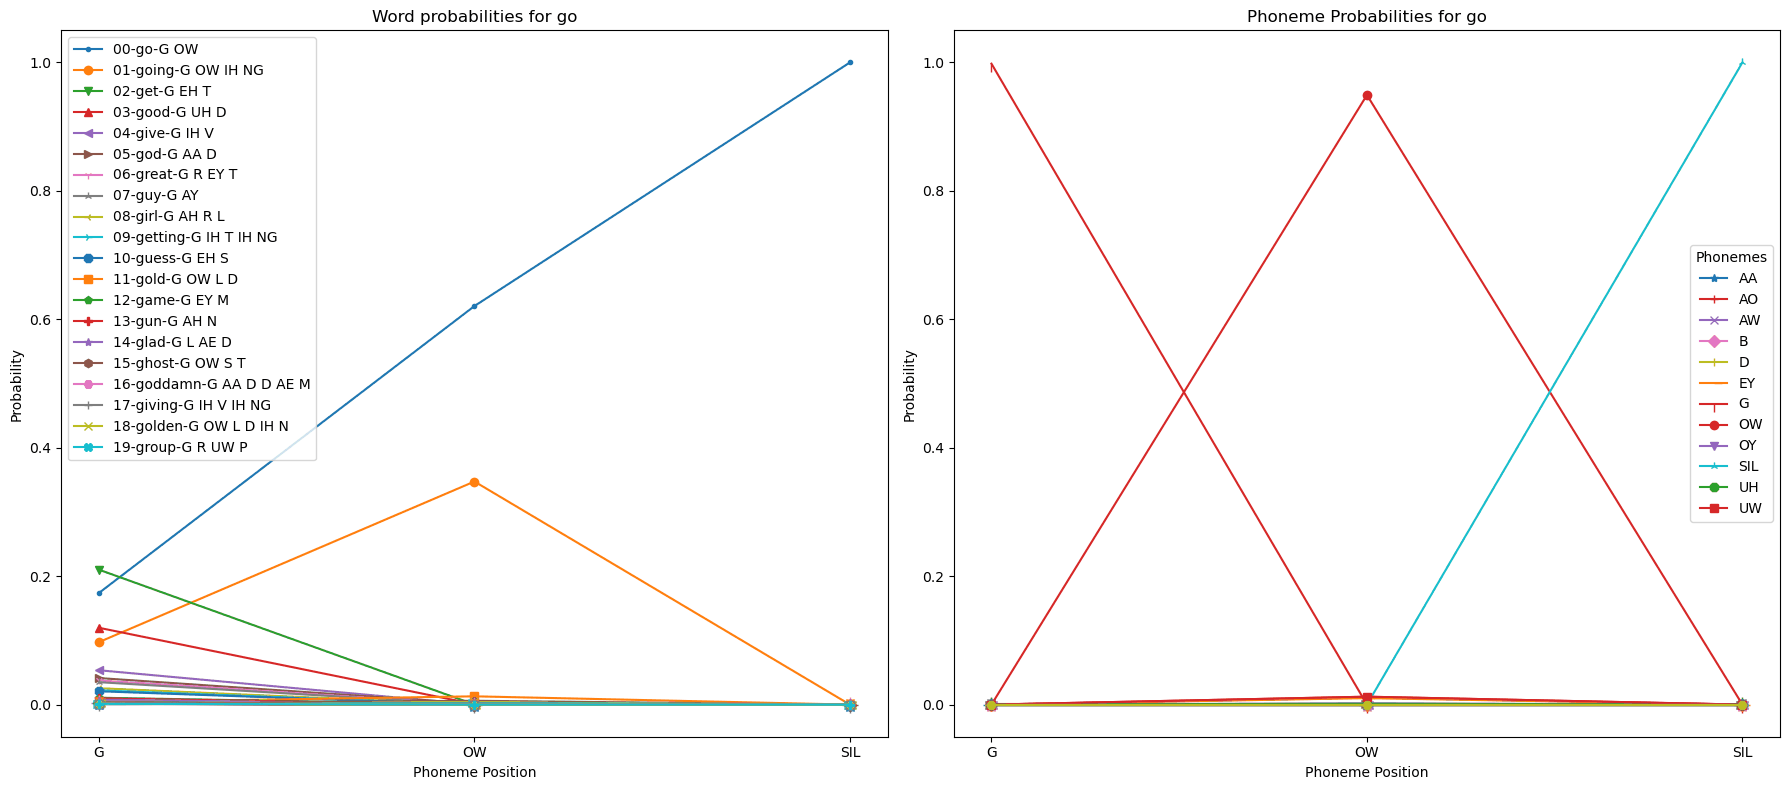

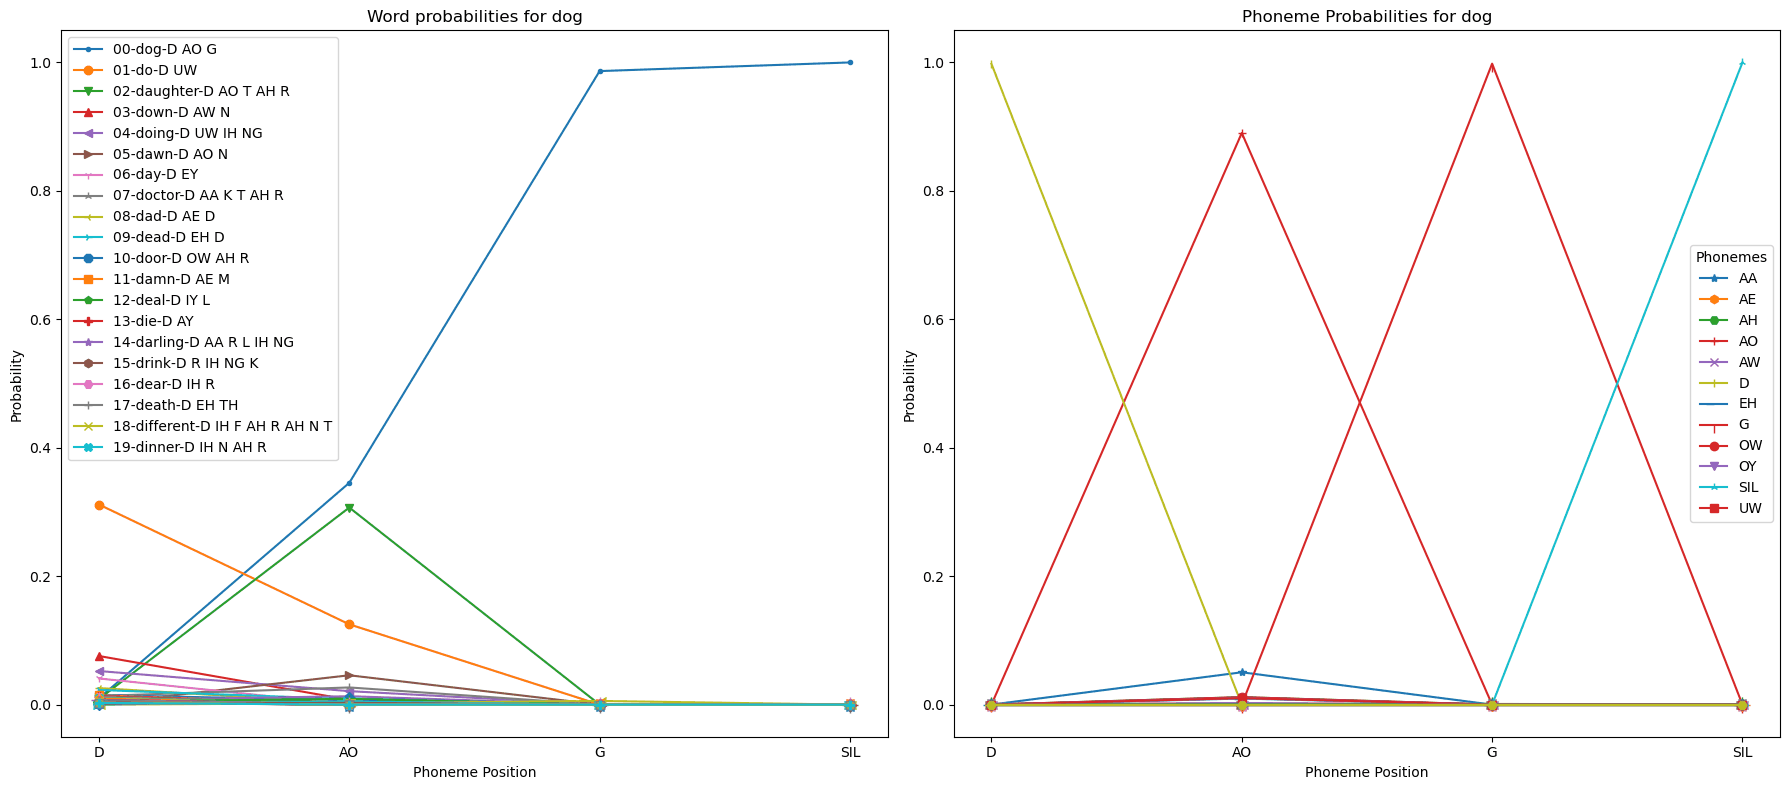

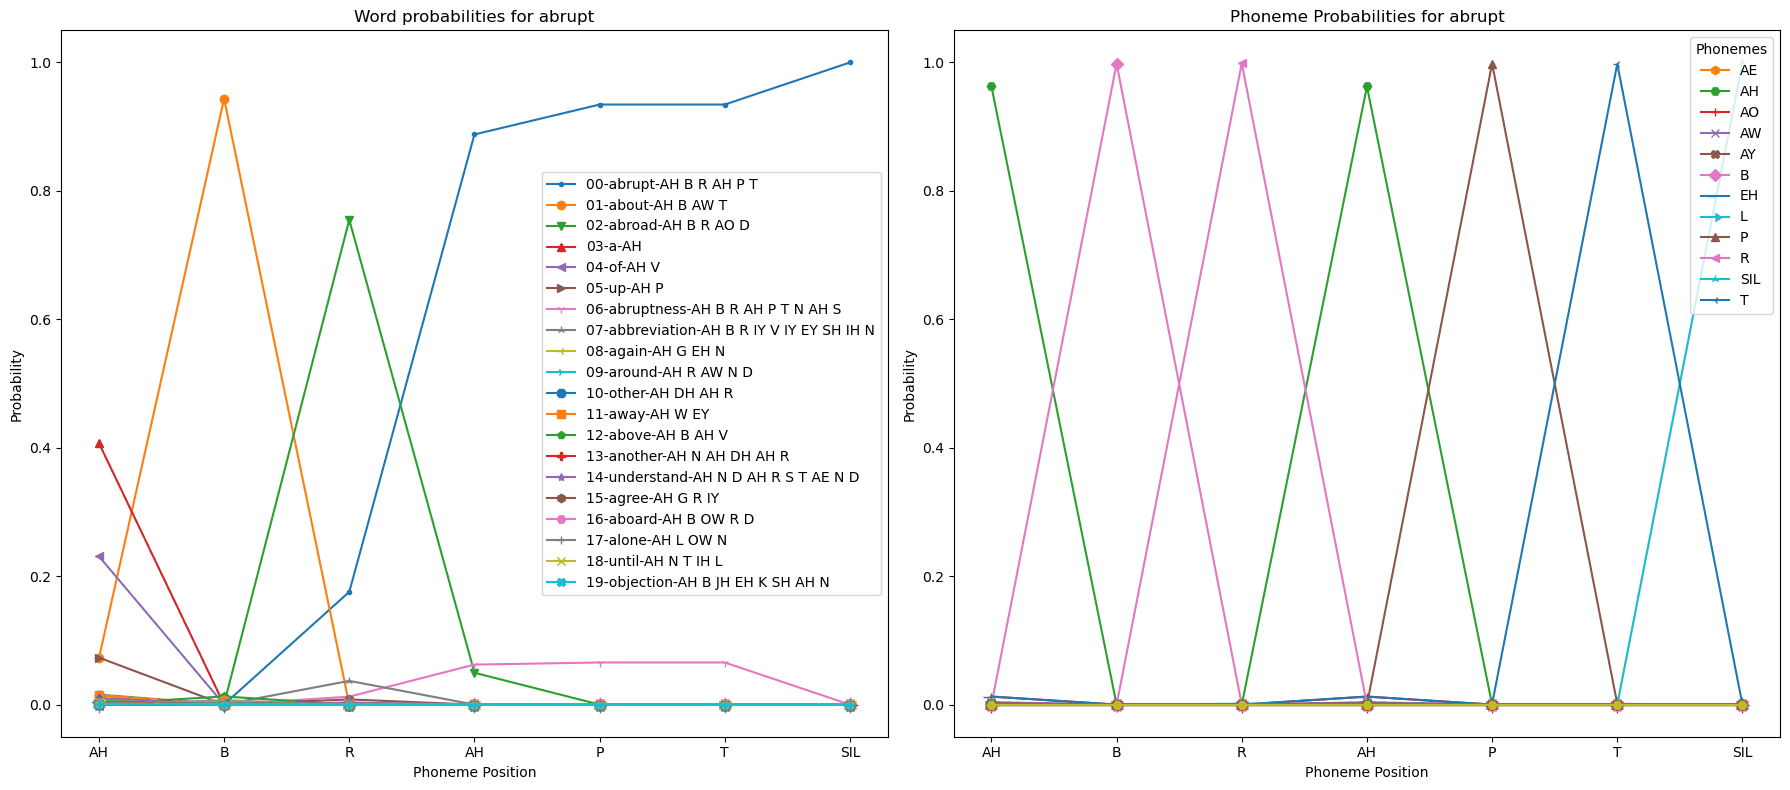

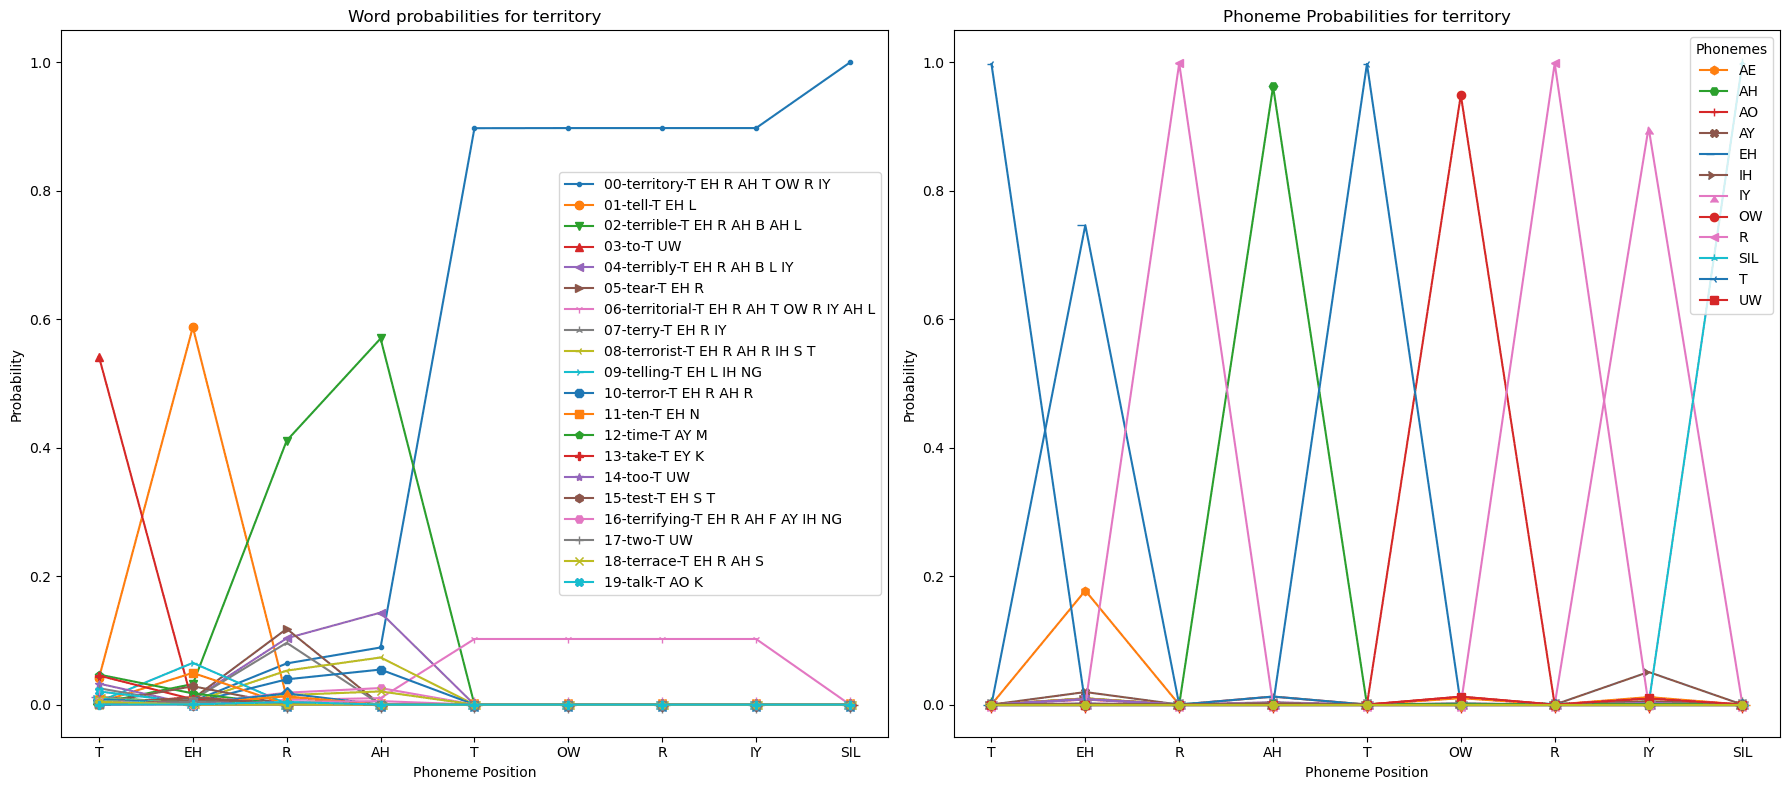

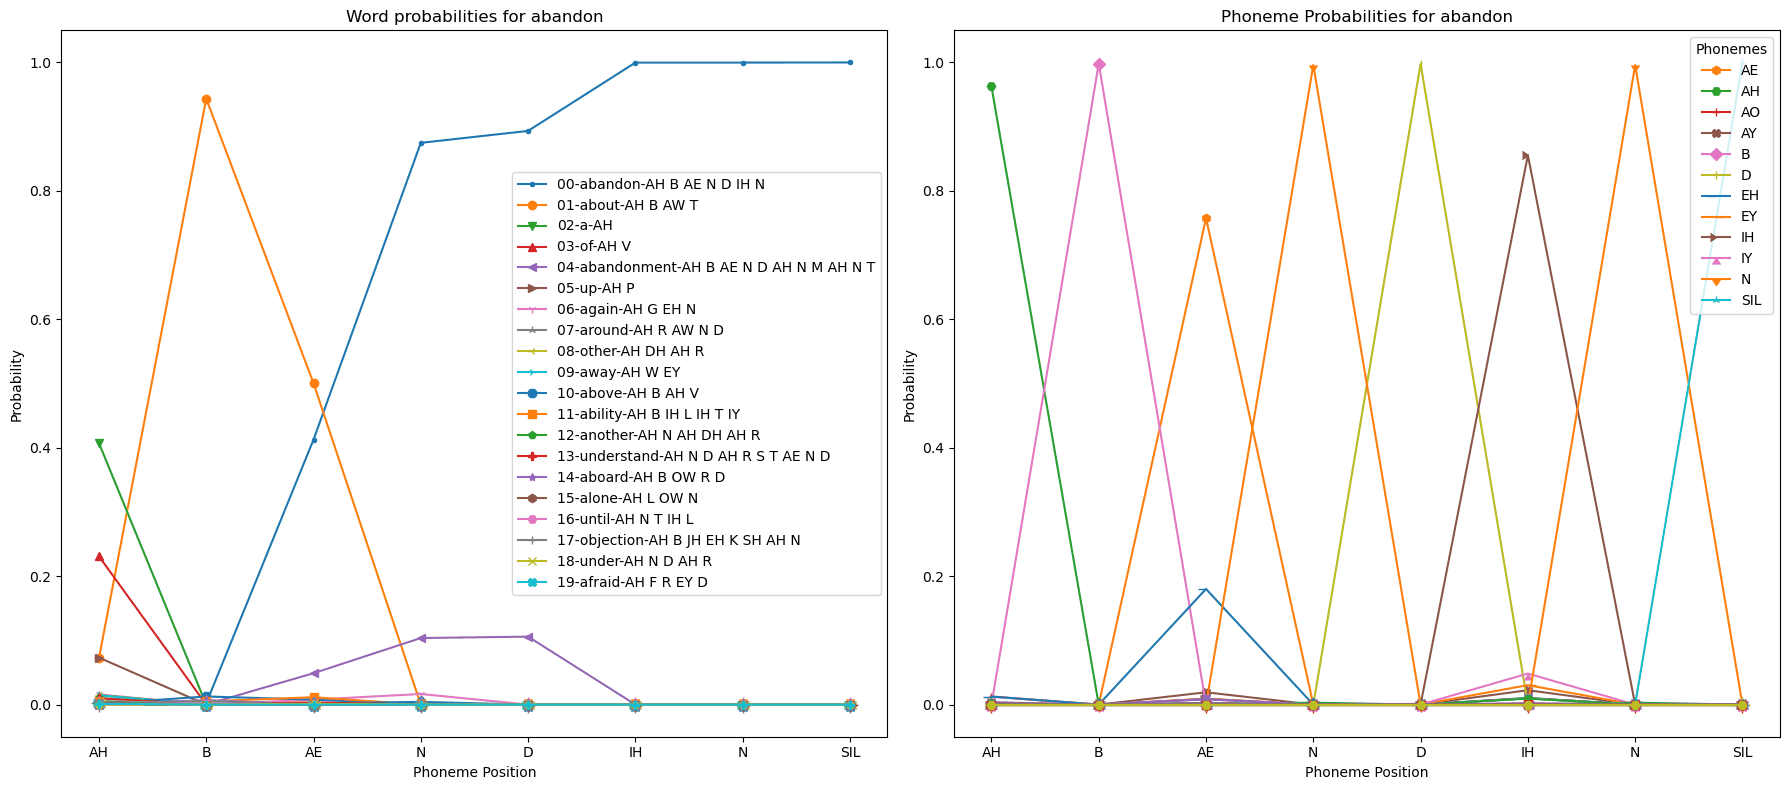

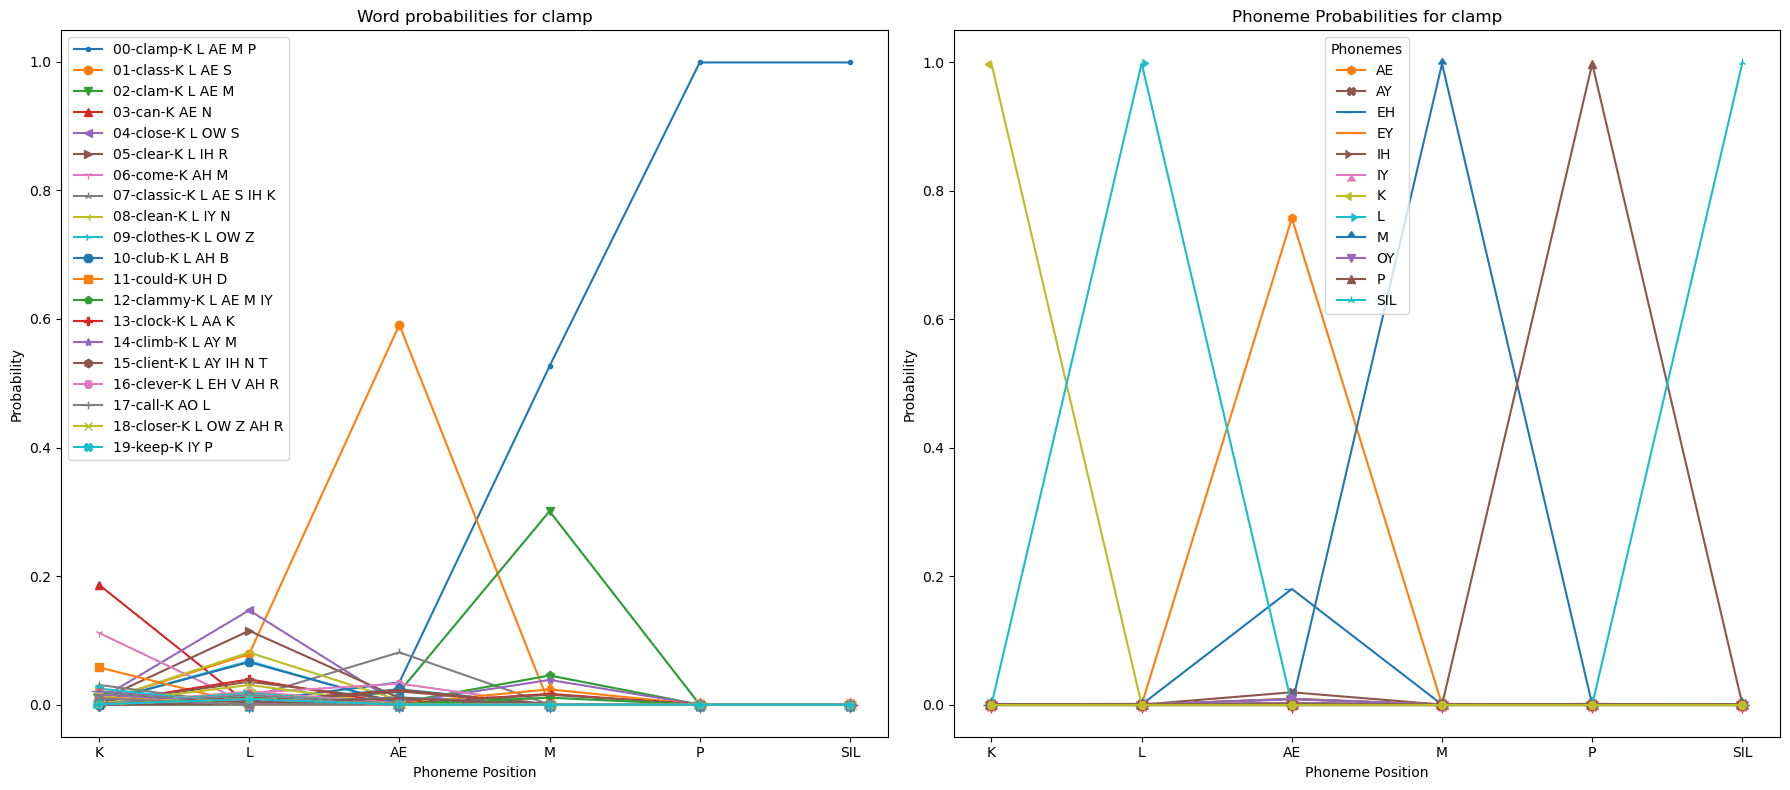

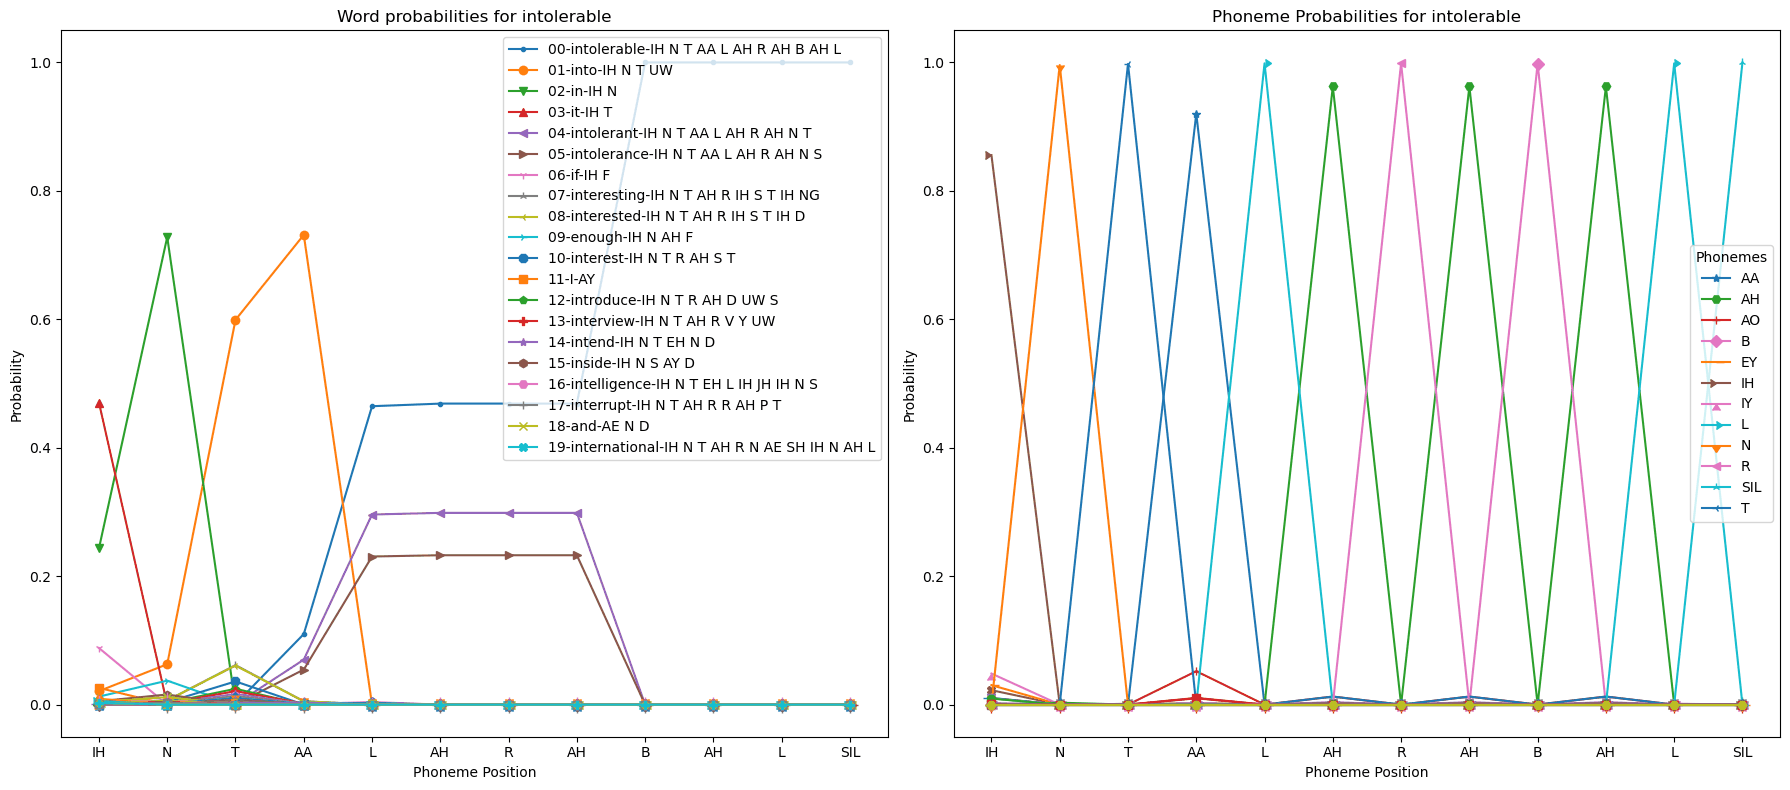

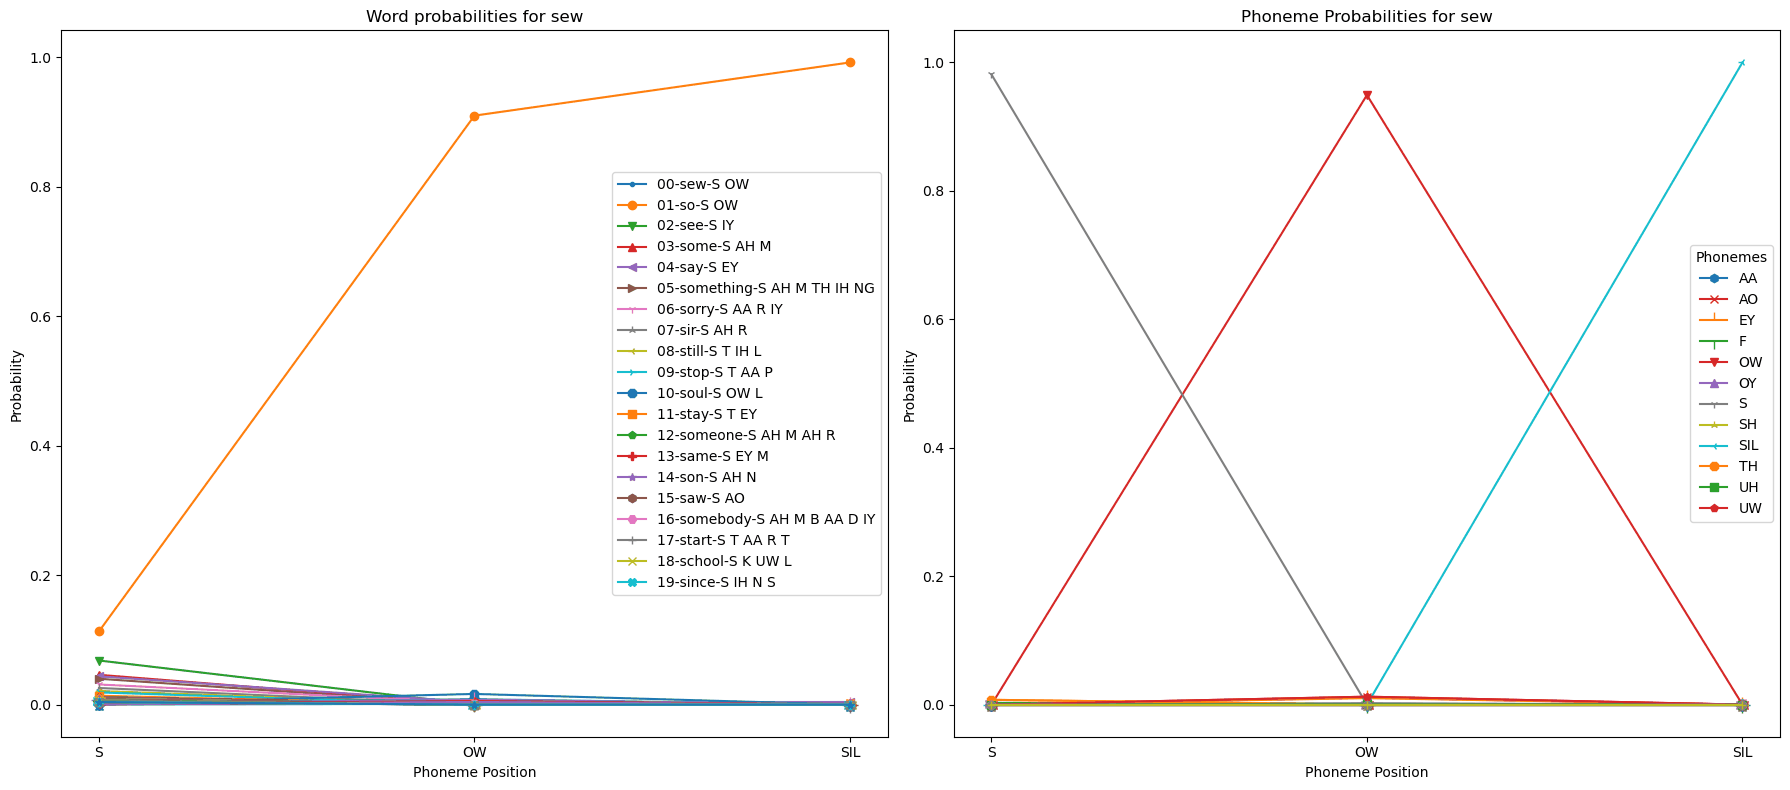

In [27]:
# Example usage:
word_list = ['boo', 'boot', 'go', 'dog', 'abrupt', 'territory', 'abandon', 'clamp', 'intolerable', 'sew']
aggregated_word_results, aggregated_phoneme_results = run_simulations(word_list, lexicon_df, 
                                                                      phoneme_confusion_df, phoneme_prob_dict)
plot_simulation_result(aggregated_word_results, aggregated_phoneme_results)

### Why is *boo* not recognized?

Look at *boo* in the plots above. Its phonemes come through clearly, and the silence after it arrives on time -- yet the model hears *be* (or *bee*). Why?

At the vowel, a clear /u/ gives /u/ a probability of about .95, and /i/ (the vowel of *be*) about .01: the bottom-up evidence favors /u/ by about 94 to 1. But *be/bee* is about 500 times as frequent as *boo*. In Bayes' theorem, the posterior odds are the prior odds times the evidence ratio, so *be* still comes out ahead, by about 500/94, or roughly 5 to 1. The silence does not help, because both *boo* and *be* end there.

So this is a case where **frequency overwhelms clear bottom-up evidence**, and it reveals two weaknesses of our model. First, the features make some vowels too similar (remember the RSA): listeners would rarely mistake a clear /u/ for /i/. Second, we calibrated the input so that even a perfectly clear phoneme gets only .95 of the probability, on average; real clear speech may be much clearer than that. Challenge question 11 asks you to look for a better balance between frequency and bottom-up evidence.

--- Starting simulation of word bickering	... Time for simulation: 0.056436 seconds
--- Starting simulation of word tail	... Time for simulation: 0.036313 seconds
--- Starting simulation of word tale	... Time for simulation: 0.036475 seconds
--- Starting simulation of word boo	... Time for simulation: 0.034839 seconds
--- Starting simulation of word sew	... Time for simulation: 0.033199 seconds
--- Starting simulation of word so	... Time for simulation: 0.034618 seconds


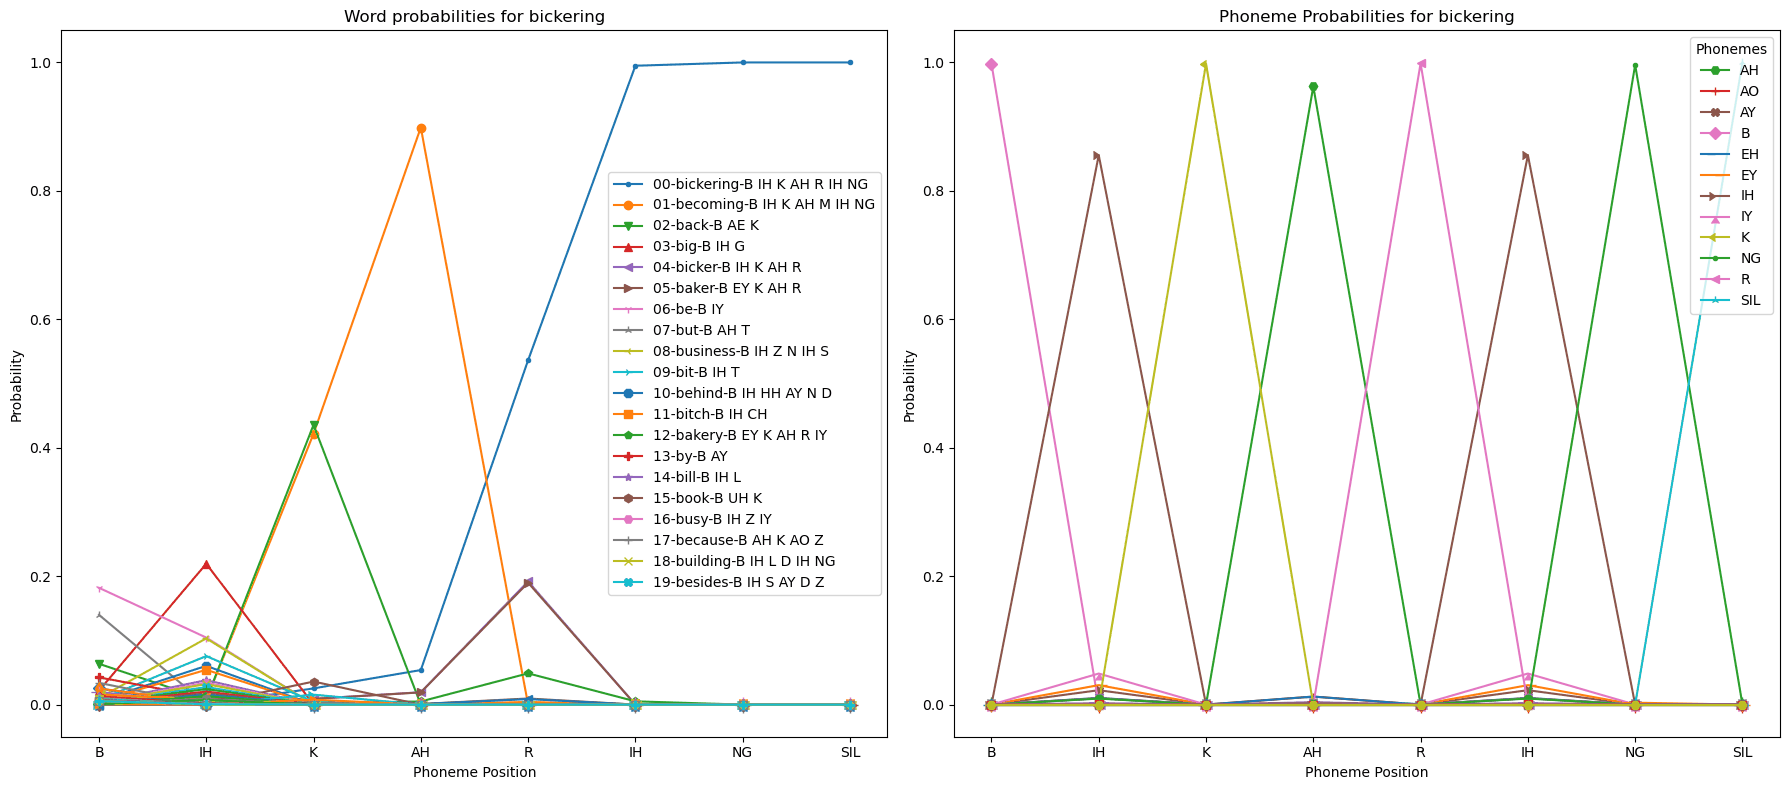

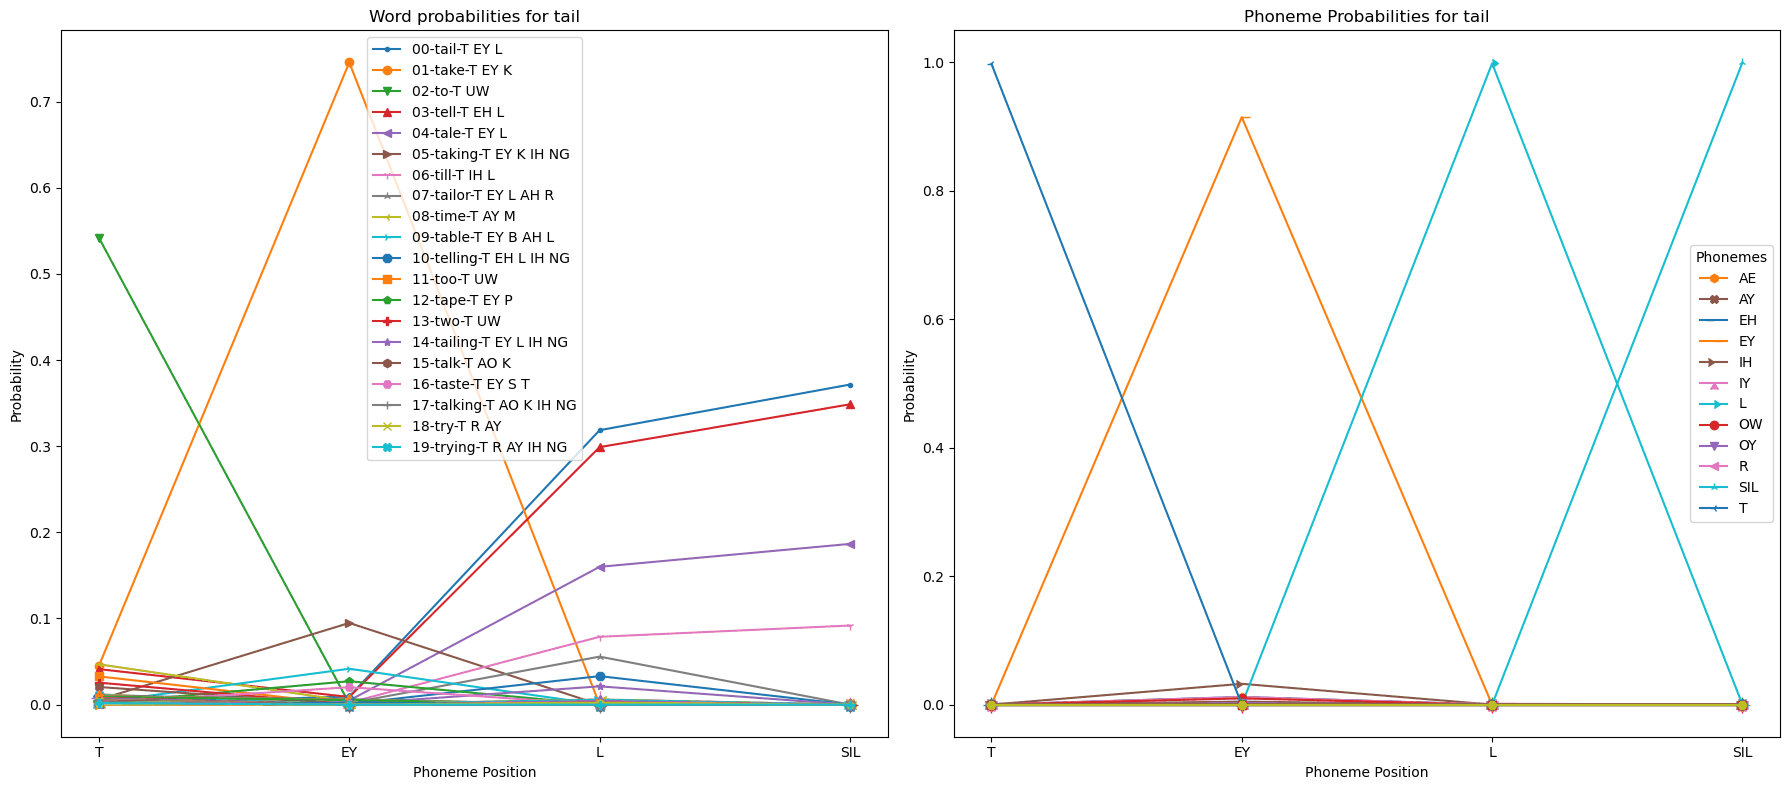

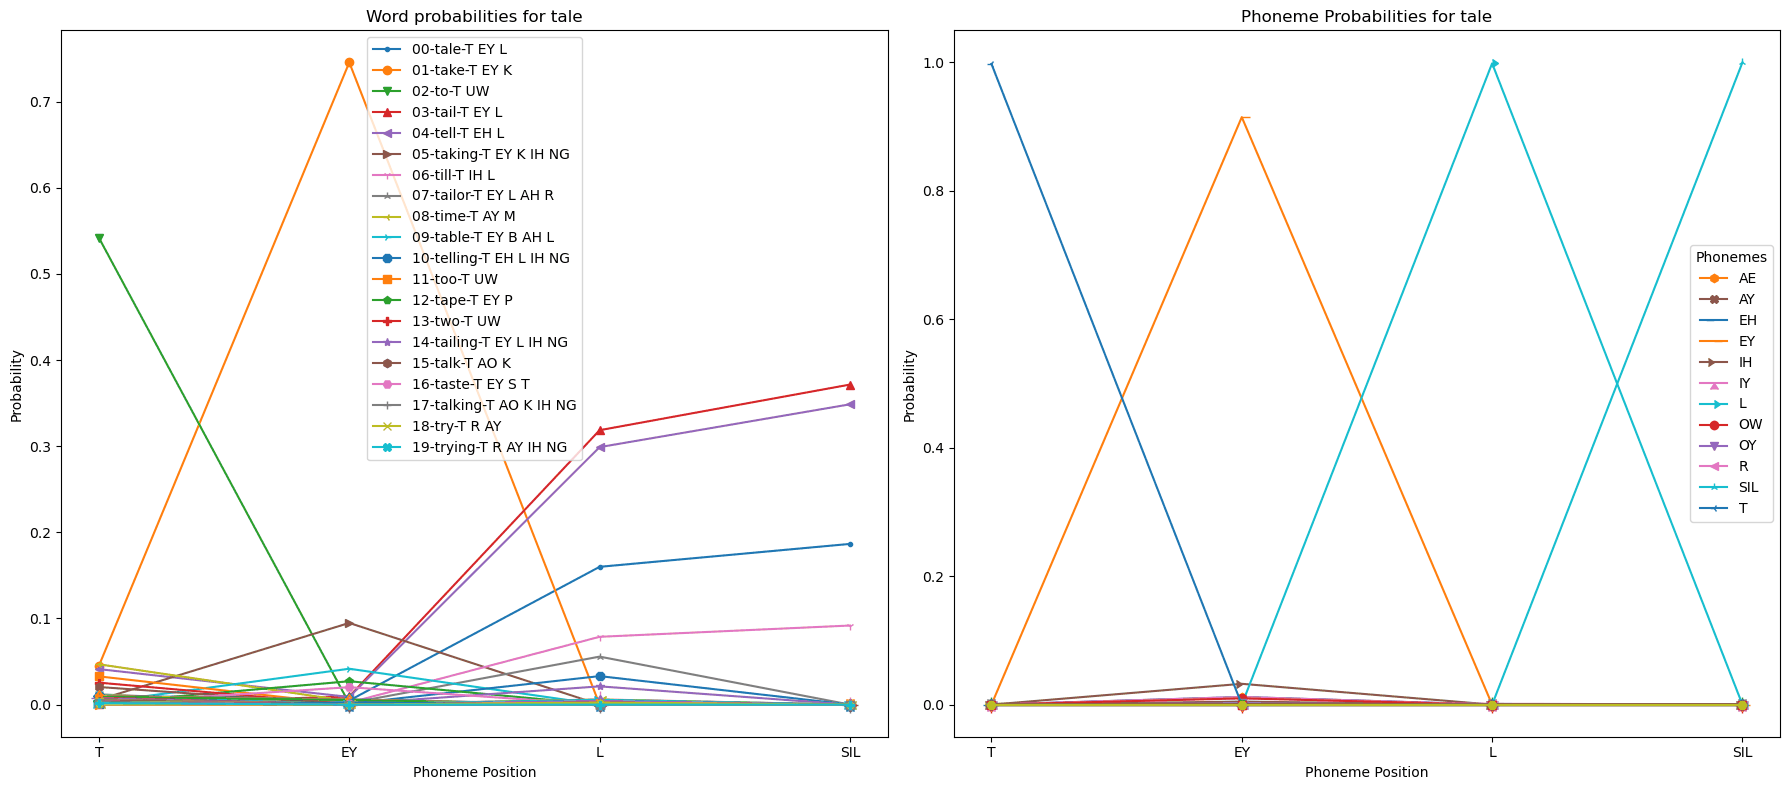

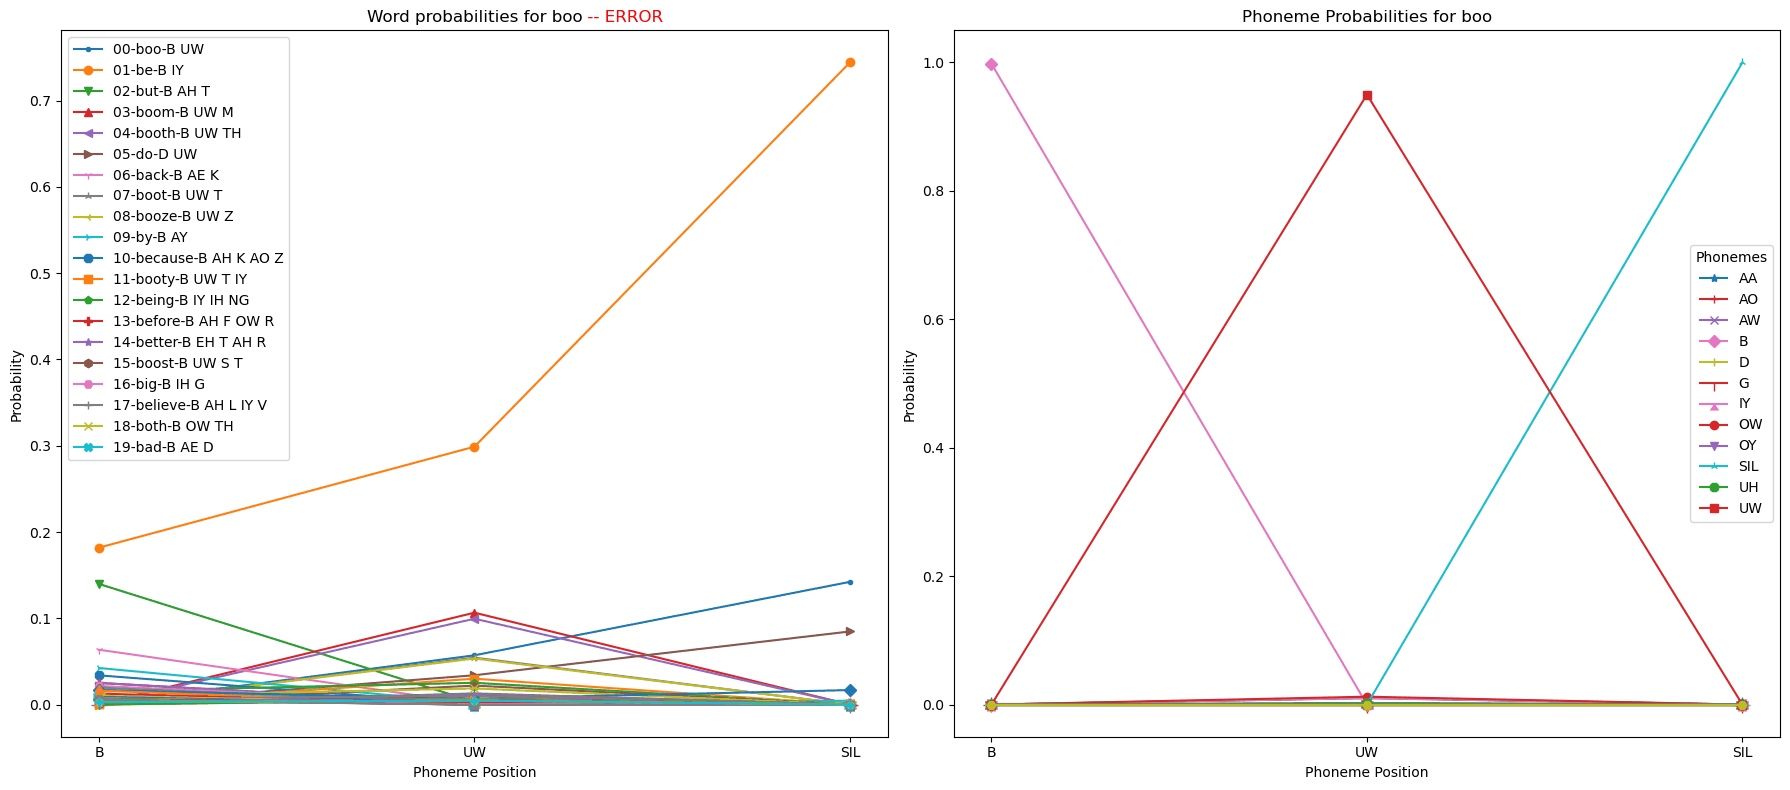

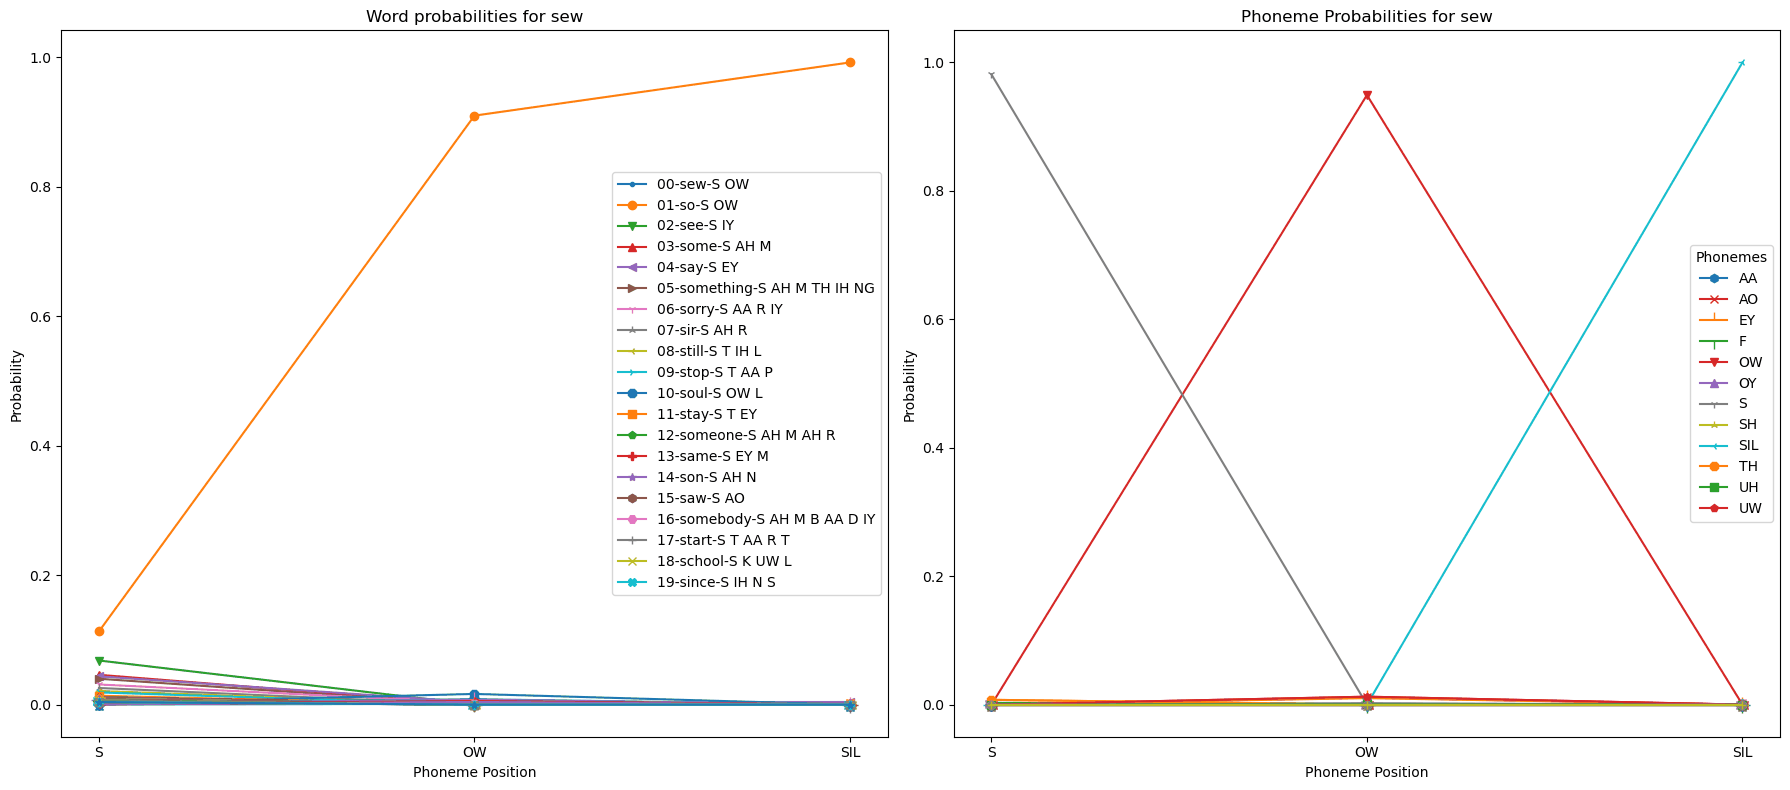

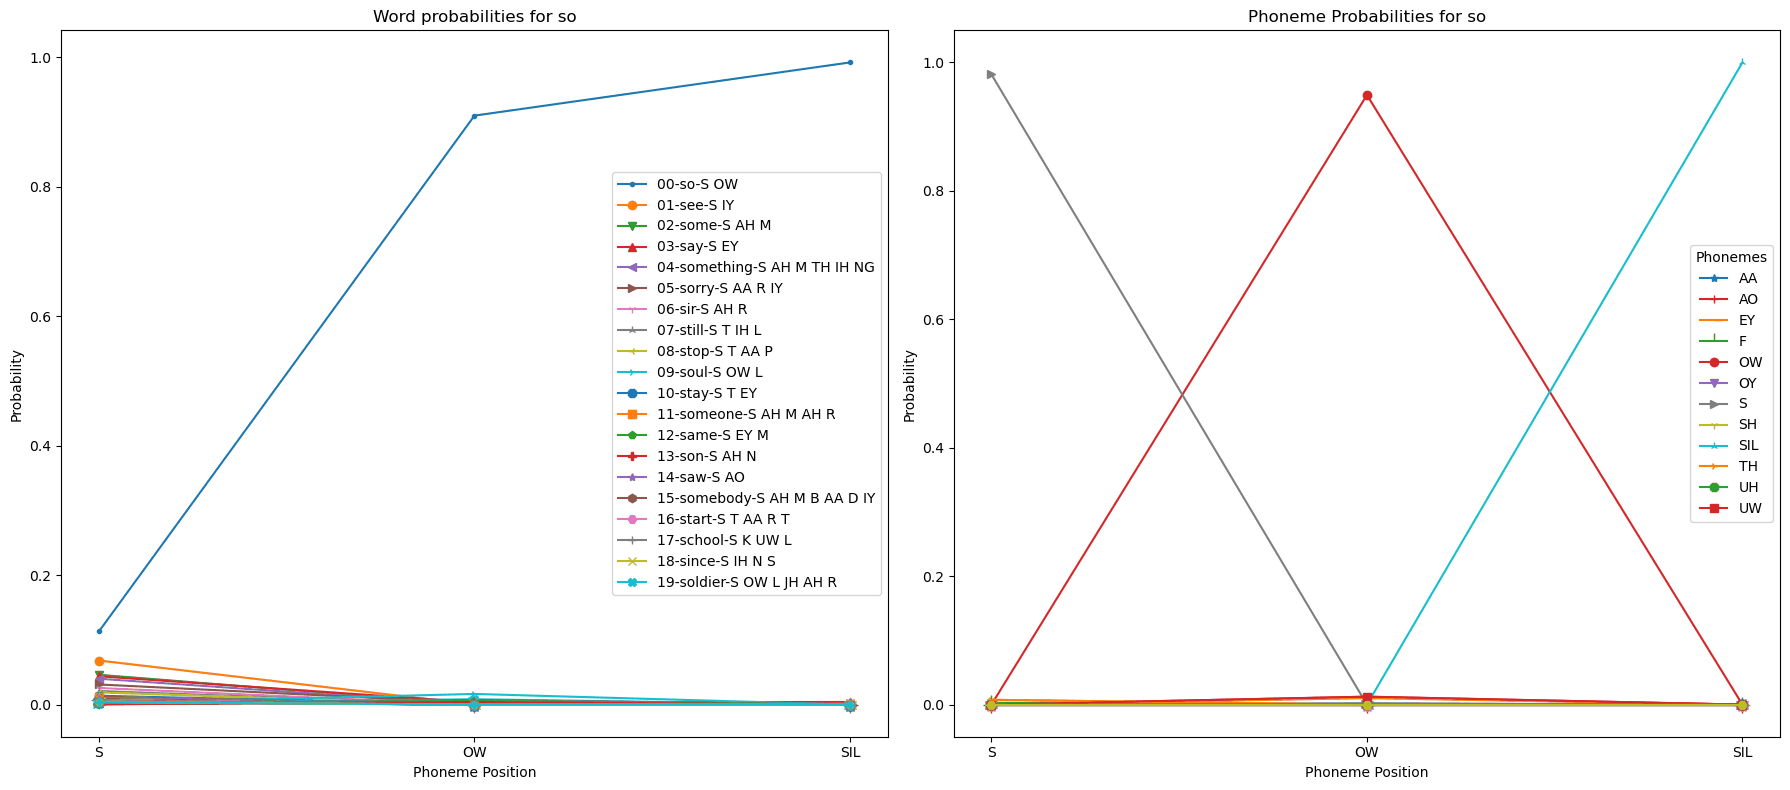

In [28]:

# Pick ONE word list -- whichever assignment runs last is the one that counts.
# word_list = ['tail', 'tale', 'boo', 'boat', 'cat', 'category', 'vernacular', 'rain', 'rainy', 'chew', 'cardinal', 'zodiacal']
# word_list = ['cat', 'dog', 'abrupt', 'territory', 'abandon', 'clamp', 'intolerable', 'go']
word_list = ['bickering', 'tail', 'tale', 'boo', 'sew', 'so']
aggregated_word_results, aggregated_phoneme_results = run_simulations(word_list, lexicon_df, phoneme_confusion_df, 
                                                                      phoneme_prob_dict)
plot_simulation_result(aggregated_word_results, aggregated_phoneme_results, full_scale=False)

-------

# Part 6

## Testing the model on the whole lexicon

So far we have simulated a handful of words at a time. To test the model properly, we should present *every* word in the lexicon and ask how many it recognizes correctly, and how quickly. Then we can compare the model's timing with human reaction times.

`sim_bayes_new` is too slow to run 17,000 times, so the function below does the same computation for many words at once. For each pronunciation in the lexicon (homophones pooled, as before), it presents the phonemes followed by silence, and records:

- **Recognized**: is the target more probable than every other word at the end of the input?
- **RP**, the *recognition point*: the position from which the target stays the most probable word through the end of the input. A word that takes the lead at its third phoneme and keeps it has an RP of 3. A word like *fine*, which is still tied with the beginning of the more frequent word *find* when its last phoneme arrives, only takes the lead at the silence, so its RP is its length + 1. (*cat* is also tied with the beginnings of longer words -- *cattle* and *category* -- when its last phoneme arrives, but it is more frequent than both, so its prior breaks the tie at once, and its RP is 3.)
- **Rival**: for words that are not recognized, the word that beat them.

The math is the same as in `sim_bayes_new`, with one shortcut. To decide which word is the most probable, we only need to compare each word's score: its log prior plus its log likelihood. The denominator of Bayes' theorem is the same for every word, so we can skip it.

In [29]:
import time
from collections import Counter
from tqdm.auto import tqdm   # progress bars

def recognize_lexicon(lexicon_df, phoneme_confusion_df, chunk_size=300, label='words'):
    '''
    Present every pronunciation in the lexicon, followed by silence, and record
    whether it is recognized and its recognition point. Same math as sim_bayes_new
    (raw frequency prior, homophones pooled), done for many words at once.

    Returns a DataFrame indexed by pronunciation, with columns Words, Frequency
    (summed over homophones), n_words, Length, Recognized, RP, and Rival.
    Shows a progress bar (named by label) and prints how long the run took.
    '''
    start_time = time.time()
    # Pool homophones: one row per pronunciation, with its spellings joined by '/' (Words),
    # their summed frequency (Frequency), and how many spellings it has (n_words)
    by_pron = lexicon_df.groupby('Pronunciation').agg(
        Words=('Item', lambda w: '/'.join(map(str, w))),
        Frequency=('Frequency', 'sum'), n_words=('Item', 'size'))
    pronunciations = by_pron.index.to_numpy()
    phoneme_lists = [p.split() for p in pronunciations]
    lengths = np.array([len(p) for p in phoneme_lists])

    # Code each pronunciation as a row of symbol numbers, padded with silence
    symbol_index = {s: i for i, s in enumerate(phoneme_confusion_df.columns)}
    codes = np.full((len(pronunciations), lengths.max() + 1), symbol_index[SILENCE])
    for i, phonemes in enumerate(phoneme_lists):
        codes[i, :len(phonemes)] = [symbol_index[p] for p in phonemes]

    log_confusion = np.log(phoneme_confusion_df.values)
    log_prior = np.log(by_pron['Frequency'].values)   # the normalizing constant cancels

    recognized = np.zeros(len(pronunciations), dtype=bool)
    recognition_point = np.full(len(pronunciations), np.nan)
    rival = np.empty(len(pronunciations), dtype=object)

    # Words of the same length get the same number of input positions, so we
    # process them together, chunk_size targets at a time
    progress_bar = tqdm(total=len(pronunciations), desc=label, unit='word')
    for length in np.unique(lengths):
        targets = np.flatnonzero(lengths == length)
        for start in range(0, len(targets), chunk_size):
            batch = targets[start:start + chunk_size]
            rows = np.arange(len(batch))
            score = np.tile(log_prior, (len(batch), 1))      # one row per target, one column per candidate
            on_top = np.zeros((len(batch), length + 1), dtype=bool)
            for t in range(length + 1):                      # the phonemes, then the silence
                # Each candidate word's evidence at position t is log P(its OWN symbol at t | the
                # input symbol at t). We get it in two steps:
                input_symbols = codes[batch, t]                  # the input symbol for each target
                rows_for_inputs = log_confusion[input_symbols]   # the confusion row for each input
                candidate_symbols = codes[:, t]                  # every candidate's own symbol at t
                score += rows_for_inputs[:, candidate_symbols]   # each candidate's entry in that row
                own = score[rows, batch].copy()
                score[rows, batch] = -np.inf                 # hide the target to find its best competitor
                best_other = score.argmax(axis=1)
                on_top[:, t] = own > score[rows, best_other]
                score[rows, batch] = own
            recognized[batch] = on_top[:, -1]
            rival[batch] = np.where(on_top[:, -1], '', pronunciations[best_other])
            # RP = one position after the last position where the target was NOT on top
            for j, i in enumerate(batch):
                if on_top[j, -1]:
                    not_on_top = np.flatnonzero(~on_top[j])
                    recognition_point[i] = not_on_top[-1] + 2 if len(not_on_top) else 1
            progress_bar.update(len(batch))
    progress_bar.close()

    seconds = time.time() - start_time
    print(f'{label}: {len(pronunciations)} words (homophones pooled) in {seconds:.1f} s '
          f'({1000 * seconds / len(pronunciations):.2f} ms per word)')
    return by_pron.assign(Length=lengths, Recognized=recognized, RP=recognition_point, Rival=rival)


def describe_error(target_pronunciation, rival_pronunciation):
    # Name the confusion behind an error: 'AA-AO' if the two pronunciations differ in one phoneme
    a, b = target_pronunciation.split(), rival_pronunciation.split()
    if len(a) != len(b):
        return 'different length'
    differences = ['-'.join(sorted([x, y])) for x, y in zip(a, b) if x != y]
    return differences[0] if len(differences) == 1 else 'several phonemes'

### How accurate is the model?

Let's run every word in the lexicon through the feature-based model, at our default clarity (calibrated so that a single clear phoneme gets .95 of the probability, on average). This takes only a few seconds.

In [ ]:
model_results = recognize_lexicon(lexicon_df, phoneme_confusion_df, label='feature-based model')

errors = model_results[~model_results['Recognized']]
n_errors = errors['n_words'].sum()   # count homophones as separate words
print(f"{n_errors} word errors out of {len(lexicon_df)} words: {100 * (1 - n_errors / len(lexicon_df)):.2f}% correct")

# What kinds of errors? 'AE-EH' means the target and its rival differ only in /ae/ vs. /eh/
confusions = Counter(describe_error(p, r) for p, r in zip(errors.index, errors['Rival']))
print('Most common confusions:', confusions.most_common(8))

# The most frequent words the model gets wrong, and the words that beat them. Rival is a
# pronunciation, so we look up its spelling(s) the same way as for the targets.
errors = errors.copy()   # a separate table, so we can add a column to it
errors['Rival words'] = errors['Rival'].map(model_results['Words'])
display(errors.sort_values('Frequency', ascending=False).head(10)[['Words', 'Frequency', 'Rival', 'Rival words']])

A few things to notice.

- **The model is quite accurate.** It gets 436 of the 17,743 words wrong: 97.5% correct. That might seem surprising, since a single clear phoneme gets only .95 of the probability, on average. But the two numbers measure different things. A word counts as correct if it is the *most probable* word, and for a clear input the correct phoneme is always the most probable phoneme, too. So the model's errors do not come from the input: they happen when the word prior outweighs the evidence, as for *boo*. (For a fair comparison of words and single phonemes, see the noise demo in Part 7, where the input really is noisy. There, words are recognized much more accurately than single phonemes, because the lexicon constrains which sequences are possible.)
- **Most of its errors (about 6 in 7) are vowel confusions.** The most common are /æ/ vs. /ɛ/ (AE-EH, as in *bat* and *bet*; 56 errors), /eɪ/ vs. /ɪ/ (EY-IH), /æ/ vs. /aɪ/ (AE-AY), /eɪ/ vs. /i/ (EY-IY), and /ɪ/ vs. /i/ (IH-IY). The most frequent words it misses are *end* (heard as *and*), *eat* and *eight* (both heard as *it*), *wear* (*where*), and *gas* (*guess*): in each case, the rival is a more frequent word that differs in one vowel.
- **Some of these errors are human, some are not.** Listeners do confuse /æ/ and /ɛ/ fairly often: in Luce's data it is the 6th most confusable of the 91 vowel pairs. But /eɪ/-/ɪ/ and /eɪ/-/i/ fall in the middle of that list, and /æ/-/aɪ/ and /aʊ/-/aɪ/ in the lower third. These pairs are close in the feature table because of how the vowels were coded -- the same problem the RSA revealed. Better vowel features would be a good project; challenge question 9 lets you compare the model with Luce's confusion-based version.

### Model reaction times vs. human reaction times

The model has no clock: it has positions, and a probability for every word at each one. To compare it with listeners, we need an *operational definition* of recognition time: a rule that turns the model's changing probabilities into a single number per word. There are several reasonable choices. We could take the first position at which the target's probability exceeds some threshold, such as .9 (but which threshold?). Or we could use the *recognition point* (RP) defined above: the position from which the target stays the most probable word. The RP needs no extra parameter, so we use it here. Notice what it ignores, though: it uses only the *ranking* of the words, not how sure the model is. (Challenge question 7 asks you to try one of the alternatives.) The idea is simply that the sooner a word becomes the clear winner, the sooner a listener could respond. Let's compare it with real data. The Auditory English Lexicon Project (AELP; Goh, Yap, & Chee, 2020) recorded *auditory lexical decision* times -- is what you heard a word or not? -- for about 10,000 spoken words. We use the mean RTs for the two American English talkers (`data/aelp/aelp_item_summary_us.csv`), keeping words that had at least 10 correct responses and at least 67% accuracy. Human RTs are in milliseconds from word onset; the model's recognition points are in phoneme positions.

First, let's simply look at the data. Each dot in the plots below is one word: its human RT against the model's recognition point. The dots are jittered a little left and right, because recognition points are whole numbers and would otherwise pile up in columns. The line connects the mean human RT at each recognition point.

In [ ]:
def uniqueness_points(pronunciations):
    # For each pronunciation: the first position at which no other pronunciation
    # shares its beginning (length + 1 if it is the beginning of a longer word)

    # Step 1: count how many pronunciations start with each beginning (prefix),
    # e.g., for cat: 'K', 'K AE', and 'K AE T'
    prefix_counts = Counter()
    for pronunciation in pronunciations:
        phonemes = pronunciation.split()
        for k in range(1, len(phonemes) + 1):
            prefix_counts[' '.join(phonemes[:k])] += 1

    # Step 2: a word's UP is the length of its shortest prefix that no other word has
    ups = []
    for pronunciation in pronunciations:
        phonemes = pronunciation.split()
        up = len(phonemes) + 1             # unless we find one, it is never unique before its end
        for k in range(1, len(phonemes) + 1):
            if prefix_counts[' '.join(phonemes[:k])] == 1:
                up = k
                break
        ups.append(up)
    return ups


# Human RTs: AELP item means, matched to our lexicon by spelling
aelp_df = pd.read_csv('./data/aelp/aelp_item_summary_us.csv', keep_default_na=False, na_values=[''])
aelp_df = aelp_df[(aelp_df['n_rt'] >= 10) & (aelp_df['accuracy'] >= 0.67)].copy()
# Match AELP items to our lexicon by spelling, ignoring capitalization: make a lowercase spelling
# column ('key'), keep one entry per spelling, and use the spelling as the index, so that
# lexicon_by_item.loc['cat'] is the row for 'cat'
lexicon_by_item = lexicon_df.copy()
lexicon_by_item['key'] = lexicon_by_item['Item'].astype(str).str.lower()
lexicon_by_item = lexicon_by_item.drop_duplicates('key').set_index('key')
aelp_df = aelp_df[aelp_df['item'].str.lower().isin(lexicon_by_item.index)].copy()
aelp_df['Pronunciation'] = aelp_df['item'].str.lower().map(lexicon_by_item['Pronunciation'])
aelp_df['log_frequency'] = np.log(aelp_df['item'].str.lower().map(lexicon_by_item['Frequency']))

# Model data: length, UP, and recognition points at our default clarity
up = pd.Series(uniqueness_points(model_results.index), index=model_results.index)
aelp_df['length'] = aelp_df['Pronunciation'].map(model_results['Length'])
aelp_df['UP'] = aelp_df['Pronunciation'].map(up)
aelp_df['RP_model'] = aelp_df['Pronunciation'].map(model_results['RP'])
aelp_df = aelp_df.dropna(subset=['RP_model'])   # words the model recognizes
print(f"{len(aelp_df)} words")

# Scatterplot: one dot per word
rng = np.random.default_rng(1)
fig, ax = plt.subplots(figsize=(7, 5))
jitter = rng.uniform(-0.3, 0.3, len(aelp_df))
ax.scatter(aelp_df['RP_model'] + jitter, aelp_df['rt_onset'], s=4, alpha=0.2, label='one word')
# Mean human RT at each recognition point, and how many words went into each mean
by_rp = aelp_df.groupby('RP_model')['rt_onset'].agg(['mean', 'size'])
ax.plot(by_rp.index, by_rp['mean'], color='black', marker='o', label='mean RT at each recognition point')
# Write each n in a row along the bottom of the plot (x in data units, y in axes units),
# after making a little room for it below the lowest dots
low, high = ax.get_ylim()
ax.set_ylim(low - 0.06 * (high - low), high)
for rp, row in by_rp.iterrows():
    ax.text(rp, 0.02, f"n={int(row['size'])}", transform=ax.get_xaxis_transform(), ha='center', fontsize=7)
legend = ax.legend(loc='upper left')
# (legend_handles is called legendHandles in matplotlib versions before 3.7)
handles = getattr(legend, 'legend_handles', None) or legend.legendHandles
handles[0].set_sizes([30])   # a bigger, solid dot in the legend than in the plot
handles[0].set_alpha(1)
r = aelp_df['RP_model'].corr(aelp_df['rt_onset'])
ax.set_title(f'Human RT vs. model recognition point: r = {r:.2f}')
ax.set_xlabel('Model recognition point (phoneme position)')
ax.set_ylabel('Human RT from word onset (ms, AELP)')
plt.tight_layout()
plt.show()

### Scatterplots

In notebook 06 we used scatterplot matrices to look at pseudo data. Now we can make plots like them with real data, for three properties of each word -- its log frequency, its length in phonemes, and its *uniqueness point* (UP), the position where it becomes the only word in the lexicon that matches the input so far -- plus two measures of competition:

- **cohort size**: the number of other words that share the word's first two phonemes, a simple version of the 'onset competitors' from notebook 06;
- **continuation frequency**: the summed frequency of the longer words that begin with the whole word -- for *can*, words like *candy*, *candle*, and *cancel*. These are the competitors still in the running when the word *ends*. We use log(summed frequency + 1): the log because the raw sums are hugely skewed, as word frequencies are, and the + 1 so that words with no continuations (about two-thirds of them) get log(1) = 0, since log(0) is undefined.

First, a scatterplot matrix shows how these five predictors relate to each other: a histogram of each one on the diagonal, and a scatterplot with a line of best fit and the correlation (R) for each pair. (Notebook 06 also showed the upper triangle, but it only repeats the lower one with the axes swapped.) Then a grid of plots shows how each predictor relates to the outcome, one predictor per row: human RT on the left, and the model's recognition point on the right.

In [ ]:
# Cohort size: how many OTHER words share the word's first two phonemes

def onset_of(pronunciation):
    # The first two phonemes, e.g., 'K AE T' (cat) -> 'K AE'. (For the few one-phoneme words,
    # this is the whole word, so their cohort size is 0.)
    phonemes = pronunciation.split()
    return ' '.join(phonemes[:2])

# Step 1: go through the lexicon and count how many words start with each onset
onset_counts = {}
for pronunciation in model_results.index:    # every pronunciation (homophones counted once)
    onset = onset_of(pronunciation)
    if onset in onset_counts:
        onset_counts[onset] += 1
    else:
        onset_counts[onset] = 1

# Step 2: a word's cohort size is the count for its onset, minus 1 (the word itself)
def cohort_size(pronunciation):
    return onset_counts[onset_of(pronunciation)] - 1

print('cohort size of cat:', cohort_size('K AE T'))
aelp_df['cohorts'] = aelp_df['Pronunciation'].apply(cohort_size)


# Continuation frequency: the summed frequency of the longer words that begin with the whole word

# Step 1: for every beginning (prefix) of every pronunciation, add up the frequencies of the words
#         that start with it. (Frequency here is summed over homophones, as in the model.)
prefix_frequency = {}
for pronunciation, frequency in zip(model_results.index, model_results['Frequency']):
    phonemes = pronunciation.split()
    for k in range(1, len(phonemes) + 1):
        prefix = ' '.join(phonemes[:k])
        if prefix in prefix_frequency:
            prefix_frequency[prefix] += frequency
        else:
            prefix_frequency[prefix] = frequency

# Step 2: a word's prefix total includes the word itself, so subtract its own frequency
def continuation_frequency(pronunciation):
    return prefix_frequency[pronunciation] - model_results.loc[pronunciation, 'Frequency']

print('summed continuation frequency of can:', round(continuation_frequency('K AE N'), 1))
print('summed continuation frequency of dog:', round(continuation_frequency('D AO G'), 1))
aelp_df['continuations'] = np.log(aelp_df['Pronunciation'].apply(continuation_frequency) + 1)
print(f"words with no continuations: {(aelp_df['continuations'] == 0).mean():.0%}")


def annotate_r(x, y, **kwargs):
    # Print the correlation in the corner of a scatterplot panel (as in notebook 06)
    r = np.corrcoef(x, y)[0, 1]
    plt.gca().annotate(f"R = {r:.2f}", xy=(.1, .9), xycoords='axes fraction', fontweight='bold', color='red',
                       bbox=dict(facecolor='white', alpha=0.8, edgecolor='none'))


properties = {'log_frequency': 'log frequency', 'length': 'length', 'UP': 'uniqueness point',
              'cohorts': 'cohorts', 'continuations': 'continuation freq. (log)'}

# 1. The predictors against each other. corner=True draws only the lower triangle,
#    since the upper triangle would show the same pairs again.
grid = sns.PairGrid(aelp_df[list(properties)].rename(columns=properties), height=2.2, corner=True)
grid.map_lower(sns.regplot, ci=None, scatter_kws={'s': 2, 'alpha': 0.1}, line_kws={'color': 'red'})
grid.map_lower(annotate_r)
grid.map_diag(plt.hist, bins=30)
grid.figure.suptitle('How the predictors relate to each other', y=1.02)
plt.show()


# 2. Each predictor (one per row) against human RT (left column) and the model's recognition
#    point (right column). sharey='col' gives each column one shared y-axis.
outcomes = [('rt_onset', 'RT (ms)', 'Humans (AELP)'), ('RP_model', 'recognition point', 'Model')]
fig, axes = plt.subplots(len(properties), 2, figsize=(10, 3 * len(properties)), sharey='col')
for row, (column, label) in enumerate(properties.items()):
    for col, (outcome, outcome_label, who) in enumerate(outcomes):
        ax = axes[row, col]
        sns.regplot(x=aelp_df[column], y=aelp_df[outcome], ax=ax, ci=None,
                    scatter_kws={'s': 2, 'alpha': 0.1}, line_kws={'color': 'red'})
        r = aelp_df[column].corr(aelp_df[outcome])
        ax.set_title(f'{who}: R = {r:.2f}')
        ax.set_xlabel(label)
        ax.set_ylabel(outcome_label)
plt.tight_layout()
plt.show()

Compare the two rows of plots. The model's recognition point correlates .66 with the uniqueness point, but human RT only .27; human RT goes with length (.49) and frequency (−.46) instead. But the matrices show each property one at a time, and the properties are correlated with each other (look at length and uniqueness point), so we cannot tell from the plots which ones really matter. And since the units differ, we cannot compare the human and model numbers directly. Instead, we fit the *same* regression to both, predicting RT from four properties of each word (we leave out cohort size, which we plotted above; challenge question 10 asks you to add neighbors):

- **log frequency**,
- **length** in phonemes,
- **uniqueness point (UP)**: the position where the word becomes the only word in the lexicon that matches the input so far. Words like *cat*, which are the beginnings of longer words, only become unique at the silence after them, so their UP is their length + 1, and
- **continuation frequency** (defined above): the competitors still in the running when the word ends, so the more frequent they are, the less sure a listener (or the model) can be that the word is over.

We standardize every variable (convert it to z-scores), so each beta says how many standard deviations RT changes when the predictor changes by one standard deviation. That puts the human and model betas on the same scale. We use the model at our default clarity (95% phoneme accuracy). The table gives each beta with its 95% confidence interval (CI), and the plot after it shows the betas from the two regressions side by side.

,R2,log_frequency,length,UP,continuations
humans (AELP RT),0.322,"-0.338 [-0.361, -0.316]","+0.439 [+0.410, +0.468]","-0.065 [-0.090, -0.040]","+0.173 [+0.151, +0.195]"
model (RP),0.619,"-0.403 [-0.420, -0.386]","+0.179 [+0.157, +0.201]","+0.470 [+0.452, +0.489]","+0.105 [+0.089, +0.122]"


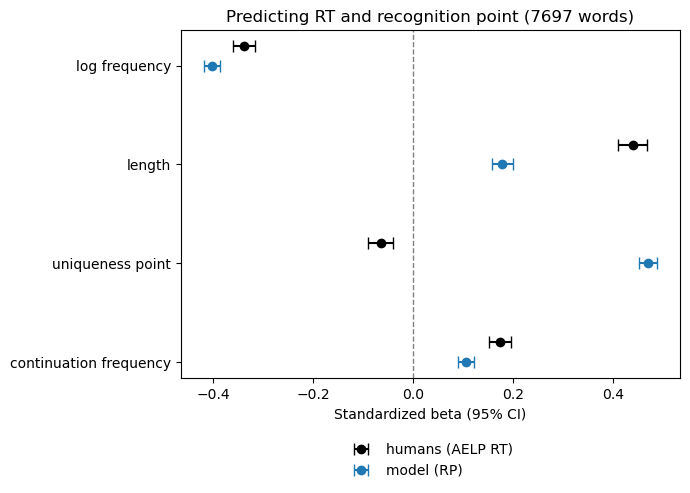

In [33]:
import statsmodels.formula.api as smf

# (aelp_df['continuations'] was computed above, with the scatterplots)


def standardized_regression(df, outcome, predictors, interactions=()):
    # Ordinary least squares on z-scores, so the coefficients are standardized betas.
    # interactions is a list like ['log_frequency:length'], where a:b means a times b.
    # Returns the fitted model; .params has the betas and .conf_int() their 95% CIs.
    z = df[[outcome] + predictors].copy()
    for column in z.columns:                       # z-score every variable
        z[column] = (z[column] - z[column].mean()) / z[column].std()
    terms = list(predictors) + list(interactions)
    formula = f"{outcome} ~ {' + '.join(terms)}"   # e.g. 'rt_onset ~ log_frequency + length + UP'
    return smf.ols(formula, data=z).fit()


def beta_table_with_ci(fits, terms):
    # One row per regression: R squared, then each beta with its 95% CI
    rows = {}
    for name, fit in fits.items():
        ci = fit.conf_int()
        rows[name] = {'R2': f'{fit.rsquared:.3f}'}
        for term in terms:
            rows[name][term] = f'{fit.params[term]:+.3f} [{ci.loc[term, 0]:+.3f}, {ci.loc[term, 1]:+.3f}]'
    return pd.DataFrame(rows).T


def plot_betas(fits, terms):
    # Estimates plot: the betas from each regression, with 95% CIs, one row per term
    labels = [term.replace('log_frequency', 'log frequency').replace('UP', 'uniqueness point')
              .replace('continuations', 'continuation frequency').replace(':', ' × ')
              for term in terms]
    fig, ax = plt.subplots(figsize=(7, 1.5 + 0.9 * len(terms)))
    for offset, name, color in zip([-0.2, 0, 0.2], fits, ['black', 'tab:blue', 'tab:orange']):
        fit = fits[name]
        ci = fit.conf_int().loc[terms]
        y = np.arange(len(terms)) + offset
        ax.errorbar(fit.params[terms], y, xerr=[fit.params[terms] - ci[0], ci[1] - fit.params[terms]],
                    fmt='o', color=color, capsize=4, label=name)
    ax.axvline(0, color='gray', linestyle='--', linewidth=1)
    ax.set_yticks(range(len(terms)))
    ax.set_yticklabels(labels)
    ax.invert_yaxis()
    ax.set_xlabel('Standardized beta (95% CI)')
    ax.set_title(f'Predicting RT and recognition point ({len(aelp_df)} words)')
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), frameon=False)
    plt.tight_layout()
    plt.show()


predictors = ['log_frequency', 'length', 'UP', 'continuations']
fits = {
    'humans (AELP RT)': standardized_regression(aelp_df, 'rt_onset', predictors),
    'model (RP)': standardized_regression(aelp_df, 'RP_model', predictors),
}
beta_table = beta_table_with_ci(fits, predictors)
display(beta_table)
plot_betas(fits, predictors)

Compare the rows of the table, or the two sets of points in the plot.

- **Frequency.** Frequent words are faster for listeners and for the model, and by a similar amount. The model gets the size of the frequency effect about right, which supports using raw frequency as the prior.
- **Uniqueness point.** This is the biggest difference between model and listeners: the uniqueness point is the model's strongest predictor (+.47), but slightly *negative* for listeners (−.07). Three things are going on.
    1. *For the model, the recognition point is tied to the uniqueness point by construction.* With clear input, every word that matches the input so far stays in the running, and the target cannot pull ahead of a competitor that matches it just as well -- unless it is more frequent. So the target wins either at its uniqueness point (49% of the words) or earlier, when it is more frequent than the competitors that are left (another 49%); it almost never wins later (3%).
    2. *Listeners are doing a different task.* In lexical decision, they only have to decide that they heard *a* word, not which one, and they usually respond after the word has ended, when it hardly matters where the word became unique. (See 'What task is the model doing?' below, and lab question 6.)
    3. *Suppression.* For listeners, the simple correlation between uniqueness point and RT is positive (+.27, in the scatterplots above), but nearly all of it comes from length: uniqueness point and length correlate .64, because longer words tend to become unique later. Once length is in the regression, what is left for the uniqueness point is slightly negative (a partial correlation of −.07). That small negative effect has a simple source. A third of the words are the beginnings of longer words, so their uniqueness point is length + 1 (*cat*, in *cattle*), and these words are much more frequent than other words of the same length: for three-phoneme words, an average log frequency of 3.4 vs. 2.0. So a late uniqueness point goes with high frequency, and high frequency goes with fast RTs. This is an example of **suppression**: when predictors are correlated, a predictor's beta can differ in size, and even in sign, from its simple correlation with the outcome, because the regression credits the shared variance to the other predictors.
- **Continuation frequency.** Here listeners and model agree: words with frequent continuations are slower for both (+.17 for listeners, +.11 for the model). For listeners it is the third-strongest predictor, after length and frequency, and adding it raises their R² from .30 to .32 (the model's goes from .61 to .62). Notice the contrast with the uniqueness point. Whether a word becomes unique early hardly matters to listeners, but how strong its competitors still are when it *ends* does. For the model, frequent continuations mean it is still unsure at the end of the word; listeners seem to be slowed by the same uncertainty. (Lab question 6.)
- **Length.** Longer words are slower for both, but more so for listeners. For them, length mostly stands in for duration -- longer words take longer to say -- and our model has no notion of time beyond counting phonemes.
- **R².** The model's recognition points are much more predictable from these four variables than human RTs are. Real RTs also reflect differences between talkers and listeners, the time it takes to make a decision and press a button, and much else.
- **Confidence intervals.** With about 7,700 words, the CIs are narrow, so nearly every difference between humans and model is far larger than the uncertainty. The CIs mean something slightly different for the two, though. The model has no noise -- run it again and you get the same recognition points -- so its CIs only reflect which words happen to be in the sample. The humans' CIs also reflect noise in the RTs themselves.

### Adding interactions

In notebook 06 we also tried *interactions*. An interaction asks whether the effect of one predictor depends on the value of another. For example, is the frequency effect bigger for long words than for short ones? In a regression, the interaction of two predictors is simply their product, written `log_frequency:length`. Our predictors are z-scores, so they are centered on 0, just as we centered the predictors in notebook 06 before multiplying them. That way, each main-effect beta still describes the effect of that predictor for a word that is average on the others.

We add the three two-way interactions among frequency, length, and uniqueness point to each regression.

,R2,log_frequency,length,UP,continuations,log_frequency:length,log_frequency:UP,length:UP
humans (AELP RT),0.353,"-0.350 [-0.371, -0.328]","+0.347 [+0.315, +0.379]","-0.073 [-0.100, -0.045]","+0.085 [+0.061, +0.109]","-0.161 [-0.187, -0.134]","+0.064 [+0.036, +0.091]","+0.103 [+0.085, +0.121]"
model (RP),0.650,"-0.395 [-0.411, -0.379]","+0.246 [+0.222, +0.269]","+0.391 [+0.371, +0.412]","+0.118 [+0.101, +0.136]","+0.134 [+0.114, +0.153]","-0.249 [-0.269, -0.228]","+0.007 [-0.007, +0.020]"


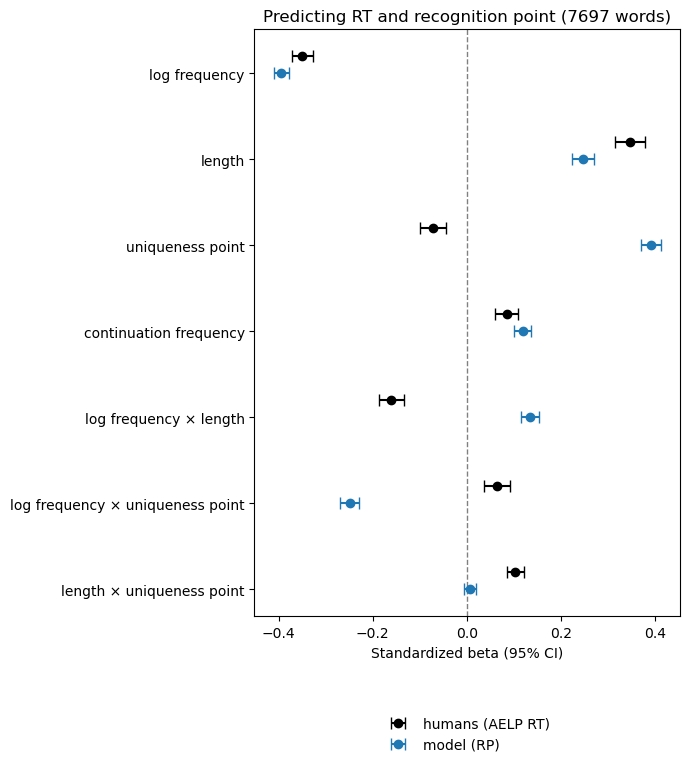

In [34]:
interactions = ['log_frequency:length', 'log_frequency:UP', 'length:UP']
interaction_fits = {
    'humans (AELP RT)': standardized_regression(aelp_df, 'rt_onset', predictors, interactions),
    'model (RP)': standardized_regression(aelp_df, 'RP_model', predictors, interactions),
}
interaction_table = beta_table_with_ci(interaction_fits, predictors + interactions)
display(interaction_table)
plot_betas(interaction_fits, predictors + interactions)


How to read an interaction beta: the effect of frequency for a given word is the frequency beta *plus* the interaction beta times the word's (z-scored) value on the other predictor. The frequency beta is negative (frequent words are faster), so a *negative* frequency × length beta means the frequency effect gets *stronger* as words get longer, and a positive one means it gets weaker.

- **R²** goes up a little for everyone: from .32 to .35 for listeners, and from .62 to .65 for the model. The main effects change a little but keep their signs. (Continuation frequency shrinks for listeners, from +.17 to +.08, but still clearly helps.)
- **Uniqueness point.** The main effect is still large for the model (+.39) and slightly negative for listeners (−.07), for the reasons given above.
- **Frequency × length and frequency × uniqueness point are hard to tell apart.** At first sight, both have *opposite* signs for listeners and model: frequency × length is −.16 for listeners and +.13 for the model, and frequency × uniqueness point is +.06 for listeners and −.25 for the model. But these two interaction terms are strongly correlated with each other (r = .67), because length and uniqueness point are. When both are in the regression, it has to divide their shared variance between them, and small differences decide which one gets the credit -- another case of suppression. The next cell enters each interaction *on its own* (with the four main effects). Then listeners and model agree in sign on both: frequency × length is −.15 for listeners and −.05 for the model, and frequency × uniqueness point is −.10 for listeners and −.16 for the model.
- **So what really differs is what the frequency effect depends on.** For the *model*, it depends on the uniqueness point. Frequency can only help a word win *before* its uniqueness point, by beating competitors that still match it, so the later the uniqueness point, the more room frequency has (−.25). Once that is accounted for, longer words show slightly *less* frequency effect (+.13). For *listeners*, the frequency effect grows with length (−.16): in raw terms, each unit of log frequency saves about 10 ms for words of 1-3 phonemes, but about 28 ms for words of 8 or more. Part of that could be a matter of scale -- if frequency speeds processing by a constant *proportion*, it saves more milliseconds on long words -- but the interaction is nearly as strong when we analyze log RT (−.13, not shown), so that is not the whole story. Perhaps frequency simply has more time to act during a long word. Once frequency × length is accounted for, what is left for frequency × uniqueness point is slightly positive (+.06).
- **Length × uniqueness point.** This is +.10 for listeners and essentially 0 for the model. For the model, the recognition point follows the uniqueness point however long the word is, so there is no interaction. For listeners, the positive sign means that a late uniqueness point costs more in a long word. One possibility: in a long word that becomes unique early, the listener can anticipate the rest of the word and be ready to respond when it ends; in a short word, the uniqueness point is almost always at or after the last phoneme anyway.

So the interactions look like more disagreement than they are: some of it comes from correlated interaction terms splitting their shared variance. The clearest real difference is what the frequency effect depends on: the uniqueness point for the model, length (and so duration) for listeners. (A three-way interaction, frequency × length × uniqueness point, adds almost nothing for either: R² goes up by about .001. Try it if you like, by adding `'log_frequency:length:UP'` to the list.)

In [ ]:
# Each interaction on its own (with the four main effects), compared with all three together.
# When correlated terms are entered together, the regression divides their shared variance between them.
rows = []
for name, outcome in [('humans (AELP RT)', 'rt_onset'), ('model (RP)', 'RP_model')]:
    together = standardized_regression(aelp_df, outcome, predictors, interactions)
    for term in interactions:
        alone = standardized_regression(aelp_df, outcome, predictors, [term])
        rows.append({'outcome': name, 'interaction': term,
                     'beta, entered alone': round(alone.params[term], 3),
                     'beta, all three together': round(together.params[term], 3)})
display(pd.DataFrame(rows))

# How correlated are the interaction terms? (z-score, then multiply, as in the regressions)
z_scores = aelp_df[predictors].copy()
for column in z_scores.columns:
    z_scores[column] = (z_scores[column] - z_scores[column].mean()) / z_scores[column].std()
products = pd.DataFrame({term: z_scores[term.split(':')[0]] * z_scores[term.split(':')[1]] for term in interactions})
products.corr().round(2)

### What task is the model doing?

Before we read too much into the differences, notice that the model and the listeners are not doing the same task. AELP measures *auditory lexical decision*: listeners hear a word or a nonword and decide whether it is a word. Our model does *identification*: its recognition point is when *this particular word* wins. A listener can say 'word' without knowing which word it is -- and in particular without waiting for the uniqueness point. That alone could explain why the uniqueness point matters so much for the model and so little for listeners.

What would it take for the model to do lexical decision? At least two things:

1. **A way to say 'nonword'.** At present every input must be one of the words in the lexicon. We would add a *catch-all* (unknown-word) hypothesis: one extra hypothesis, competing with all the words, that can explain any input moderately well -- for example, a random string of phonemes drawn with their usual frequencies. Its prior would reflect how many nonwords the listener expects (about half, in AELP). When the input fits a word well, the catch-all loses; when nothing fits, it wins. (Norris and McQueen's Shortlist B has a hypothesis like this for lexical decision.)
2. **A decision rule that waits for the end of the word.** 'Has a word been heard?' cannot be answered in mid-word: *cand-* could be the start of *candle*, or a nonword. So the model would respond 'word' once the probability that a *complete* word has been heard -- a word that ends here, rather than a longer word or the catch-all -- passes a threshold, which usually happens as the silence after the word arrives.

In a pilot version of exactly this (not included here), the uniqueness-point effect disappears from the model's lexical-decision times, as it does for listeners, while frequency and continuation frequency still matter. (Challenge question 12 asks you to implement it.)

### The time course of competition: Allopenna, Magnuson, and Tanenhaus (1998)

Reaction times give us one number per word. The *visual world paradigm* gives us a time course. In Experiment 1 of Allopenna, Magnuson, and Tanenhaus (1998), listeners saw four pictures and heard an instruction such as 'Pick up the *candle*', while an eye tracker recorded where they looked. The four pictures were the **target** (*candle*), a **cohort** competitor that begins the same way (*candy*), a **rhyme** competitor that ends the same way (*handle*), and an **unrelated** object (*dollar*). As the word unfolded, looks to the target and the cohort rose together; when the input diverged from the cohort, looks to the cohort fell and looks to the target kept rising. Looks to the rhyme rose a little later and stayed much lower than looks to the cohort, but reliably above looks to the unrelated object. The TRACE model, which we meet next, fit these curves closely -- including the rhyme effect.

To link a model to eye movements, Allopenna and colleagues assumed that looks are directed to the pictures in proportion to how strongly the model supports each picture's name, *among the four pictures on the screen*. The Bayesian version of this linking hypothesis is simple: the listener knows that one of the four pictures will be named, and each one is equally likely to be the target in the experiment, so each gets a prior of 1/4 (the lexicon and word frequency drop out), and the probability of each picture is its likelihood -- $P(\text{input so far} \mid \text{word})$ -- divided by the sum of the four likelihoods. We compute these probabilities after each phoneme of the target and after the silence that follows it, and average over item sets.

We use 7 of the 8 item sets from Experiment 1. The eighth (*beaker*, *beetle*, *speaker*, *dolphin*) does not work in our model: the model compares words position by position from the onset, and *speaker* (/s p i k ɚ/) has one more phoneme than *beaker* (/b i k ɚ/) before the shared ending, so its ending never lines up with the input. (The lexicon has no picturable rhyme of *beaker* of the same length -- only *weaker* and *seeker*.) That is itself a limitation of our model: listeners, and TRACE, align words in *time*, not by counting phonemes from the onset.

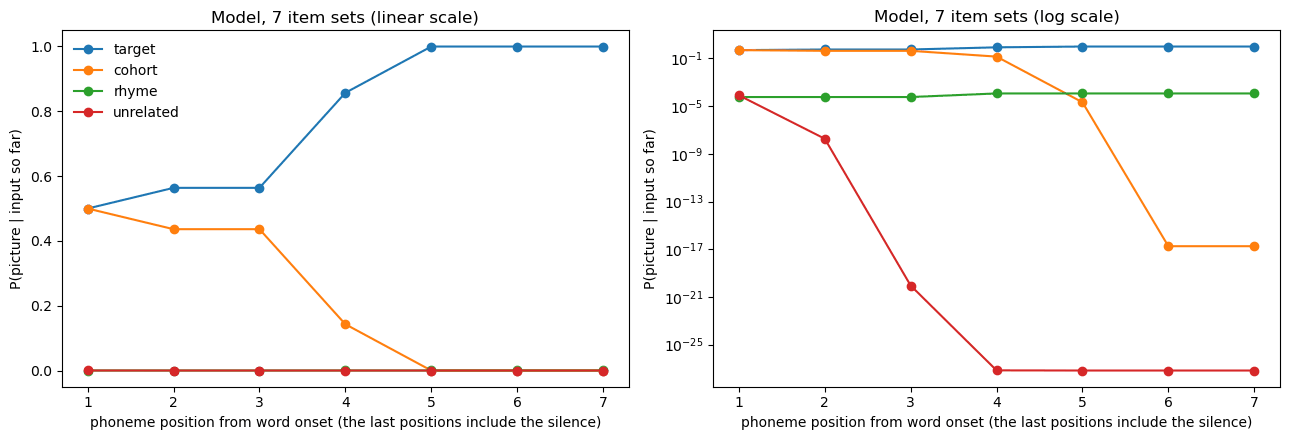

,target,cohort,rhyme,unrelated
carrot,0.9992,0.4998,0.0008,0.0000
candle,1.0000,0.5000,0.0000,0.0000
pickle,1.0000,0.5000,0.0000,0.0000
casket,1.0000,0.5000,0.0000,0.0000
paddle,1.0000,0.5000,0.0000,0.0000
dollar,1.0000,0.4997,0.0000,0.0006
sandal,1.0000,0.5000,0.0000,0.0000


In [36]:
# Item sets from Experiment 1 of Allopenna, Magnuson, & Tanenhaus (1998): target, cohort, rhyme, unrelated.
# (The beaker/beetle/speaker/dolphin set is left out; see the text above.)
allopenna_sets = [('carrot', 'carriage', 'parrot', 'nickel'),
                  ('candle', 'candy', 'handle', 'dollar'),
                  ('pickle', 'picture', 'nickel', 'speaker'),
                  ('casket', 'castle', 'basket', 'nickel'),
                  ('paddle', 'padlock', 'saddle', 'dollar'),
                  ('dollar', 'dolphin', 'collar', 'beaker'),
                  ('sandal', 'sandwich', 'candle', 'parrot')]
roles = ['target', 'cohort', 'rhyme', 'unrelated']

# Each word's pronunciation, and the log of the bottom-up evidence table from Part 5
# (row: the input symbol; column: a candidate symbol). To try a noisier input, rebuild
# phoneme_confusion_df with a lower target accuracy before running this cell.
pronunciation_of = dict(zip(lexicon_df['Item'].str.lower(), lexicon_df['Pronunciation']))
symbols = list(phoneme_confusion_df.columns)
log_evidence = np.log(phoneme_confusion_df.values)


def display_probabilities(item_set):
    # P(each of the four pictures | input so far), after each phoneme of the target and the silence after it.
    # Each picture's prior is 1/4, so each probability is its likelihood divided by the sum of the four.
    input_symbols = pronunciation_of[item_set[0]].split() + [SILENCE]
    log_likelihood = np.zeros(len(item_set))
    rows = []
    for t, input_symbol in enumerate(input_symbols):
        for j, word in enumerate(item_set):
            word_symbols = pronunciation_of[word].split()
            # the word's own symbol at position t (silence once the word has ended)
            symbol = word_symbols[t] if t < len(word_symbols) else SILENCE
            log_likelihood[j] += log_evidence[symbols.index(input_symbol), symbols.index(symbol)]
        p = np.exp(log_likelihood - log_likelihood.max())
        rows.append(p / p.sum())
    return np.array(rows)          # one row per position, one column per role


# Targets differ in length, so after each target's silence we carry its final values forward
results = [display_probabilities(s) for s in allopenna_sets]
n_positions = max(len(r) for r in results)
padded = np.array([np.vstack([r] + [r[-1:]] * (n_positions - len(r))) for r in results])
mean_probabilities = padded.mean(axis=0)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, scale in zip(axes, ['linear', 'log']):
    for j, role in enumerate(roles):
        ax.plot(range(1, n_positions + 1), mean_probabilities[:, j], marker='o', label=role)
    ax.set_xlabel('phoneme position from word onset (the last positions include the silence)')
    ax.set_ylabel('P(picture | input so far)')
    ax.set_yscale(scale)
    ax.set_title(f'Model, 7 item sets ({scale} scale)')
axes[0].legend(frameon=False)
plt.tight_layout()
plt.show()

# The highest probability each competitor ever reaches, item set by item set
peaks = pd.DataFrame([r.max(axis=0) for r in results], columns=roles, index=[s[0] for s in allopenna_sets])
peaks.round(4)

**Target and cohort.** These behave much like listeners' looks. The two share the probability equally until the first phoneme where they differ, and then the target takes over. Averaged over the item sets, the cohort's share falls from .50 to .44 at the second position (in one set, *dollar* and *dolphin* already differ at the vowel), to .14 at the fourth, and to 0 by the fifth. In the model, the target and cohort are *exactly* tied until the input diverges. Listeners' curves are smoother, partly because an eye movement takes about 200 ms to plan and launch, and partly because real speech carries early cues to upcoming sounds (coarticulation) that our phoneme-by-phoneme input does not.

**Rhyme.** On the linear scale, the rhyme cannot be told apart from 0: the highest probability it reaches in any set is .0008 (*parrot*, when the target is *carrot*). Listeners look at rhymes far more than that. The log-scale panel shows what is happening. At the first phoneme, the rhyme and the unrelated item both fall far below the target and the cohort, because both mismatch the target's first phoneme. (On average they fall about equally far, but in a single set either one can be far lower than the other, depending on how similar its first phoneme is to the target's.) After that, the rhyme *stays* where it is -- about 1 in 10,000 on average, mostly because of one set, *carrot*/*parrot*; in the other sets it stays below 1 in a million -- while the unrelated item keeps falling, to about $10^{-27}$ on average, because every later phoneme counts against it, too. So the model does distinguish rhymes from unrelated items, but only after a single clear mismatch at the onset has cut the rhyme's probability to almost nothing. Later matching phonemes cannot raise it again, because they help the target just as much: the likelihood *multiplies* the evidence from each position (the conditional independence assumption once more), so one clear mismatch is nearly fatal, however well everything else matches. In the model, the rhyme does not rise late in the word, as it does for listeners; it never rises at all.

In TRACE, by contrast, the rhyme's word unit keeps receiving excitation from all the phonemes it *does* match, so it gains activation late in the word, and converting activations to choice probabilities among the four pictures turns that into a small but clear rhyme effect. Can our model be made more tolerant of an onset mismatch? Noisier input helps a little: at 75% phoneme accuracy, the rhyme reaches at most about .03. Allowing for mispronunciations ($\varepsilon$, which we meet in Part 8) helps even less (at most about .004, with $\varepsilon = 0.1$), because it helps the target just as much. (Neither result is shown here; challenge question 14 asks you to explore them.) So the rhyme effect is a real challenge for this model: what would have to change for a word that mismatches at its onset to stay in the running? (Challenge question 14 asks you to try.)

-------

# Part 7

## Autonomy and reversibility

So far, information in our model flows one way: from the input, to the phoneme level, to the word level. Nothing ever flows back down. This is a deliberate choice, and it is one side of a long debate in spoken word recognition.

### The autonomous view

Norris and McQueen (2008), and Norris, McQueen, and Cutler (2000) before them, argue that word recognition should be **autonomous**: lexical knowledge should never feed back to change prelexical (phoneme-level) processing. Their main argument is that feedback cannot help. If the phoneme level passes its evidence up intact, the best any recognizer can do is to combine that evidence with the prior probability of each word, which is exactly what Bayes' theorem does. In their words, 'Far from improving recognition, any feedback at all will therefore make word recognition suboptimal.'

But listeners *do* show lexical effects on phoneme judgments. In the Ganong (1980) effect, for example, a sound halfway between /g/ and /k/ is heard as /g/ before *-ift* (because *gift* is a word and *kift* is not) and as /k/ before *-iss* (*kiss*, not *giss*). An autonomous model has to put these effects somewhere. Norris and colleagues' solution is **Merge**: a separate set of *phoneme decision units* that combine prelexical evidence with lexical knowledge. 'Responses in tasks requiring phoneme identification are determined by these decision units and not by the prelexical phoneme units themselves.' So Merge is an add-on -- an appendage built to produce top-down effects in phoneme decisions while keeping the processing that feeds word recognition free of them. Norris and McQueen argue that 'the Bayesian approach necessarily forces us to adopt the same architecture in Shortlist B as in Merge.'

### Does autonomy follow from Bayesian principles?

No. Nothing in Bayes' theorem says that information may flow only upward. In fact, Bayesian models of perception are typically **reversible**, as Chater and Manning (2006, Box 2) point out: perception works by inverting a *generative model* -- a model of how causes (words, objects) produce inputs -- and the same model can be run in both directions. Our model already does half of this. The likelihood, $P(input \mid word)$, *is* the generative model: it says how each word, phoneme by phoneme, produces noisy feature vectors. Recognition runs it backward with Bayes' theorem.

The real question is narrower: should knowledge about words flow back down and change the phoneme level *during* recognition? The diagram below shows three architectures: (a) our feedforward model; (b) a naive feedback loop, in which the phoneme level combines the word level's prediction with the evidence and sends *that* back up; and (c) the right way to do it, which we will build in Part 8. In (c), the word level still sends a *prediction* down: how likely each phoneme is, according to the current word probabilities -- computed without that phoneme's own evidence. The phoneme level combines that prediction with the evidence to form its own percept (its *belief*), but it never sends the prediction back up; it sends up only the evidence.

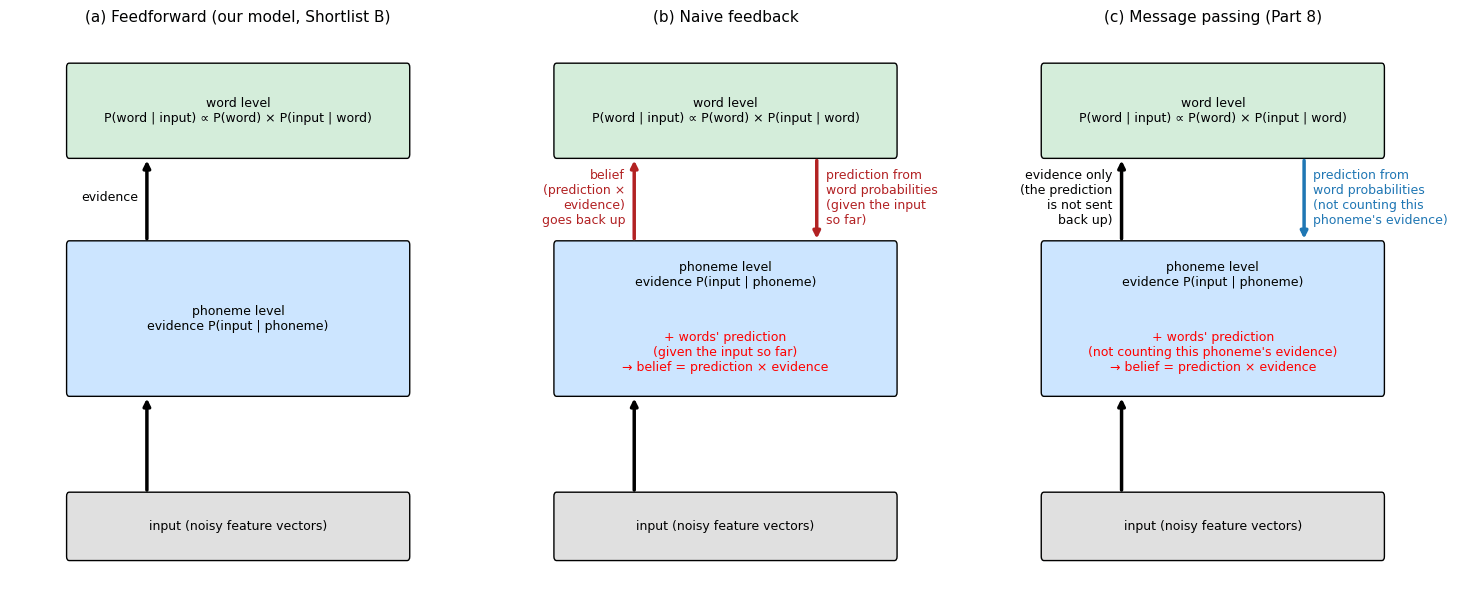

In [37]:
from matplotlib.patches import FancyBboxPatch

# Three architectures
def draw_box(ax, x, y, width, text, color, height=1.3):
    ax.add_patch(FancyBboxPatch((x - width / 2, y - height / 2), width, height, boxstyle='round,pad=0.06',
                                facecolor=color, edgecolor='black'))
    ax.text(x, y, text, ha='center', va='center', fontsize=9)

def draw_arrow(ax, start, end, color='black'):
    ax.annotate('', xy=end, xytext=start, arrowprops=dict(arrowstyle='-|>', color=color, lw=2.5))

fig, axes = plt.subplots(1, 3, figsize=(15, 6))
# Every phoneme level starts from the same bottom-up evidence (black). In (b) and (c), the red text says
# what else the phoneme level takes into account, and what it computes from it.
added = {'b': "+ words' prediction\n(given the input so far)\n→ belief = prediction × evidence",
         'c': "+ words' prediction\n(not counting this phoneme's evidence)\n→ belief = prediction × evidence"}
titles = {'a': '(a) Feedforward (our model, Shortlist B)', 'b': '(b) Naive feedback', 'c': '(c) Message passing (Part 8)'}
for ax, panel in zip(axes, 'abc'):
    ax.set_xlim(0, 10); ax.set_ylim(0, 8.2); ax.axis('off'); ax.set_title(titles[panel], fontsize=11)
    draw_box(ax, 5, 0.8, 7.4, 'input (noisy feature vectors)', '#e0e0e0', 0.9)
    draw_box(ax, 5, 7.0, 7.4, 'word level\nP(word | input) ∝ P(word) × P(input | word)', '#d4edda')
    # the phoneme level: a taller box, with the bottom-up evidence in black (and additions in red)
    draw_box(ax, 5, 3.9, 7.4, '', '#cce5ff', height=2.2)
    if panel == 'a':
        ax.text(5, 3.9, 'phoneme level\nevidence P(input | phoneme)', ha='center', va='center', fontsize=9)
    else:
        ax.text(5, 4.55, 'phoneme level\nevidence P(input | phoneme)', ha='center', va='center', fontsize=9)
        ax.text(5, 3.4, added[panel], ha='center', va='center', fontsize=9, color='red')
    draw_arrow(ax, (3.0, 1.3), (3.0, 2.75))
    if panel == 'a':
        draw_arrow(ax, (3.0, 5.05), (3.0, 6.3))
        ax.text(2.8, 5.7, 'evidence', ha='right', va='center', fontsize=9)
    if panel == 'b':
        draw_arrow(ax, (7.0, 6.3), (7.0, 5.05), 'firebrick')
        ax.text(7.2, 5.7, "prediction from\nword probabilities\n(given the input\nso far)", color='firebrick', va='center', fontsize=9)
        draw_arrow(ax, (3.0, 5.05), (3.0, 6.3), 'firebrick')
        ax.text(2.8, 5.7, 'belief\n(prediction ×\nevidence)\ngoes back up', color='firebrick', ha='right', va='center', fontsize=9)
    if panel == 'c':
        draw_arrow(ax, (7.0, 6.3), (7.0, 5.05), 'tab:blue')
        ax.text(7.2, 5.7, "prediction from\nword probabilities\n(not counting this\nphoneme's evidence)", color='tab:blue', va='center', fontsize=9)
        draw_arrow(ax, (3.0, 5.05), (3.0, 6.3))
        ax.text(2.8, 5.7, 'evidence only\n(the prediction\nis not sent\nback up)', ha='right', va='center', fontsize=9)
plt.tight_layout()
plt.show()

**Reading the diagram.** In (b) and (c), the word level sends down a *prediction* for each phoneme, and it comes from the words' current, estimated probabilities: the predicted probability of /g/ at some position, say, is the summed probability of all the words that have /g/ in that position. The two architectures differ in *which* word probabilities they use, and in what goes back up. Take the input *?ift*, where the first sound is ambiguous between /g/ and /k/.

- **(a) Feedforward.** Each sound's evidence goes up to the words, and that is all. The words end up favoring *gift*, but the phoneme level still 'hears' an ambiguous first sound.
- **(b) Naive feedback.** As each sound arrives, the words predict it from their probabilities given the input *so far*; the phoneme level multiplies that prediction into the evidence and sends the product up. The words then receive their own prediction back, as if it were new evidence: the lexicon is counted twice.
- **(c) Message passing.** The words still send a prediction down to each sound, but it comes from word probabilities that do *not* count that sound's own evidence -- only the evidence from every other sound, before and after. For the first sound of *?ift*, that is the evidence from /ɪ f t/ and the silence. The words that are probable given that evidence (*gift*, *lift*, *shift*, ...) predict /g/ rather than /k/, because *kift* is not a word. The phoneme level combines this prediction with its own ambiguous evidence, so its *belief* -- what it 'perceives' -- favors /g/. But what it sends up to the words is only its own evidence.

Why leave a sound's own evidence out of the word probabilities behind its prediction? Because the belief multiplies the prediction by that sound's evidence; if the prediction already contained that evidence, the evidence would be counted twice -- the same mistake as (b), in the other direction. And why send only the evidence up? Because the words already have all the other input directly; sending the prediction back would give them nothing new except a second copy of what they already know.

**What about words that do not have /g/ in that position?** They matter in two ways. First, they take probability away from the words that do: word probabilities always sum to 1 across the whole lexicon, so if *lift* and *shift* are probable given /ɪ f t/, there is less probability left for *gift*, and the prediction for /g/ is weaker. Second, they predict *other* phonemes in that slot: each word puts its probability on its own phoneme there (*lift* on /l/, *shift* on /ʃ/), and the prediction is a distribution over all the phonemes that sums to 1. So a word without /g/ there still matters, by raising a competitor of /g/. In the Ganong simulations of Part 8, though, we report only the probability of /k/ out of /g/ and /k/, so whatever goes to /l/ or /ʃ/ drops out of that comparison. What remains is how strongly the words that have /g/ there (*gift*) outweigh those that have /k/ there (none: *kift* is not a word). The one exception is $\varepsilon$, explained in Part 8: every word also spreads a little of its probability over all the phonemes, to allow for mispronunciations, so every word nudges /g/ and /k/ a little. That is what keeps a clear /k/ from being overridden.

### Can feedback help word recognition in this Bayesian model?

Let's test Norris and McQueen's claim directly, under conditions that should favor feedback: noisy input. In the naive feedback loop (b), at each position the word level predicts the next phoneme -- the probability of phoneme $k$ is the summed probability of all the words whose next phoneme is $k$ -- and the phoneme level multiplies that prediction into the evidence before sending it up. The interactive intuition is that the words should 'fill in' what the noise obscured.

The code below presents 1,000 words, drawn at random *in proportion to their frequency* (as a listener would hear them), at three noise levels. At each position, the input is the phoneme's feature vector plus Gaussian noise with standard deviation `noise_sigma` on every feature. Note one important assumption: the listener knows *exactly* how noisy the input is, because it computes its evidence using the true `noise_sigma`. We come back to whether that is realistic after the results. (The printout shows how often a single phoneme would be identified correctly at each noise level.) We compare three recognizers on exactly the same noisy inputs:

- **feedforward**: our model;
- **feedback**: the naive loop (b);
- **feedforward, prior squared**: our model with a doubled frequency bias. This is a control: feedback boosts words that are already ahead, which are usually the frequent ones. Is that all it does?

It takes a few seconds.

In [ ]:
# Code every pronunciation as a row of symbol numbers, padded with silence (as recognize_lexicon does)
symbols = list(phoneme_confusion_df.columns)             # the 38 phonemes + SIL
symbol_vectors = feature_vectors_df.loc[symbols].values  # one feature vector (44 values) per symbol
by_pronunciation = lexicon_df.groupby('Pronunciation')['Frequency'].sum()
pronunciations = by_pronunciation.index.to_numpy()
log_prior = np.log(by_pronunciation.values)
lengths = np.array([len(p.split()) for p in pronunciations])
codes = np.full((len(pronunciations), lengths.max() + 1), symbols.index(SILENCE))   # +1: the silence after the longest word
for i, pronunciation in enumerate(pronunciations):
    codes[i, :lengths[i]] = [symbols.index(x) for x in pronunciation.split()]


def softmax_rows(scores):
    # Turn each row of log scores into probabilities that sum to 1. Subtracting each row's
    # maximum before exp() keeps the numbers in a range the computer can represent; it
    # cancels out when we normalize.
    p = np.exp(scores - scores.max(axis=1, keepdims=True))
    return p / p.sum(axis=1, keepdims=True)


def noisy_evidence(true_symbols, noise_sigma, rng):
    # The listener receives each feature value plus Gaussian noise. The evidence for each candidate
    # symbol k is P(input | k) under that same noise (normalized over k): one row per input.
    n_features = symbol_vectors.shape[1]
    x = symbol_vectors[true_symbols] + noise_sigma * rng.standard_normal((len(true_symbols), n_features))
    # squared distance from each noisy input (rows) to each symbol's feature vector (columns)
    sq_distances = np.zeros((len(x), len(symbols)))
    for k in range(len(symbols)):
        sq_distances[:, k] = ((x - symbol_vectors[k]) ** 2).sum(axis=1)
    return softmax_rows(-sq_distances / (2 * noise_sigma ** 2))


def recognize_noisy(targets, noise_sigma, recognizer, seed=1):
    # Fraction of targets that are the most probable word at the end of the input (word + silence)
    rng = np.random.default_rng(seed)        # same seed -> same noise for every recognizer
    correct = 0
    for length in np.unique(lengths[targets]):
        group = targets[lengths[targets] == length]
        for start in range(0, len(group), 250):
            chunk = group[start:start + 250]
            prior_weight = 2 if recognizer == 'feedforward, prior squared' else 1
            score = np.tile(prior_weight * log_prior, (len(chunk), 1))
            for t in range(length + 1):
                evidence = noisy_evidence(codes[chunk, t], noise_sigma, rng)
                if recognizer == 'feedback':
                    # The words predict the phoneme at position t: the predicted probability of
                    # symbol k is the summed probability of all the words whose symbol at t is k ...
                    word_probabilities = softmax_rows(score)
                    prediction = np.zeros_like(evidence)
                    for k in range(len(symbols)):
                        prediction[:, k] = word_probabilities[:, codes[:, t] == k].sum(axis=1)
                    # ... and the phoneme level sends up prediction x evidence instead of the evidence
                    evidence = prediction * evidence
                    evidence /= evidence.sum(axis=1, keepdims=True)
                score += np.log(evidence[:, codes[:, t]] + 1e-300)
            correct += (score.argmax(axis=1) == chunk).sum()
    return correct / len(targets)


def single_phoneme_accuracy(noise_sigma, n_per_phoneme=200, seed=3):
    # How often a single noisy phoneme is closer to its own feature vector than to any other
    # phoneme's (no lexicon, no priors)
    rng = np.random.default_rng(seed)
    n_phonemes = len(symbols) - 1                      # leave out silence (the last symbol)
    n_features = symbol_vectors.shape[1]
    correct = 0
    for k in range(n_phonemes):
        noisy = symbol_vectors[k] + noise_sigma * rng.standard_normal((n_per_phoneme, n_features))
        sq_distances = np.zeros((n_per_phoneme, n_phonemes))
        for j in range(n_phonemes):
            sq_distances[:, j] = ((noisy - symbol_vectors[j]) ** 2).sum(axis=1)
        correct += (sq_distances.argmin(axis=1) == k).sum()   # nearest phoneme is the right one
    return correct / (n_phonemes * n_per_phoneme)


# 1,000 words, sampled in proportion to frequency (repeats allowed)
sample_rng = np.random.default_rng(7)
frequencies = by_pronunciation.values
test_words = np.sort(sample_rng.choice(len(pronunciations), 1000, replace=True, p=frequencies / frequencies.sum()))

start_time = time.time()
noise_rows = []
for noise_sigma in [0.2, 0.3, 0.4]:
    row = {'noise sigma': noise_sigma, 'single-phoneme accuracy': round(single_phoneme_accuracy(noise_sigma), 2)}
    for recognizer in ['feedforward', 'feedback', 'feedforward, prior squared']:
        row[recognizer] = round(100 * recognize_noisy(test_words, noise_sigma, recognizer), 1)
    noise_rows.append(row)
    print(f'noise sigma {noise_sigma}: done ({time.time() - start_time:.0f} s)')
noise_table = pd.DataFrame(noise_rows)
display(noise_table)

fig, ax = plt.subplots(figsize=(6, 4))
for recognizer, color, style in [('feedforward', 'black', '-'), ('feedback', 'firebrick', '-'),
                                 ('feedforward, prior squared', 'gray', '--')]:
    ax.plot(noise_table['noise sigma'], noise_table[recognizer], marker='o', color=color, linestyle=style, label=recognizer)
ax.set_xlabel('noise sigma (standard deviation of the noise on each feature)')
ax.set_ylabel('% words recognized')
ax.legend(frameon=False)
plt.show()

Norris and McQueen are right. At every noise level, the feedforward model recognizes the most words (99.1%, 94.9%, and 87.3%). Feedback does *worse* (98.9%, 93.0%, and 84.6%), and the gap grows as the noise grows (from 2 words in 1,000 to 27) -- the opposite of the interactive intuition. Feedback costs about as much as simply doubling the frequency prior (98.8%, 94.0%, and 85.0%): its main effect is an extra bias toward the words that are already ahead, which are usually the frequent ones.

Why can't feedback help? Because here the feedforward model is an *optimal* recognizer. The noise really is what the model assumes, and words are heard in proportion to their frequencies, as the prior assumes. Under those conditions, no recognizer can be right more often than one that always picks the word with the highest posterior probability -- and that is what the feedforward model does. Anything else, feedback included, can only do worse.

> **A big assumption: the listener knows exactly how noisy the input is.** In this simulation, the listener computes its evidence using the true noise level (`noise_sigma`), so it knows exactly how much to trust each sound. That is a large part of what makes the feedforward model optimal here, and it is probably not realistic. Real noise changes from moment to moment (a passing truck, a cough in the audience, a talker turning away) and differs across talkers and rooms, and nothing in the signal announces its own noise level: the listener has to estimate it from the speech itself. Listeners do adapt to noise and to talkers over seconds to minutes, so their estimates may be reasonable on average, but they cannot be exact. So this simulation is the *best case* for the feedforward model. A listener who misjudges the noise -- say, one who trusts the evidence as if the speech were clear when it is not -- is no longer an optimal recognizer, and then extra weight on the lexicon can help. (In a pilot version of this simulation, not included here, a listener tuned to clear speech gained a little from feedback in heavy noise -- but no more than it gained from simply adjusting its noise estimate, or from strengthening its frequency prior.)

### When could feedback make a difference?

Norris and McQueen's argument holds whenever three things are true: the recognizer's model of the input is correct, it computes the posterior exactly, and it has all the time it needs. Then nothing can beat it. Each assumption can fail in real listeners, and in models:

- **A mistuned listener** (see the box above). A listener who assumes the speech is clearer than it is trusts the evidence too much, and extra weight on the lexicon (from feedback, or simply a stronger prior) can partly make up for it.
- **Lossy or resource-limited representations.** If the phoneme level keeps only part of the evidence (a best guess, or a few samples, rather than a full probability distribution), top-down information can help recover what was thrown away.
- **Time.** In a system whose units take time to settle (like TRACE, which we meet next), feedback might change how *fast* a decision is reached, not only which one.
- **Problems too big to solve by listing every possibility.** Our model gets the exact posterior by brute force: it scores every one of the 17,000-odd words in the lexicon. That works because we present isolated words, and the model knows where each word starts and ends. In continuous speech, the hypotheses are not single words but whole *sequences* of words, and the boundaries between them are unknown (*ice cream* or *I scream*?). The number of possibilities explodes: a stretch of just 20 phonemes can be cut into words in more than 500,000 ways ($2^{19}$, since each of the 19 gaps between phonemes may or may not be a word boundary), and each piece could be any of thousands of words. That is far too many to list and score one by one, so any real system -- a brain or a model -- needs a shortcut. Models have taken two kinds:
    - *Local message passing.* Each unit (a word or a phoneme at a particular position) repeatedly updates itself using messages from its neighbors -- above, below, and to the sides -- until the whole system settles on a good interpretation. TRACE, which we meet next, works this way, but only *approximately* Bayesian: as its developers have acknowledged (McClelland, Mirman, Bolger, & Khaitan, 2014), its original activation and response rules distort the Bayesian computation somewhat. A variant of the same interactive framework, the **multinomial interactive activation (MIA)** model (Khaitan & McClelland, 2010; McClelland, 2013), fixes this and is *Bayes-equivalent*, not just Bayes-approximate. Its connection weights are the logarithms of the probabilities in the generative model (word frequencies, the probability of each letter given each word, and of each feature given each letter); only one unit in each pool can be active at a time; and units switch on and off at random, each one sampling its state given the current states of its neighbors above and below. Run long enough, the network visits each interpretation (a word, plus a letter in every position) in proportion to its exact posterior probability, with feedback included. (MIA was demonstrated for letters and words in reading; the same principles apply to speech.) In fact, the key idea goes back to McClelland (1991), who showed in TRACE itself that adding randomness ('stochasticity') to the units' activations makes the model combine context and bottom-up evidence in the way that classical models of perception (and Bayes' theorem) prescribe -- overturning the claim that interactive processing is inherently incompatible with optimal context effects. The price is time: the network has to settle. In methods like these, messages going *down* are part of how the answer is computed.
    - *Pruning.* Shortlist B (Norris & McQueen, 2008) lays out the candidate words in a *lattice*, a map of which words could begin and end where, and treats each sequence of words through it as a *path*. A path's probability comes from its words' likelihoods and priors, and a word's probability is the sum of the probabilities of all the paths it lies on. To keep this manageable, Shortlist B keeps only the best candidates -- at most 50 words starting at each phoneme position, and at most 500 paths -- and drops the rest, on the argument that very unlikely words and paths contribute almost nothing to the result. It recomputes the path probabilities as each new phoneme arrives, so later input can revise earlier interpretations (*ice*... *cream*). And it stays purely bottom-up: its shortcut is pruning, not feedback.

    So the size of the problem does not by itself force feedback. It forces *some* approximation, and models differ in which one they choose.

### So why do Bayesian perceptual models in other domains use reversibility?

Even when none of these four cases applies, many Bayesian perceptual models in other domains (especially vision) use reversibility to get **better intermediate representations**. In a model of object recognition, for example, an intermediate stage represents *edges*. Bottom-up, an edge in a noisy or partly hidden image is uncertain; knowing that the object is a face makes some edges much more likely than others. Top-down information sharpens the intermediate representation, and models of vision use it to explain effects such as illusory contours. Intermediate representations are also what neural recordings measure, so getting them right matters for linking models to the brain.

In our model, **phonemes are the intermediate representations**. Top-down effects in speech perception -- the Ganong effect, phoneme restoration, lexically mediated compensation for coarticulation -- are effects on that level. A feedforward model cannot produce them. That is why Norris and colleagues proposed **Merge** (Norris, McQueen, & Cutler, 2000): a feedforward model plus a separate set of *phoneme decision units*. The decision units receive input both from the prelexical phoneme units and from the words, so the phoneme judgments listeners report can show lexical effects. But nothing flows back from the decision units or the words to the prelexical units, so the processing that feeds word recognition stays purely bottom-up. In Part 8 we add reversibility to our model in a way that leaves word recognition exactly as it is.

-------

# Part 8

## Adding reversibility the right way

The naive loop failed because of *double counting*. The word level's prediction for the next phoneme is already based on the lexicon and the earlier input. When the phoneme level multiplies that prediction into the evidence and sends the product back up, the word level counts the lexical information again -- and again at every position. Frequent words that are already ahead get further ahead, whatever the input says.

The fix comes from the standard algorithm for passing information around a probabilistic model, *belief propagation* (Pearl, 1988). It distinguishes two things at each node:

- the node's **belief**: its best estimate, combining *everything* it knows. For a phoneme, that is the bottom-up evidence times the message from the words: $P(\text{phoneme} \mid \text{all the input, and the lexicon})$.
- the **message** it sends to a neighbor: everything it knows *except* what came from that neighbor. As McClelland (2013) puts it, what gets passed down 'carefully excludes the information that came up through it' -- and what gets passed up excludes what came down.

So the phoneme level may hold a lexically informed belief, but what it sends up to the words is only the bottom-up evidence. Equivalently: before sending its signal up, the phoneme level *divides out* the top-down influence it received. Word recognition then stays exactly as it was, and the phoneme level gets something new.

### Two ways to keep a phoneme belief, and a baseline

Take the ambiguous first sound of *?ift*. The word-level message *about that sound* can be computed from two different sets of input:

- **fixed at arrival**: from the input *before* the sound. The belief is settled when the sound arrives and never revised.
- **updatable**: from all the *other* input, before and after the sound. The belief stays open, and later input can still change it.

For a word-*final* sound (*bi?*), most of the informative context comes first, so both can use it -- but only an updatable belief can use the silence after the word, which tells the listener that the word is over. For a word-*initial* sound (*?ift*), they differ completely: nothing comes before it, so only an updatable belief can use the context that follows. Compare both with a **forward-only** report, in which the phoneme level never hears from the words at all (only the overall phoneme frequencies).

### Allowing for nonwords: $\varepsilon$

So far, every input had to be a word in the lexicon: our model gives *kift* a probability of exactly 0. That would make any lexical effect all-or-none, and the lexicon would override even a perfectly clear /k/. So we allow each phoneme of a word to be pronounced as some other phoneme with a small probability $\varepsilon$ (epsilon):

$$
P(\text{phoneme}_t = k \mid \text{word}) = (1 - \varepsilon)\,[k \text{ is the word's phoneme at } t] + \varepsilon\, q(k)
$$

where $q$ is the overall phoneme frequency. You can think of $\varepsilon$ as how much the listener expects mispronunciations or nonwords: a small $\varepsilon$ trusts the lexicon, a large one does not. (Merge B, the Bayesian version of Merge in Norris and McQueen (2008), does something similar: its phoneme decisions use 20% lexical information and 80% a flat distribution, because 'the decision units should not assume that the input is a word.') We use $\varepsilon = $ `EPSILON` below; try other values.

The next cell defines the pieces, and then checks the central claim: **with message passing, word recognition is exactly the same as in the feedforward model.**

In [ ]:
EPSILON = 0.1

# q: overall phoneme frequency (silence gets 0, since it is never part of a word)
q = pd.Series(phoneme_prob_dict).reindex(symbols).fillna(0).values


def evidence_for(vector, noise_sigma=None):
    # Bottom-up evidence for every symbol, given one input feature vector: P(input | symbol), normalized.
    # (symbol_vectors - vector subtracts the input from every symbol's vector at once: one row per symbol.)
    # (By default, the sigma from Part 5, looked up each time, so that changing it there takes effect here.)
    if noise_sigma is None:
        noise_sigma = sigma
    sq_distances = ((symbol_vectors - vector) ** 2).sum(axis=1)
    weights = np.exp(-(sq_distances - sq_distances.min()) / (2 * noise_sigma ** 2))
    return weights / weights.sum()


def word_log_likelihoods(evidence_rows, epsilon=EPSILON):
    # One row per input position, one column per word: log P(input at t | word) =
    # log[(1 - eps) x evidence for the word's own symbol + eps x evidence for 'any symbol']
    rows = []
    for t, evidence in enumerate(evidence_rows):
        own = evidence[codes[:, t]]          # the evidence for each word's own symbol at t
        any_symbol = np.sum(q * evidence)    # a mispronunciation could be any symbol, with frequencies q
        rows.append(np.log((1 - epsilon) * own + epsilon * any_symbol))
    return np.array(rows)


def word_posteriors(log_likelihoods, positions):
    # P(word | input at the given positions)
    score = log_prior + log_likelihoods[positions].sum(axis=0)
    p = np.exp(score - score.max())
    return p / p.sum()


def message_to_phoneme(log_likelihoods, slot, positions, epsilon=EPSILON):
    # What the words say about the phoneme at `slot`, given the input at `positions` (never the slot itself):
    # sum over words of P(word | that input) x P(phoneme | word)
    posterior = word_posteriors(log_likelihoods, positions)
    message = epsilon * q.copy()               # a mispronounced phoneme could be anything
    for k in range(len(symbols)):
        words_with_k = codes[:, slot] == k     # the words whose phoneme at `slot` is k
        message[k] += (1 - epsilon) * posterior[words_with_k].sum()
    return message


# ---- Check: does message passing change word recognition? ----
# Input: an ambiguous /g/-/k/ blend followed by IH F T and silence (the gift/kift case).
G, K = symbols.index('G'), symbols.index('K')
blend = 0.5 * symbol_vectors[G] + 0.5 * symbol_vectors[K]
input_vectors = [blend] + [symbol_vectors[symbols.index(p)] for p in ['IH', 'F', 'T', SILENCE]]
evidence_rows = [evidence_for(v) for v in input_vectors]
log_lik = word_log_likelihoods(evidence_rows)

# (1) Feedforward: words from the bottom-up evidence alone
feedforward = word_posteriors(log_lik, list(range(len(evidence_rows))))

# (2) Message passing, position by position: the phoneme level forms its belief
#     (message x evidence), then DIVIDES OUT the message before sending its signal up
upward = []
for t, e in enumerate(evidence_rows):
    message = message_to_phoneme(log_lik, t, list(range(t)))   # from the input so far
    belief = message * e / (message * e).sum()                   # what the phoneme level 'perceives'
    # top-down influence removed (where the message is 0 -- e.g., silence, which no word has at
    # this position -- the symbol carries no information for the words, so we skip it)
    signal_up = np.divide(belief, message, out=np.zeros_like(belief), where=message > 0)
    upward.append(signal_up / signal_up.sum())
message_passing = word_posteriors(word_log_likelihoods(upward), list(range(len(upward))))

# (3) Naive feedback: send the belief itself up
naive = []
for t, e in enumerate(evidence_rows):
    message = message_to_phoneme(log_lik, t, list(range(t)))
    naive.append(message * e / (message * e).sum())
naive_feedback = word_posteriors(word_log_likelihoods(naive), list(range(len(naive))))

print(f'largest difference from feedforward, message passing: {np.abs(message_passing - feedforward).max():.1e}')
print(f'largest difference from feedforward, naive feedback:   {np.abs(naive_feedback - feedforward).max():.3f}')
for name, posterior in [('feedforward', feedforward), ('message passing', message_passing), ('naive feedback', naive_feedback)]:
    top = np.argsort(posterior)[::-1][:3]
    print(f'{name:16s}', ', '.join(f'{pronunciations[i]} {posterior[i]:.3f}' for i in top))

The feedforward and message-passing posteriors are identical: the largest difference, about $10^{-18}$, is just rounding in the computer's arithmetic. That is guaranteed by construction, since dividing out the message leaves exactly the bottom-up evidence. Naive feedback, which sends the belief up, does change the posteriors, and that makes the system suboptimal. Here the change is small (*gift* drops from .993 to .990), because the input is clear and the lexicon agrees with it; but as we saw in Part 7, with noisy input the double-counted lexicon costs real accuracy.

### The Ganong effect

In a classic experiment, Ganong (1980) made *continua* of speech sounds that changed in small steps from one phoneme to another -- for example, from a clear /g/ to a clear /k/ -- and put every step in the same frame. Listeners heard each item many times and reported which phoneme they heard. The result is an *identification function*: the percentage of /k/ responses at each step. It runs from near 0% at the /g/ end to near 100% at the /k/ end, with a fairly sharp transition, the *category boundary*, in the middle.

The critical manipulation is the frame. Before *-ift*, the /g/ end of the continuum makes a word (*gift*) and the /k/ end a nonword (*kift*); before *-iss*, it is the other way around (*giss* vs. *kiss*). Listeners' category boundary shifts so that ambiguous sounds are heard as the phoneme that makes a word: in *?ift*, more of the middle steps are heard as /g/; in *?iss*, more are heard as /k/. The clear endpoints hardly change: the lexicon matters where the sound itself is ambiguous. The same happens when the ambiguous sound comes at the end of a word: after *bi-*, listeners report more /g/ (*big*, not *bick*); after *si-*, more /k/ (*sick*, not *sig*).

The next cell draws a *schematic* of what this looks like for the items we will simulate: idealized curves, not data.

**Left context and right context.** We write speech from left to right, in the order it is heard. So the *left context* of a sound is what comes before it, and its *right context* is what comes after it. In *bi?*, the information that makes one phoneme form a word (*bi-* + /g/ = *big*) arrives *before* the ambiguous sound: a word-final Ganong effect is a **left-context effect**. In *?ift*, the ambiguous sound comes first, and which word it belongs to is specified only by what follows; for a short word like this, the word is fully specified only at about its offset (its end). The lexical information is to the *right* of the sound it affects, so a word-initial Ganong effect is a **right-context effect**: later input changes the perception of an earlier sound. Right-context effects are a strong test for a model, because the model must still be able to revise its interpretation of a sound after that sound is over.

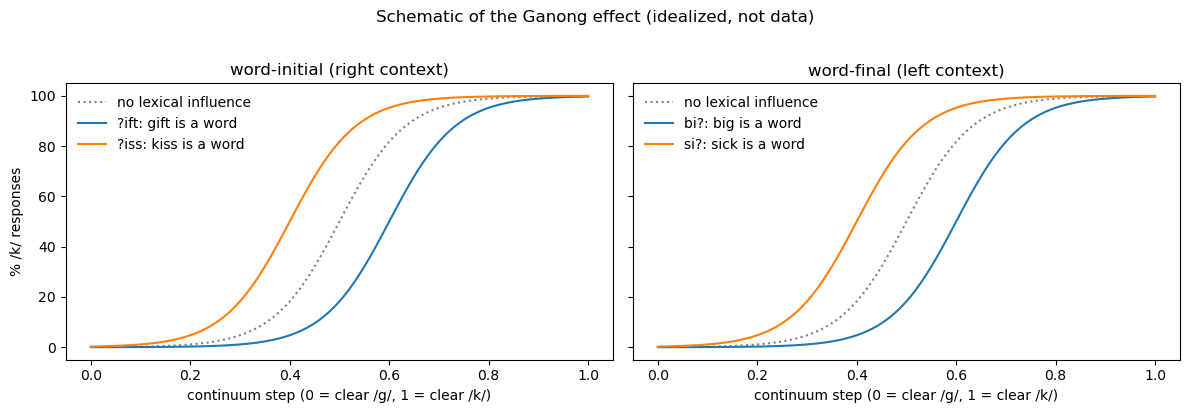

In [40]:
# A schematic of the Ganong effect (idealized curves, NOT data). Each curve is a logistic
# identification function; the lexicon moves the category boundary toward the nonword end.
steps = np.linspace(0, 1, 101)

def identification(boundary, slope=15):
    # % /k/ responses at each step, for a category boundary at `boundary`
    return 100 / (1 + np.exp(-slope * (steps - boundary)))

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
panels = [('word-initial (right context)', '?ift: gift is a word', '?iss: kiss is a word'),
          ('word-final (left context)', 'bi?: big is a word', 'si?: sick is a word')]
for ax, (title, g_label, k_label) in zip(axes, panels):
    ax.plot(steps, identification(0.5), color='gray', linestyle=':', label='no lexical influence')
    ax.plot(steps, identification(0.6), label=g_label)   # /g/ makes a word: fewer /k/ responses
    ax.plot(steps, identification(0.4), label=k_label)   # /k/ makes a word: more /k/ responses
    ax.set_title(title)
    ax.set_xlabel('continuum step (0 = clear /g/, 1 = clear /k/)')
    ax.legend(frameon=False, loc='upper left')
axes[0].set_ylabel('% /k/ responses')
fig.suptitle('Schematic of the Ganong effect (idealized, not data)', y=1.02)
plt.tight_layout()
plt.show()

### Simulating the Ganong effect

Now the payoff. We present a continuum of sounds from a clear /g/ (step 0) to a clear /k/ (step 1), made by blending the two feature vectors, in the four frames above:

- **word-initial** (right context: the context comes *after* the ambiguous sound): *?ift* (*gift* is a word, *kift* is not) and *?iss* (*kiss*, not *giss*);
- **word-final** (left context: the context comes *before* it): *bi?* (*big*, not *bick*) and *si?* (*sick*, not *sig*).

For each step, we report the probability of /k/ (out of /g/ and /k/) in the three ways described above. A Ganong effect is a difference between the two frames for the same position: more /k/ where /k/ makes a word. (The two curves in each panel are shifted very slightly sideways, so that you can see both where they lie on top of each other.)

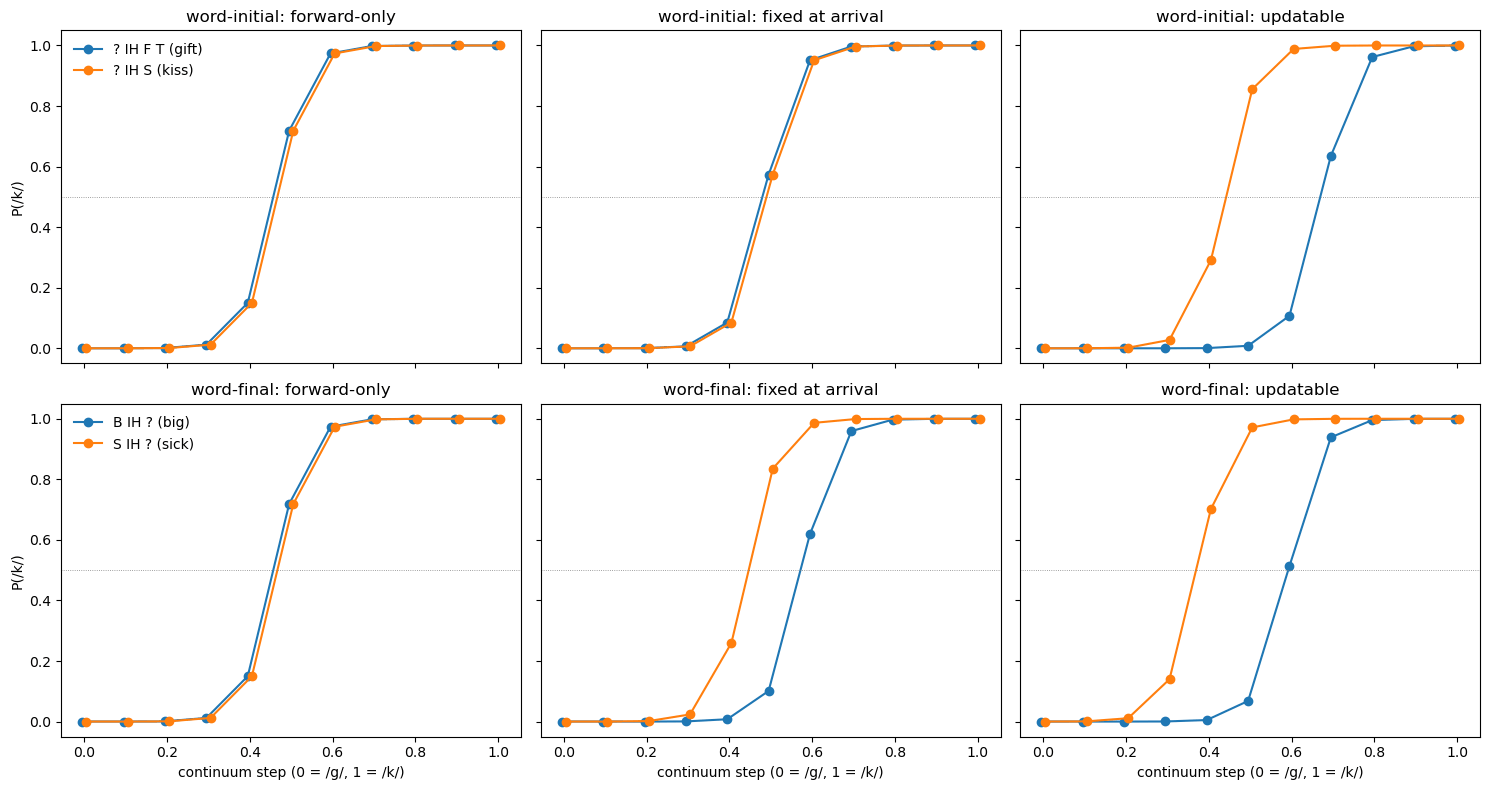

position,word-initial,word-final
report,,
forward-only,0.000,0.000
fixed at arrival,0.000,0.129
updatable,0.223,0.209


In [41]:
def make_input_vectors(frame, alpha):
    # One feature vector per position of the frame (e.g. '? IH F T'), then silence. '?' is the
    # ambiguous sound: a blend of /g/ and /k/ (alpha = 0 is pure /g/, alpha = 1 is pure /k/).
    vectors = []
    for p in frame.split() + [SILENCE]:
        if p == '?':
            vectors.append((1 - alpha) * symbol_vectors[G] + alpha * symbol_vectors[K])
        else:
            vectors.append(symbol_vectors[symbols.index(p)])
    return vectors


def report_k(frame, alpha, mode, epsilon=EPSILON):
    # P(/k/) for the ambiguous slot ('?') in frame
    slot = frame.split().index('?')
    vectors = make_input_vectors(frame, alpha)
    evidence_rows = [evidence_for(v) for v in vectors]
    log_lik = word_log_likelihoods(evidence_rows, epsilon)
    if mode == 'forward-only':
        message = q                                                       # phoneme frequencies only
    elif mode == 'fixed at arrival':
        message = message_to_phoneme(log_lik, slot, list(range(slot)), epsilon)
    else:                                                                 # 'updatable'
        others = [t for t in range(len(vectors)) if t != slot]
        message = message_to_phoneme(log_lik, slot, others, epsilon)
    belief = message * evidence_rows[slot]
    return belief[K] / (belief[G] + belief[K])


frames = {'word-initial': [('? IH F T', 'gift'), ('? IH S', 'kiss')],
          'word-final': [('B IH ?', 'big'), ('S IH ?', 'sick')]}
modes = ['forward-only', 'fixed at arrival', 'updatable']
alphas = np.linspace(0, 1, 11)

fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True, sharey=True)
ganong_rows = []
for row, (position, pair) in enumerate(frames.items()):
    for col, mode in enumerate(modes):
        ax = axes[row, col]
        curves = {}
        for n, (frame, word) in enumerate(pair):
            curves[word] = [report_k(frame, a, mode) for a in alphas]
            # shift the two curves very slightly sideways, so both stay visible where they overlap
            shiftval = 0.005
            shift = -shiftval if n == 0 else shiftval
            ax.plot(alphas + shift, curves[word], marker='o', label=f'{frame} ({word})')
        ax.axhline(0.5, color='gray', linewidth=0.6, linestyle=':')
        ax.set_title(f'{position}: {mode}')
        if row == 1:
            ax.set_xlabel('continuum step (0 = /g/, 1 = /k/)')
        if col == 0:
            ax.set_ylabel('P(/k/)')
            ax.legend(frameon=False, loc='upper left')
        g_curve = curves[pair[0][1]]   # the first frame is the one where /g/ makes a word
        k_curve = curves[pair[1][1]]   # the second, where /k/ does
        ganong_rows.append({'position': position, 'report': mode,
                            'Ganong effect': round(np.mean(k_curve) - np.mean(g_curve), 3)})
plt.tight_layout()
plt.show()

# Ganong effect: mean P(/k/) in the /k/-word frame minus the /g/-word frame
display(pd.DataFrame(ganong_rows).pivot(index='report', columns='position', values='Ganong effect').loc[modes, ['word-initial', 'word-final']])

- **Forward-only** (the phoneme level on its own, using only overall phoneme frequencies): no lexical effect at all. The two curves lie on top of each other (apart from our slight sideways shift), because the phoneme level never hears from the words.
- **Fixed at arrival**: a word-final effect (+.13), but nothing word-initially. When the ambiguous sound arrives at the start of *?ift*, the words have heard nothing yet, so they have nothing to say about it, and the belief is never revised.
- **Updatable**: both (+.22 word-initially, +.21 word-finally). The word-final effect is larger than with the fixed belief because the silence after *bi?* tells the listener that the word is over, which rules out longer words such as *bigger* and *bicker*.

Notice that the lexical effects shift the category boundary but leave the ends of the continuum alone: a clear /k/ is still heard as /k/ in *kift*. That is the job of $\varepsilon$. Try `EPSILON = 0.01` and `EPSILON = 0.5` to see what happens.

### How the top-down signal produces the Ganong effect

In our model, the Ganong effect comes from one multiplication, at the ambiguous phoneme: its own **bottom-up evidence** times the **top-down prediction from the words**. For the ambiguous slot (say, the first sound of *?ift*), the belief about each candidate phoneme $k$ is

$$
\text{belief}(k) \;\propto\; \underbrace{E(k)}_{\text{bottom-up evidence}} \times \underbrace{m(k)}_{\text{top-down prediction}}
$$

- **Bottom-up, $E(k)$**, is how well the sound itself matches /k/'s feature vector (the Gaussian likelihood from Part 5). It depends only on the sound.
- **Top-down, $m(k)$**, is the words' prediction for that slot:

$$
m(k) = (1-\varepsilon)\sum_{\text{words with } k \text{ in the slot}} P(\text{word} \mid \text{other input}) \;+\; \varepsilon\, q(k)
$$

where 'other input' is the evidence from every *other* position. For *?ift*, that is /ɪ f t/ and the silence after it. The words that fit it (*gift*, *lift*, *shift*, *sift*, ...) get most of the probability. Of these, only *gift* has /g/ in the slot, and no word has /k/ there (*kift* is not a word). So $m(g)$ gets $(1-\varepsilon)$ times the probability of *gift*, while $m(k)$ gets only the small mispronunciation term $\varepsilon\, q(k)$: the top-down signal strongly favors /g/.

**Why it shifts the category boundary.** Because we report /k/ against /g/, write the belief as odds and take logs:

$$
\log\frac{P(k)}{P(g)} \;=\; \underbrace{\log\frac{E(k)}{E(g)}}_{\text{bottom-up}} \;+\; \underbrace{\log\frac{m(k)}{m(g)}}_{\text{top-down}}
$$

The two signals simply *add*. For our blended sounds, the bottom-up term is a straight line in the continuum step $\alpha$: the sound is $(1-\alpha)\,f_g + \alpha\, f_k$, so its squared distances to the /g/ and /k/ feature vectors are $\alpha^2 D$ and $(1-\alpha)^2 D$ (where $D$ is the squared distance between /g/ and /k/), and the bottom-up log odds are $(2\alpha - 1)\,D / 2\sigma^2$. So the identification curve is a logistic function of $\alpha$. The top-down term depends on the *other* phonemes, not on the ambiguous sound, so within a frame it is a constant. Adding a constant to a logistic function slides the whole curve sideways without changing its shape. That is the Ganong effect: the category boundary moves toward the nonword end of the continuum (more /g/ responses in *?ift*, more /k/ in *?iss*), by $\Delta\alpha = -\sigma^2 \log\big(m(k)/m(g)\big) / D$.

- The effect is largest in the ambiguous middle of the continuum, where the bottom-up term is near 0 and the top-down term decides.
- Clear endpoints survive. At $\alpha = 1$, the bottom-up odds for /k/ are enormous, and they outweigh the top-down odds. $\varepsilon$ makes this possible: it keeps $m(k)$ above 0. With $\varepsilon = 0$, the top-down signal for /k/ in *?ift* would be exactly 0, and the model would *never* hear /k/ there, however clear it was.
- In the forward-only model, $m(k)$ is just the overall phoneme frequency $q(k)$, the same in both frames, so the two curves coincide. (They are shifted a little from the middle of the continuum, because /g/ and /k/ differ in overall frequency.)

**Why position and timing matter.** The top-down constant is computed from whatever 'other input' the message is allowed to use. *Fixed at arrival*, it uses only the input before the slot. Word-initially there is none, so the message is just the overall frequency of word-initial /g/ and /k/, the same in *?ift* and *?iss*: no Ganong effect. Word-finally, the /b ɪ/ of *bi?* already narrows the words down (*big*, *bit*, *bill*, *bigger*, *bicker*...), so there is an effect. *Updatable*, it uses all the other input: word-initially, *-ift* or *-iss* now enters the message (a right-context effect), and word-finally the silence after the word rules out longer words such as *bigger* and *bicker*, which strengthens the effect. In the time-course plot below, the message is recomputed as each slice of input arrives, so the top-down constant changes over time: word-initially, it is the same in both frames until the third sound (/f/ vs. /s/) tells them apart.

**What if the other sounds are uncertain too?** 'Given the other input' does not mean that the other phonemes are known. Every word gets a weight that reflects how well it matches the evidence at *every* other position, multiplied together, times its prior. Suppose the vowel of *?ift* were itself unclear -- say the evidence favored /ɪ/, but /ɛ/ was also possible. Then words with /ɛ/ there (*left*, *heft*, ...) would not be ruled out, only down-weighted, and they would join the prediction for the slot, each one voting for its own first phoneme. So a word can be partly 'wrong' at an uncertain position and still contribute; how much depends on how well it fits *all* the other evidence. Words that differ from the input in the slot itself vote for other phonemes there, and so compete with /g/ and /k/ (and since we report /k/ out of /g/ and /k/, those votes mostly drop out of the comparison).

**And word recognition is untouched.** The top-down signal shapes only the phoneme level's *belief*. It is never sent back up: the words always receive the raw evidence $E$. So the same signal that produces the Ganong effect at the phoneme level leaves the word probabilities exactly as they are in the feedforward model.

### Watching the right context arrive

Real speech arrives over time. To see the updatable belief at work, we split each sound into 4 *slices* of evidence that arrive one after another (each slice carries less information: its evidence is computed as if the noise had standard deviation $\sigma\sqrt{4}$, so that together the 4 slices carry the same information as one whole sound). After every slice, we recompute the belief about the ambiguous sound from all the input so far -- its own slices, and the words' message given everything else heard so far. Before the ambiguous sound arrives, its 'belief' is just the words' prediction. We use a sound exactly halfway between /g/ and /k/.

In [ ]:
def belief_time_course(frame, alpha=0.5, slices=4, epsilon=EPSILON):
    # P(/k/) for the ambiguous slot after every slice, from word onset to the end of the silence
    phonemes = frame.split() + [SILENCE]
    slot = phonemes.index('?')
    slice_sigma = sigma * np.sqrt(slices)
    vectors = make_input_vectors(frame, alpha)
    log_evidence = np.zeros((len(phonemes), len(symbols)))   # summed log evidence from the slices so far
    trace, labels = [], []
    for t, vector in enumerate(vectors):
        for s in range(slices):
            # one more slice of evidence for position t (each slice adds its log evidence)
            sq_distances = ((symbol_vectors - vector) ** 2).sum(axis=1)
            log_evidence[t] += -sq_distances / (2 * slice_sigma ** 2)
            # turn each position's summed log evidence into probabilities (as in evidence_for)
            evidence_rows = []
            for row in log_evidence[:t + 1]:
                weights = np.exp(row - row.max())
                evidence_rows.append(weights / weights.sum())
            log_lik = word_log_likelihoods(evidence_rows, epsilon)
            others = [u for u in range(t + 1) if u != slot]
            message = message_to_phoneme(log_lik, slot, others, epsilon)
            if t >= slot:
                belief = message * evidence_rows[slot]           # its own evidence has started to arrive
            else:
                belief = message                                  # not heard yet: the prediction alone
            trace.append(belief[K] / (belief[G] + belief[K]))
            labels.append(f"{'?' if t == slot else phonemes[t]}{s + 1}")
    return trace, labels


fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
slices = 4   # slices per sound
for ax, (position, pair) in zip(axes, frames.items()):
    all_labels = []
    for frame, word in pair:
        trace, labels = belief_time_course(frame, slices=slices)
        ax.plot(range(len(trace)), trace, marker='o', markersize=3, label=f'{frame} ({word})')
        all_labels.append(labels)
    # one tick label per slice; where the two frames differ, show both (e.g., F1/S1)
    first, second = sorted(all_labels, key=len, reverse=True)
    labels = [a if a == b else f'{a}/{b}' for a, b in zip(first, second)] + first[len(second):]
    slot_start = labels.index('?1')
    ax.axvspan(slot_start - 0.5, slot_start + slices - 0.5, color='orange', alpha=0.15)
    ax.set_xticks(range(len(labels)))
    ax.set_xticklabels(labels, rotation=90, fontsize=7)
    ax.set_ylim(-0.02, 1.02)
    ax.axhline(0.5, color='gray', linewidth=0.6, linestyle=':')
    ax.set_title(f'{position}: belief about the ambiguous sound (shaded) over time')
    ax.set_xlabel('slice')
    ax.legend(frameon=False, loc='lower left')
axes[0].set_ylabel('P(/k/)')
plt.tight_layout()
plt.show()

**Word-initially** (left), the belief about the ambiguous sound is the same in both frames until the first sound that distinguishes *gift* from *kiss*: the third one, /f/ vs. /s/. Then the two split, and by the end of that sound the effect is nearly complete. So a word-initial Ganong effect takes *time*: a listener who responded before the disambiguating sound arrived would show none. That is a testable prediction about response times.

**Word-finally** (right), the effect is in place *before the ambiguous sound even begins*. While the vowel is heard, the words already predict /g/ after *bi-* and /k/ after *si-*. The ambiguous sound itself changes little, and the silence afterward, which rules out longer words, strengthens the effect further.

### What have we gained?

We added top-down information to the phoneme level without changing word recognition at all: the words still see only the bottom-up evidence, so the model is exactly as good a word recognizer as before. But the model can now do something it could not do before: its phoneme representations are informed by the lexicon, in both directions in time, so it produces Ganong effects word-initially and word-finally *within one system*, with no separate decision module. The same principle extends to other top-down effects, such as phoneme restoration, and, if the generative model includes coarticulation, lexically mediated compensation for coarticulation, which a decision-only module like Merge cannot produce.

Two cautions. First, the size of every lexical effect here depends on $\varepsilon$ and $\sigma$, which we chose rather than estimated. Second, our recognizer is still *exact*: it computes the right posterior in one step. Real brains (and models like TRACE, our next notebook) have to settle over time, and in such systems feedback may change not just *what* is perceived but *when*.

# Lab report

1. Write a brief summary of the Bayesian approach we are using here (3-4 sentences). Include what *conditional independence* means, and where our model assumes it.

2. Look at the plots of word and phoneme probabilities that `plot_simulation_result` made in Part 5, for single words such as *boo*, *boot*, *go*, and *dog*. What observations can you make? Does it seem the system works well?

3. Replot, but set `full_scale=True`, which will make the Y axes go from 0 to 1. Where? In Part 5, find the code cell that begins with `# Pick ONE word list` (just after 'Why is *boo* not recognized?'). Its last line is `plot_simulation_result(aggregated_word_results, aggregated_phoneme_results, full_scale=False)`. Change `False` to `True` and run the cell again -- or paste the line below into a new code cell right after it. Now review the new plots. What kinds of changes do you see? Are there any things that seem problematic?

```python
plot_simulation_result(aggregated_word_results, aggregated_phoneme_results, full_scale=True)
```

4. What are some other words you think might be interesting to examine? Run new simulations with your words. Replace the word list below with the words you want to examine and copy the 3 lines of code into a new code cell. Run it. Include the code lines in your report. Explain why you chose the words you did, and report some observations about the results. (Also, if you scroll to the bottom of this notebook, there's a code snippet a student developed in 2024 that will randomly pick 8 words -- this is a nice way to explore words you might not have thought to test.)

```python
# change the words in word list; you can make the list longer or shorter. Try at least 4 words.
word_list = ['cat', 'dog', 'abrupt', 'territory', 'abandon', 'clamp', 'intolerable', 'go']
aggregated_word_results, aggregated_phoneme_results = run_simulations(word_list, lexicon_df, phoneme_confusion_df, phoneme_prob_dict)
plot_simulation_result(aggregated_word_results, aggregated_phoneme_results, full_scale=True)
```

5. Do you see any problems with the results so far? List them, but also try to pair each problem with a possible solution -- something you could change in the simulations that might improve results. Try to think of at least 2 or 3. 

6. Look at the regressions in Part 6 (under 'Model reaction times vs. human reaction times'), which compare human reaction times (AELP) with the model's recognition points.
    - (a) Where do the human and model betas agree, and where do they differ most?
    - (b) Pick one difference -- for example, the uniqueness point -- and explain, in your own words, why it might arise. (Part 6 offers some ideas.)

#### Challenge questions -- optional

*You can do one or more of these for extra credit.*

7. *Programming challenge.* Write a function that takes a dataframe like `aggregated_word_results` and finds a *threshold* reaction time for each word: the first position at which the target's probability reaches some value, such as 0.5 or 0.9. Compare your threshold times with the recognition points from Part 6 for the same words. Which seems more plausible as a model of reaction time, and why?

8. *Theoretical challenge.* What are some aspects of spoken word recognition that are missing from our current approach? Consider the challenges from the Magnuson & Crinnion (2022) review -- for example, how listeners find the boundaries between words in continuous speech, where there is usually no silence between them (see Parts 5 and 7).

9. *Modeling challenge.* Our model's input is feature-based, and the RSA showed that the features match human confusions for speech in noise only modestly. Swap in Luce's confusion-based probabilities by running

```python
phoneme_confusion_df = add_silence(confusion_based_distance_df, confusion_based_clarity)
```

after the Part 5 cell that defines `phoneme_confusion_df`, and then rerun the cells of Part 6. How does word accuracy change? Which confusions does the model make now, and do they look more like the errors listeners make? Do the regression betas change? Then try a lower clarity, such as `calibrate_clarity(confusion_based_distance_df.values, target_accuracy=0.7)`, trying to approximate the noise level of Luce's experiment. What happens to accuracy, and to the kinds of errors? (Parts 7 and 8 compute their evidence from the feature vectors directly, so they are not affected by this switch.)

10. *Modeling challenge.* Notebook 06 (`06-pseudo-swr-analysis.ipynb`) used **neighbors**, with pseudo data: words that differ from the target by one phoneme deletion, addition, or substitution (the DAS rule). We have already worked with cohorts in Part 6; now compute neighbors for real words. Add neighbor counts to the regressions in Part 6, for both the humans and the model. Do they predict human RTs? Do they predict the model's recognition points? Does adding them change the other betas? What would you expect, given how the model works?

Neighbors take more thought. Comparing every word with every other word means about 300 million comparisons, which is too slow in plain Python. A faster way, for substitutions: replace each phoneme of a word, in turn, with `*` (so *cat*, K AE T, gives `* AE T`, `K * T`, and `K AE *`), and count how many pronunciations produce each pattern. Two words are substitution neighbors if they share a pattern. For deletions and additions, delete each phoneme in turn and look the result up in the set of pronunciations. You might also try a frequency-weighted version (summing the neighbors' frequencies instead of counting them).

11. *Modeling challenge.* In Part 5, *boo* was heard as *be*, because frequency outweighed clear bottom-up evidence. Can you find a better balance between frequency and the bottom-up evidence, so that the model recognizes more words? There are two knobs. (a) **Clarity**: calibrate $c$ to a higher target accuracy than 95% (e.g., `calibrate_clarity(feature_distance_matrix, target_accuracy=0.99)`), then rebuild `phoneme_confusion_df` as in Part 5. (b) **The weight of frequency**: make the prior proportional to $frequency^{\,e}$ with an exponent $e$ below 1. `sim_bayes_new` already has `freq_exponent`; for the whole lexicon, change the `log_prior` line in `recognize_lexicon` to `log_prior = freq_exponent * np.log(by_pron['Frequency'].values)` and add `freq_exponent` as a parameter. Which settings recognize the most words in Part 6? Now a catch: Part 6 tests every word *once*, so rare words count as much as common ones. Would your best settings still be best if words were tested as often as listeners actually hear them, as in the noise demo of Part 7? Why might the two answers differ? (Hint: think about what the prior is *for*.)

12. *Modeling challenge.* 'What task is the model doing?' (Part 6) describes what it would take for the model to perform lexical decision, the task in AELP: a *catch-all* (unknown-word) hypothesis, and a decision rule that waits for the end of the word. Implement it, starting from `recognize_lexicon`. Add one extra hypothesis that explains any input moderately well -- for example, a random string of phonemes drawn with their usual frequencies (`phoneme_prob_dict`) -- with a prior of 0.5, about the proportion of nonwords in AELP. Then, after the silence that follows each word, compute the probability that a *complete* word has been heard (rather than a longer word, or the catch-all). Use the point at which that probability passes a threshold as the model's lexical-decision time, and rerun the regressions. Does the uniqueness-point effect shrink, as it does for listeners? What happens to short words?

13. *Modeling challenge.* The noise demo in Part 7 assumed that the listener knows exactly how noisy the input is. What if it does not? Change `noisy_evidence` so that the noise added to the input (`noise_sigma`) and the noise the listener *assumes* when it computes the evidence can differ (for example, add a parameter `assumed_sigma`), and pass it through `recognize_noisy`. Rerun the comparison for a listener who assumes the speech is clearer than it really is. Does feedback help now? Does it help more than simply giving the listener the right noise level, or than squaring the prior? What does your answer say about when feedback might be useful?

14. *Modeling challenge.* In our simulation of Allopenna, Magnuson, and Tanenhaus (1998) at the end of Part 6, the model captured the cohort effect but gave the rhyme competitor almost no probability, while listeners look at rhymes a small but reliable amount. How might we enhance rhyme effects in the simulation? Try one or more of these, and see what each does to the rhyme *and* to the cohort:
    - **Noisier input.** Rebuild `phoneme_confusion_df` with a lower target accuracy (Part 5), and rerun the simulation.
    - **A gentler penalty for a mismatch.** A single clear mismatch at the onset is nearly fatal, because the likelihood multiplies the evidence across positions. Allow for mispronunciations, as $\varepsilon$ does in Part 8, or raise each position's evidence to a power below 1 before multiplying.
    - **Alignment in time.** Our model compares words position by position from the onset, which is why we had to drop the *beaker*/*speaker* set. Let a word's match to the input begin one position later (as *speaker* would need), and add that set back.
    - **A different linking hypothesis.** Allopenna and colleagues turned model activations into fixation probabilities with a choice rule, among the four pictures. Try converting the probabilities differently -- for example, using log probabilities, or including word frequency.

Which change brings the model closest to the human pattern, in which looks to the rhyme rise later than looks to the cohort, and stay lower, but clearly above looks to the unrelated object? Is your change still a sensible Bayesian model -- that is, can you say what it assumes about how speech is produced or perceived?

------
### An example improvement from 2024

Choosing a random sample of words. The code below will run simulations with a different set of 8 randomly chosen words every time you run it. 

*Note that this occasionally throws an error; you can ignore it and just 'play' the cell again.*

--- Starting simulation of word communicative	... Time for simulation: 0.058558 seconds
--- Starting simulation of word keeping	... Time for simulation: 0.041433 seconds
--- Starting simulation of word challenging	... Time for simulation: 0.043919 seconds
--- Starting simulation of word botany	... Time for simulation: 0.041119 seconds
--- Starting simulation of word sleeping	... Time for simulation: 0.042292 seconds
--- Starting simulation of word depending	... Time for simulation: 0.042781 seconds
--- Starting simulation of word collect	... Time for simulation: 0.038641 seconds
--- Starting simulation of word taffeta	... Time for simulation: 0.038174 seconds


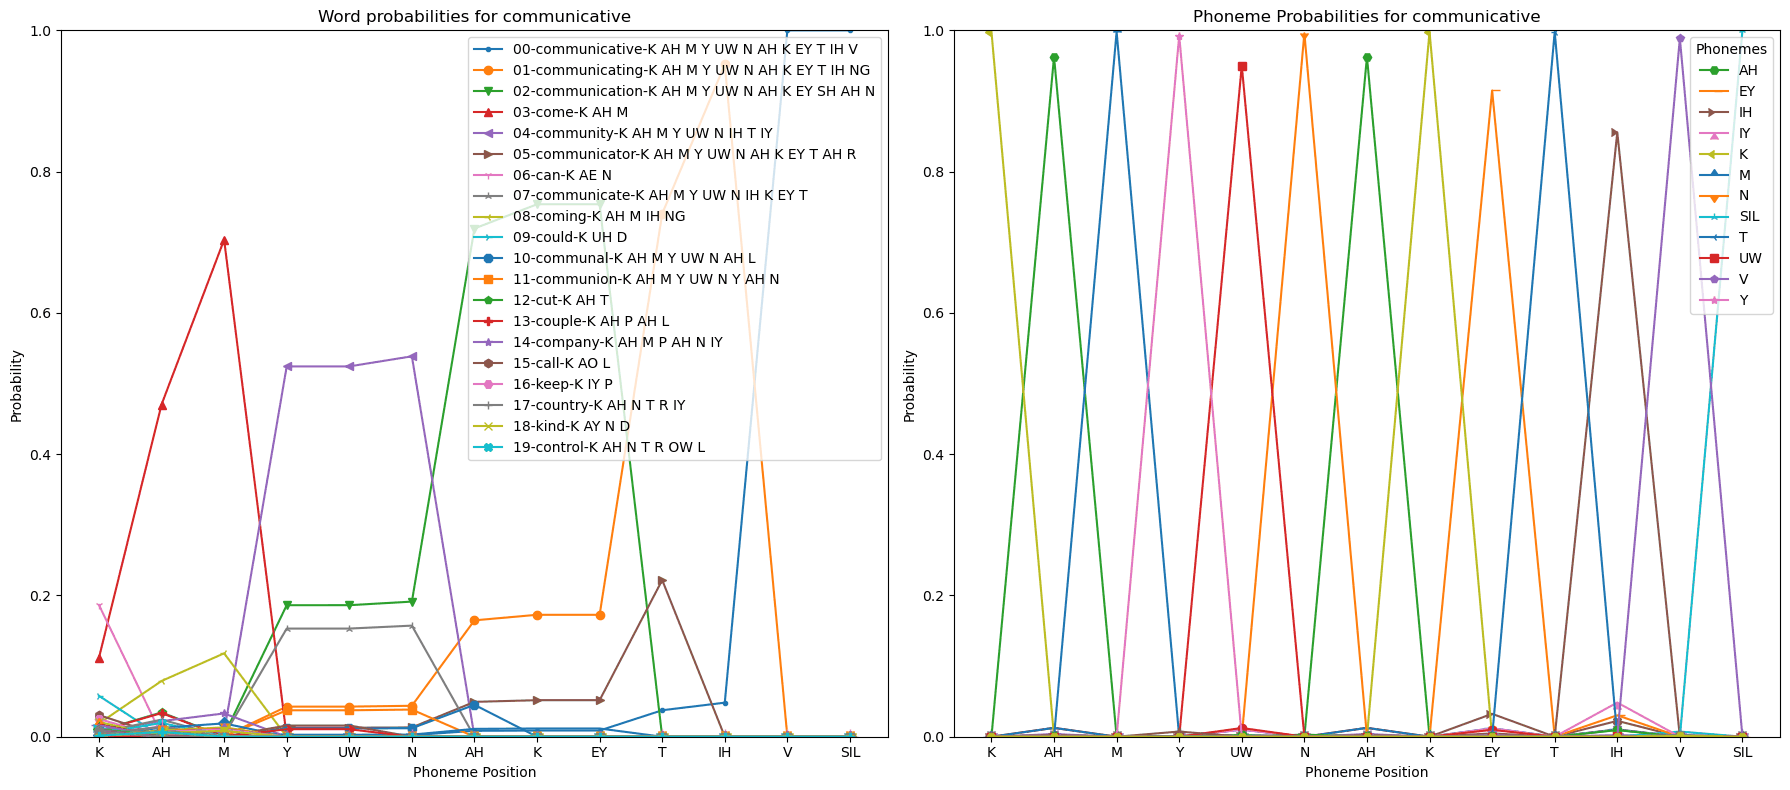

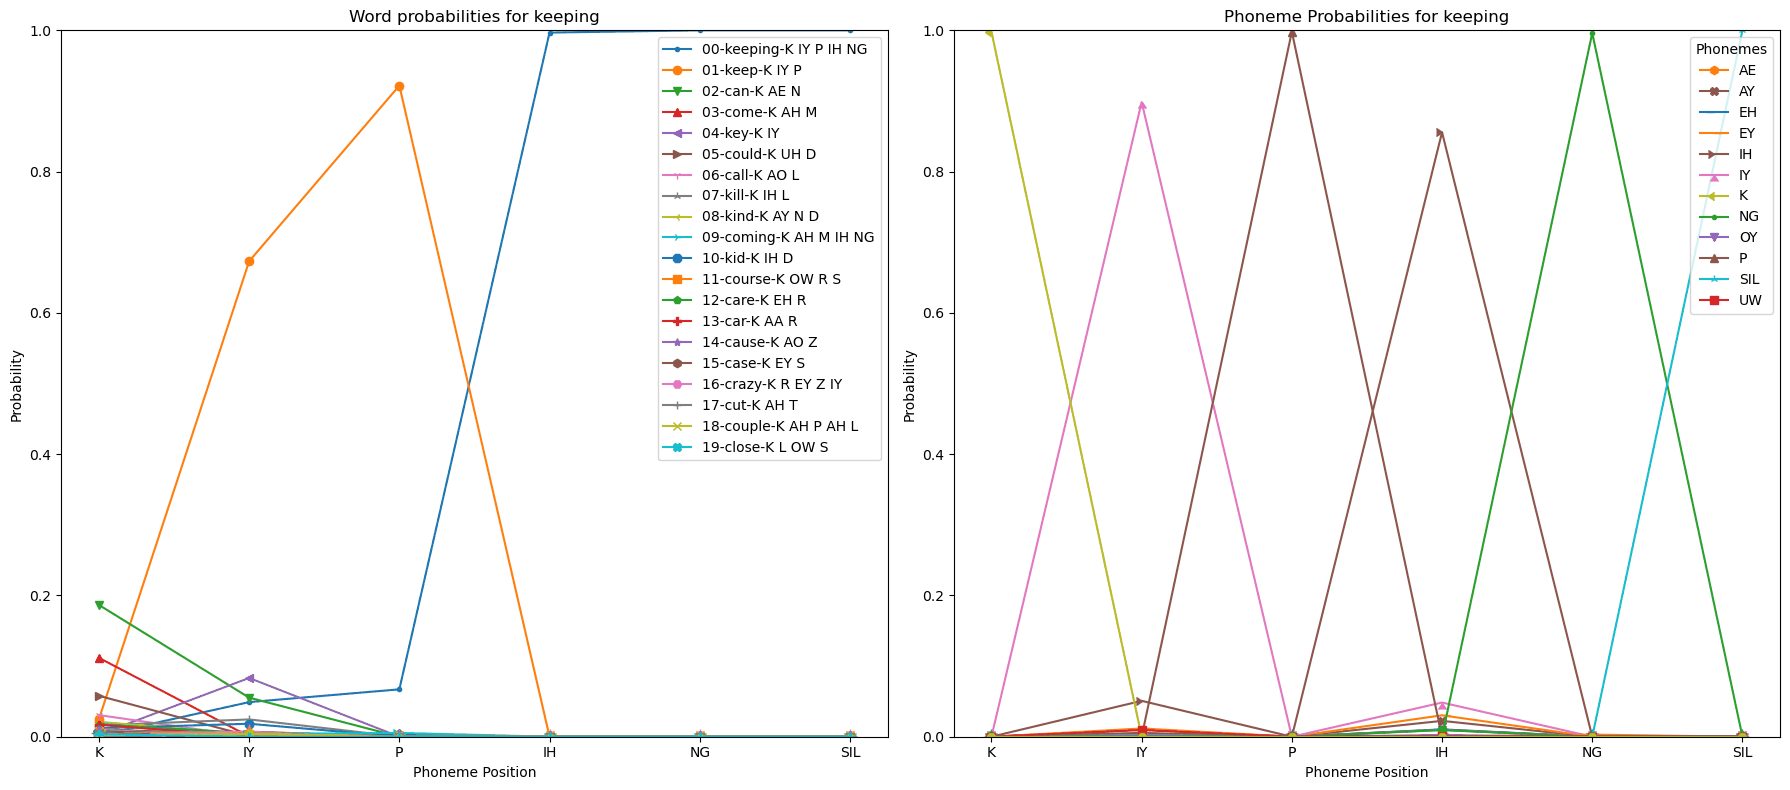

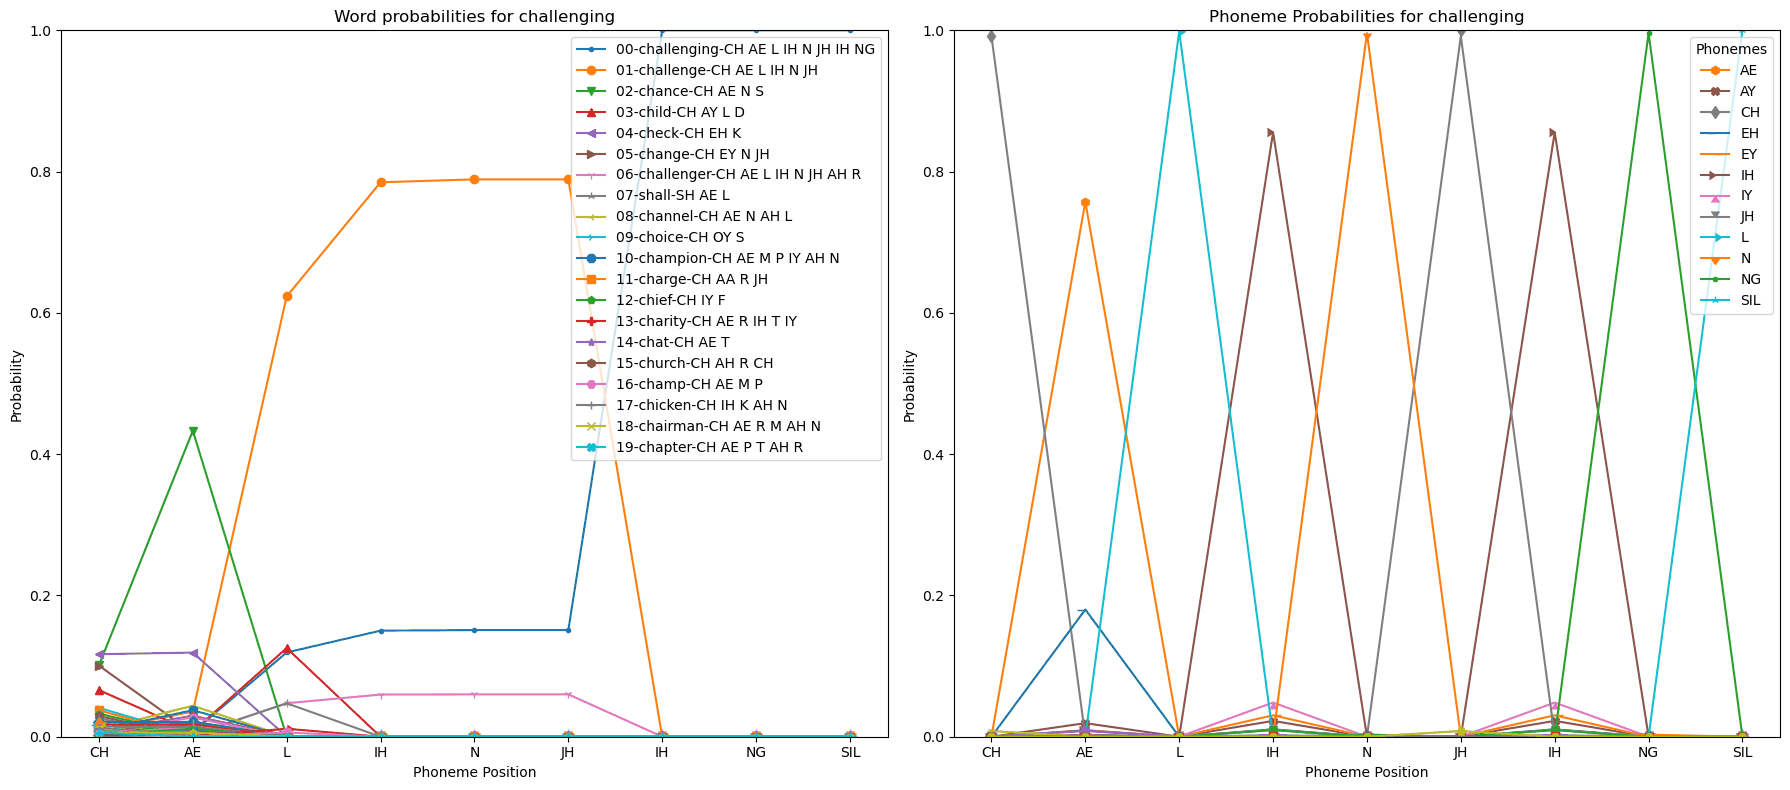

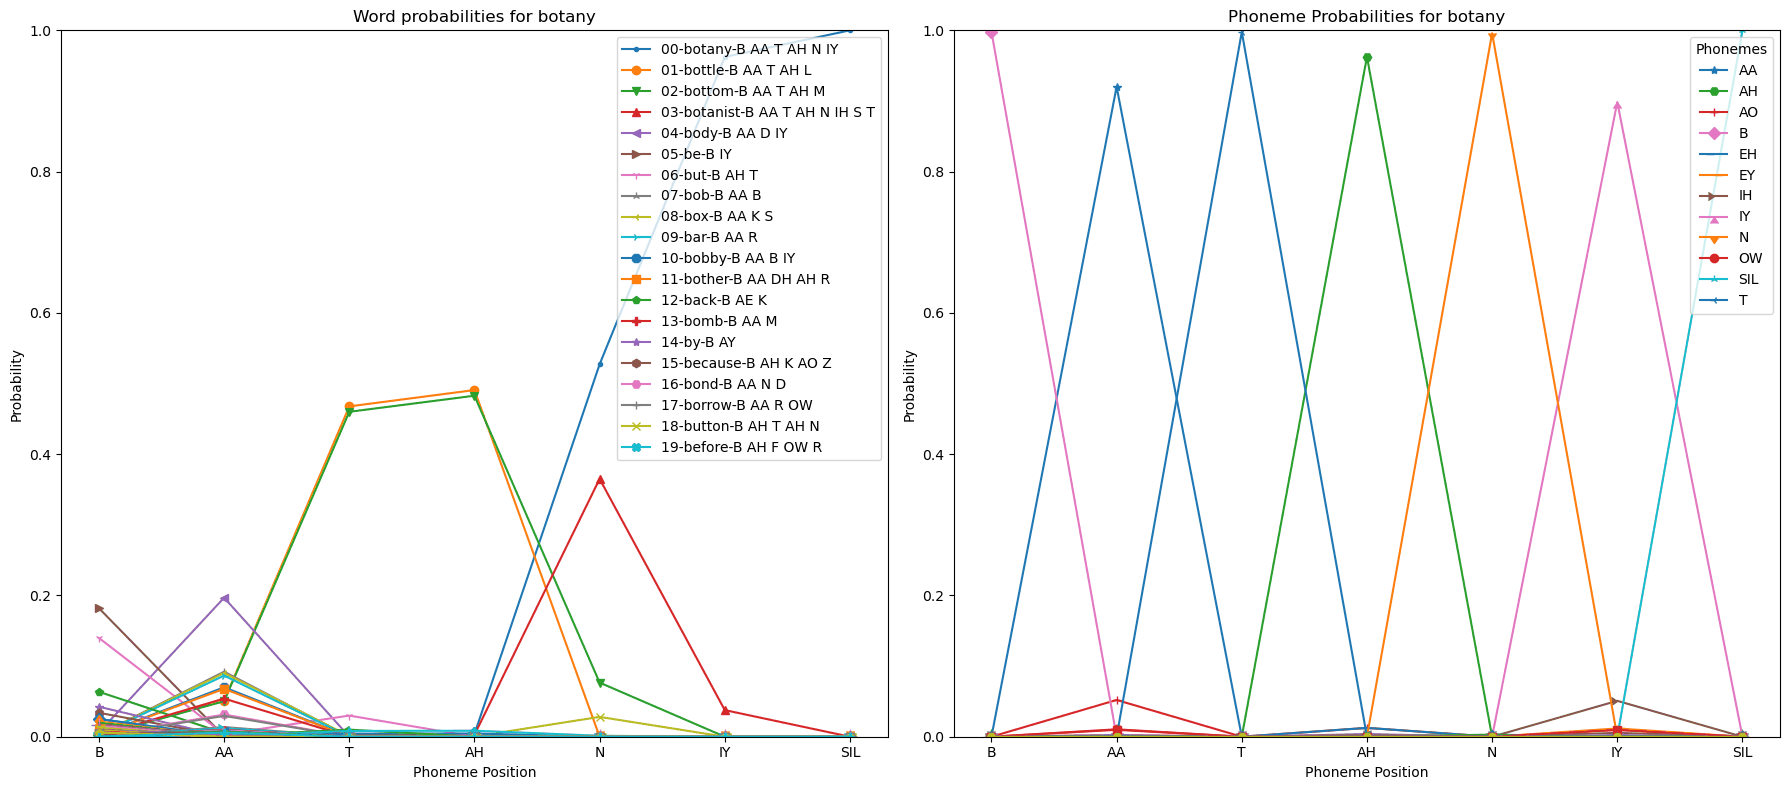

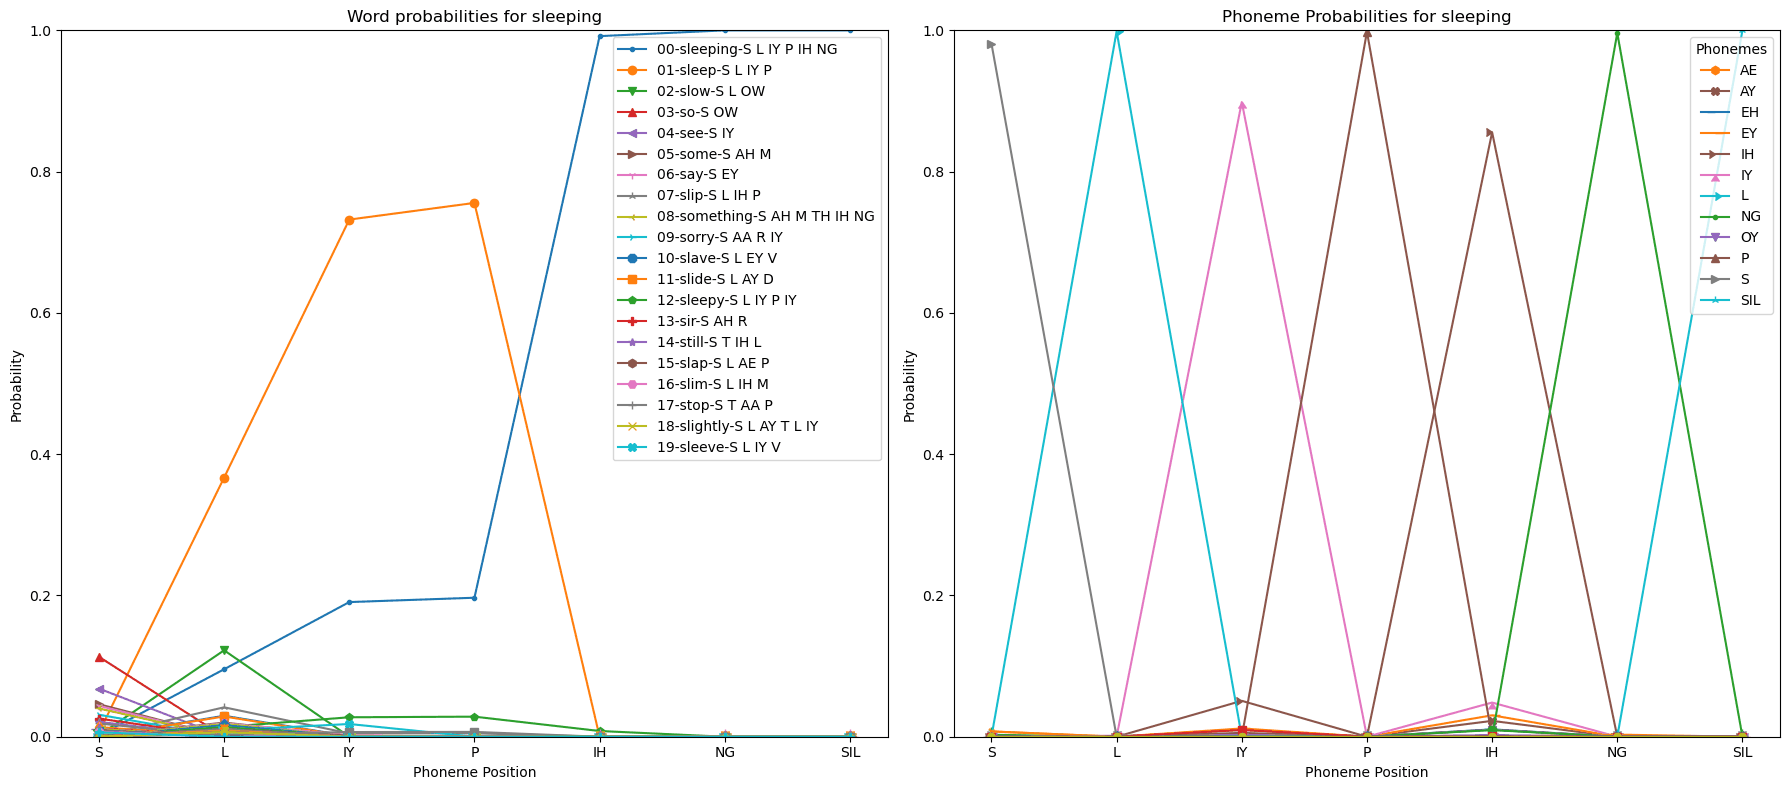

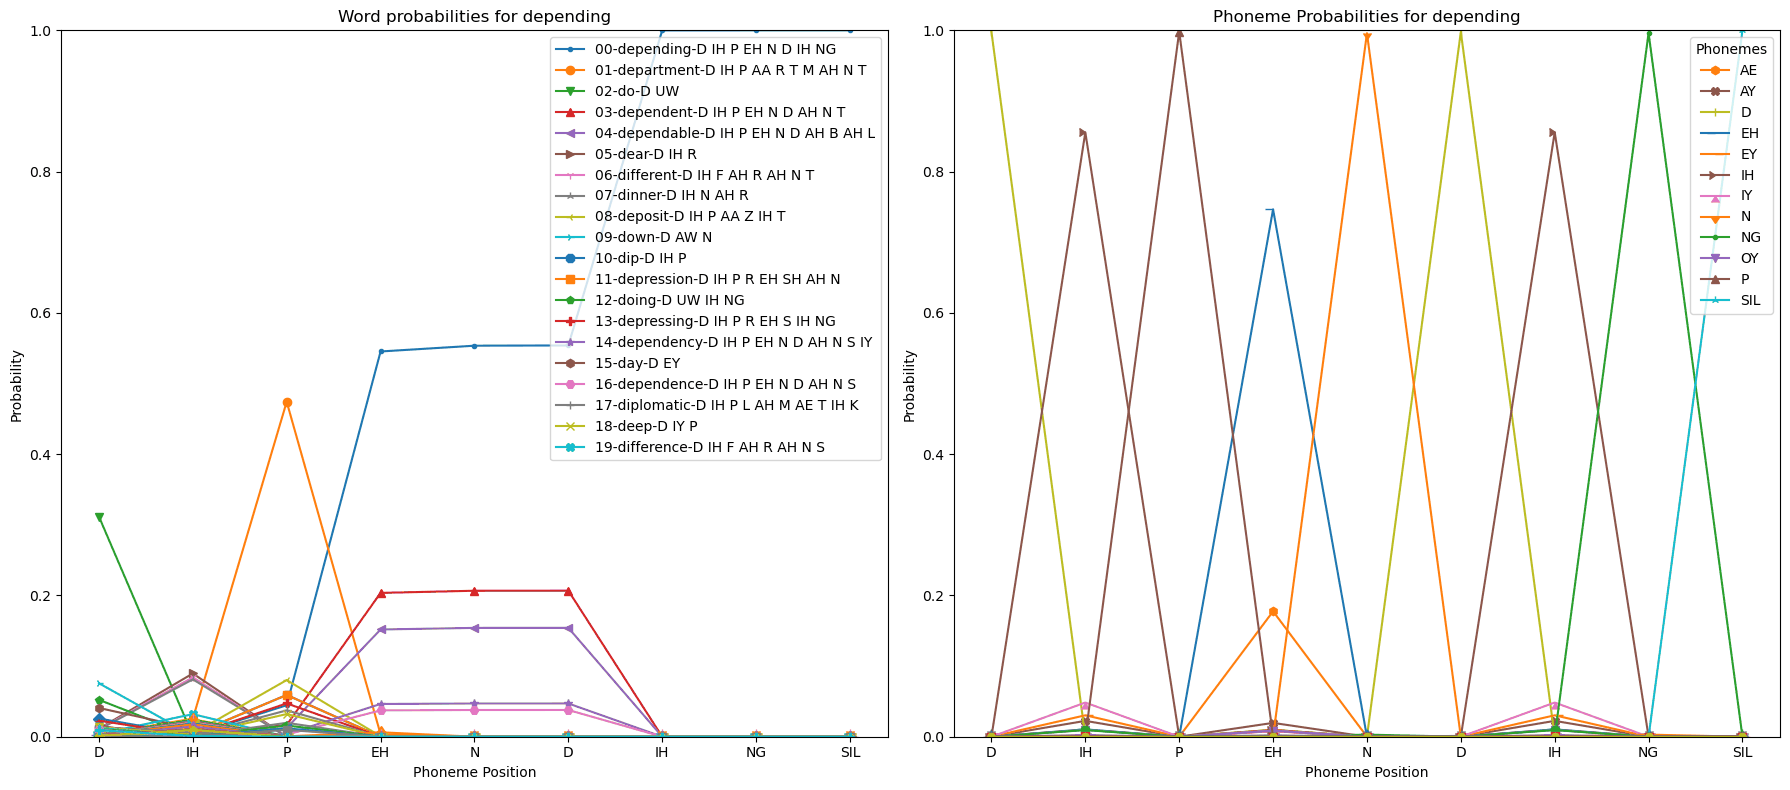

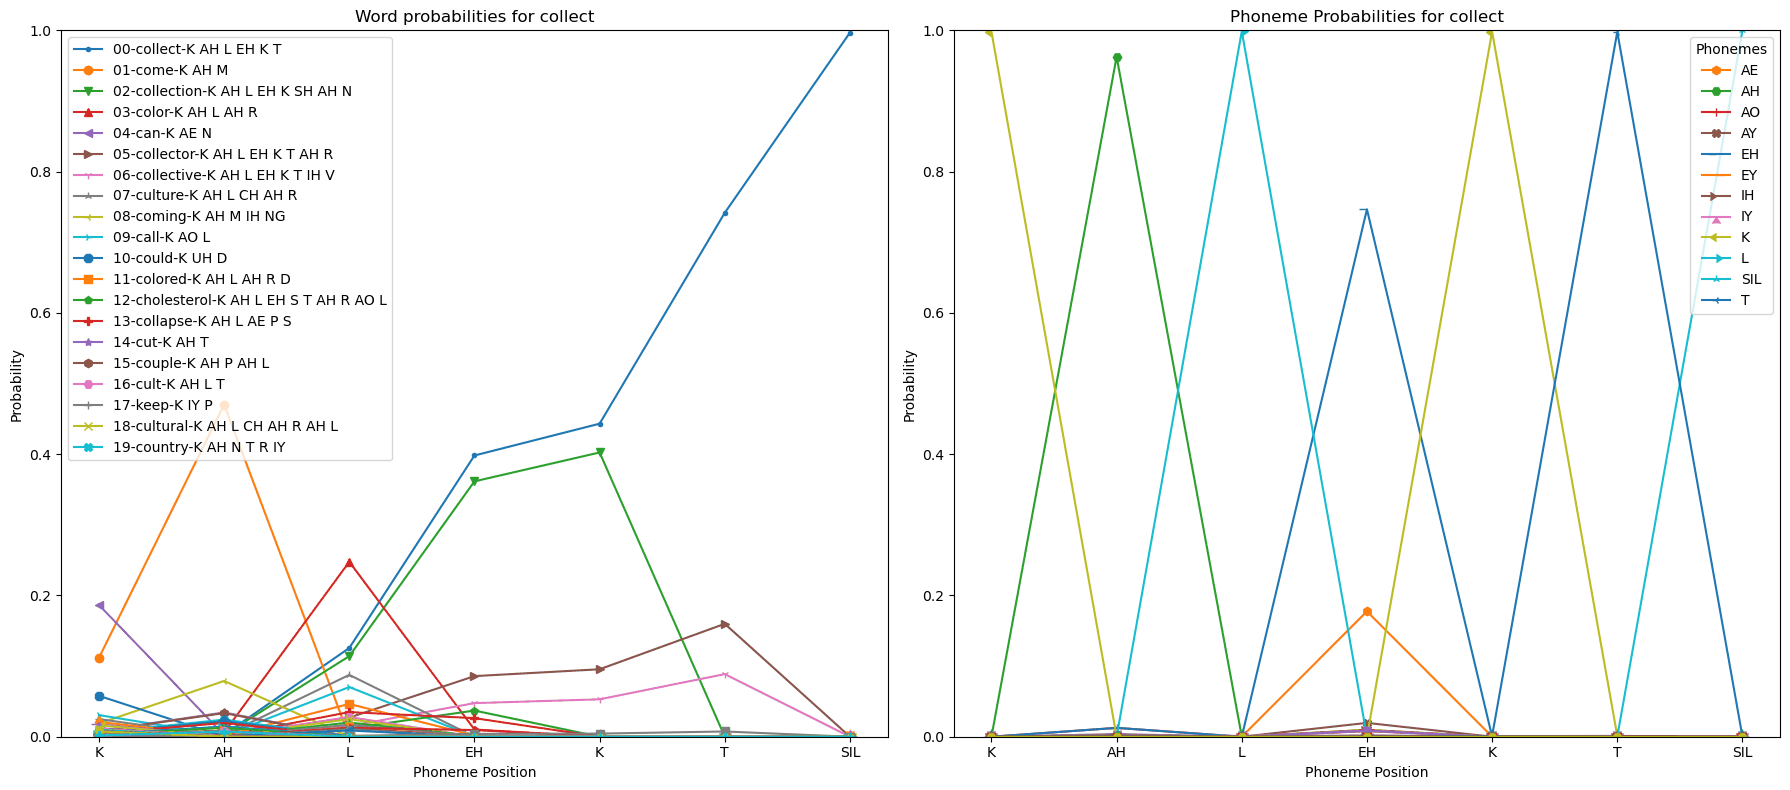

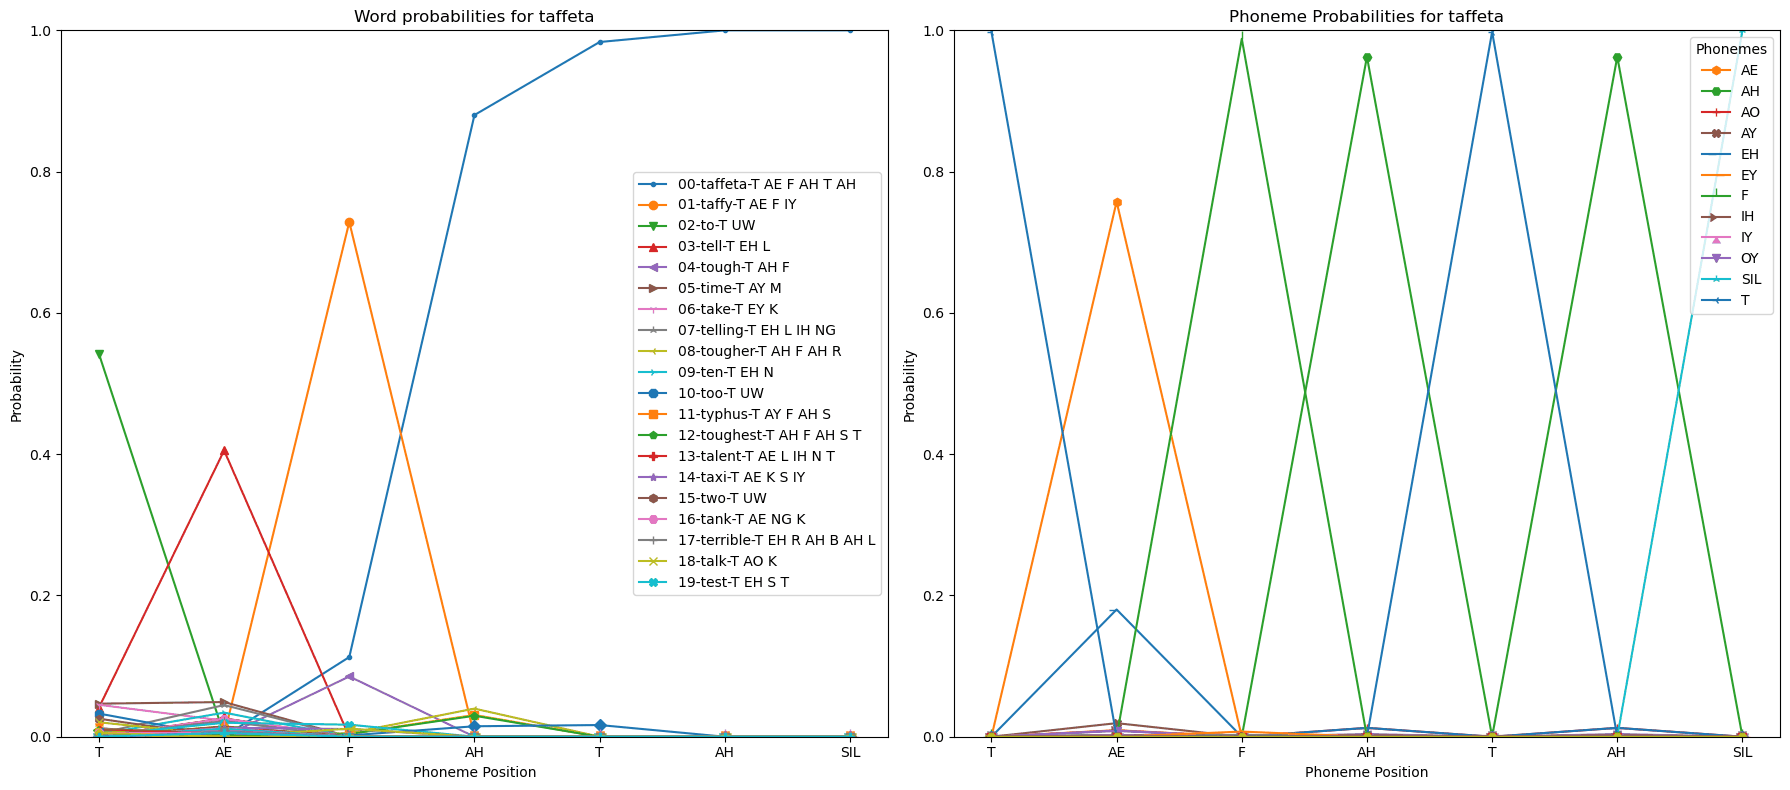

In [43]:
# Submitted by Jacob Johnson

import random
# Extract the "Item" column as a list of words
lexicon_words = lexicon_df['Item'].tolist()
# Use random.sample to select random keys
# Can change the # after the comma to select the desired sample size
word_list = random.sample(lexicon_words, 8)
aggregated_word_results, aggregated_phoneme_results = run_simulations(word_list, 
lexicon_df, phoneme_confusion_df, phoneme_prob_dict)
plot_simulation_result(aggregated_word_results, aggregated_phoneme_results, full_scale=True)


-------

## References

Allopenna, P. D., Magnuson, J. S., & Tanenhaus, M. K. (1998). Tracking the time course of spoken word recognition using eye movements: Evidence for continuous mapping models. *Journal of Memory and Language, 38*, 419-439.

Chater, N., & Manning, C. D. (2006). Probabilistic models of language processing and acquisition. *Trends in Cognitive Sciences, 10*(7), 335-344.

Cutler, A., Weber, A., Smits, R., & Cooper, N. (2004). Patterns of English phoneme confusions by native and non-native listeners. *Journal of the Acoustical Society of America, 116*(6), 3668-3678.

Ganong, W. F. (1980). Phonetic categorization in auditory word perception. *Journal of Experimental Psychology: Human Perception and Performance, 6*(1), 110-125.

Gigerenzer, G., & Hoffrage, U. (1995). How to improve Bayesian reasoning without instruction: Frequency formats. *Psychological Review, 102*(4), 684-704.

Goh, W. D., Yap, M. J., & Chee, Q. W. (2020). The Auditory English Lexicon Project: A multi-talker, multi-region psycholinguistic database of 10,170 spoken words and nonwords. *Behavior Research Methods, 52*, 2202-2231.

Khaitan, P., & McClelland, J. L. (2010). Matching exact posterior probabilities in the multinomial interactive activation model. In S. Ohlsson & R. Catrambone (Eds.), *Proceedings of the 32nd Annual Meeting of the Cognitive Science Society* (p. 623). Austin, TX: Cognitive Science Society.

Kriegeskorte, N., Mur, M., & Bandettini, P. (2008). Representational similarity analysis -- connecting the branches of systems neuroscience. *Frontiers in Systems Neuroscience, 2*, 4.

Li, Z., Crinnion, A. M., & Magnuson, J. S. (2022). LexFindR: A fast, simple, and extensible R package for finding similar words in a lexicon. *Behavior Research Methods, 54*, 1388-1402. https://doi.org/10.3758/s13428-021-01667-6

Luce, P. A. (1986). *Neighborhoods of words in the mental lexicon* (Research on Speech Perception, Technical Report No. 6; doctoral dissertation). Bloomington, IN: Speech Research Laboratory, Department of Psychology, Indiana University.

Luce, P. A., & Pisoni, D. B. (1998). Recognizing spoken words: The neighborhood activation model. *Ear and Hearing, 19*, 1-36.

Luce, R. D. (1959). *Individual choice behavior*. New York: Wiley.

Magnuson, J. S., & Crinnion, A. M. (2022). Spoken word recognition. In A. Papafragou, J. C. Trueswell, & L. R. Gleitman (Eds.), *The Oxford Handbook of the Mental Lexicon* (pp. 461-490). Oxford University Press.

McClelland, J. L. (1991). Stochastic interactive processes and the effect of context on perception. *Cognitive Psychology, 23*, 1-44.

McClelland, J. L. (2013). Integrating probabilistic models of perception and interactive neural networks: A historical and tutorial review. *Frontiers in Psychology, 4*, 503.

McClelland, J. L., Mirman, D., Bolger, D. J., & Khaitan, P. (2014). Interactive activation and mutual constraint satisfaction in perception and cognition. *Cognitive Science, 38*, 1139-1189.

Miller, G. A., & Nicely, P. E. (1955). An analysis of perceptual confusions among some English consonants. *Journal of the Acoustical Society of America, 27*(2), 338-352.

Norris, D., & McQueen, J. M. (2008). Shortlist B: A Bayesian model of continuous speech recognition. *Psychological Review, 115*(2), 357-395.

Norris, D., McQueen, J. M., & Cutler, A. (2000). Merging information in speech recognition: Feedback is never necessary. *Behavioral and Brain Sciences, 23*, 299-370.

Pearl, J. (1988). *Probabilistic reasoning in intelligent systems: Networks of plausible inference*. San Mateo, CA: Morgan Kaufmann.

Peterson, G. E., & Barney, H. L. (1952). Control methods used in a study of the vowels. *Journal of the Acoustical Society of America, 24*(2), 175-184.

Shepard, R. N. (1957). Stimulus and response generalization: A stochastic model relating generalization to distance in psychological space. *Psychometrika, 22*(4), 325-345.

Shepard, R. N. (1987). Toward a universal law of generalization for psychological science. *Science, 237*(4820), 1317-1323.

Smits, R., Warner, N., McQueen, J. M., & Cutler, A. (2003). Unfolding of phonetic information over time: A database of Dutch diphone perception. *Journal of the Acoustical Society of America, 113*(1), 563-574.